# Food Inspections — Análise Exploratória

## 1 · Estrutura — *de que são feitos estes dados?*

Inspeções sanitárias em estabelecimentos de alimentação da cidade de Chicago
(*Chicago Food Inspections*, portal de dados aberto da prefeitura).
Cada linha é **uma inspeção**, não um estabelecimento — o mesmo restaurante aparece
várias vezes ao longo dos anos.

Na etapa de estrutura, analisamos **quais são os tipos** e **quantos valores distintos** cada coluna tem.

> 📋 **Passo zero: o dicionário de dados.** As descrições abaixo vêm dos nomes das colunas
> e dos valores observados no próprio arquivo — o dicionário oficial está na página do
> dataset no Chicago Data Portal e deve ser conferido antes de fechar o relatório.
>
> | coluna | em português |
> |---|---|
> | `Inspection ID` | número da inspeção |
> | `DBA Name` · `AKA Name` | razão social (*doing business as*) · nome de fachada |
> | `License #` | número da licença do estabelecimento |
> | `Facility Type` | tipo de estabelecimento (restaurante, mercado, escola…) |
> | `Risk` | classificação de risco sanitário (1 alto · 2 médio · 3 baixo) |
> | `Address` · `City` · `State` · `Zip` | endereço · cidade · estado · CEP |
> | `Inspection Date` | data da inspeção |
> | `Inspection Type` | motivo da inspeção (rotina, licença, denúncia…) |
> | `Results` | **resultado da inspeção** — o alvo natural do projeto |
> | `Violations` | texto livre com as violações encontradas |
> | `Latitude` · `Longitude` · `Location` | coordenadas · o par (lat, lon) já formatado |

In [ ]:
import pandas as pd

URL = ("https://github.com/jkymie/food-inspections-eda/releases/download/"
       "dados-2026-09-24/food_inspections_2026-09-24.csv.gz")

df = pd.read_csv(URL, low_memory=False)

print(df.shape)
df.head()

(315963, 17)


,Inspection ID,DBA Name,AKA Name,License #,Facility Type,Risk,Address,City,State,Zip,Inspection Date,Inspection Type,Results,Violations,Latitude,Longitude,Location
0,1068208,CHINA COURT RESTAURANT,CHINA COURT RESTAURANT,2141795.0,Restaurant,Risk 1 (High),1146 N MILWAUKEE AVE,CHICAGO,IL,60642.0,03/14/2012,License Re-Inspection,Fail,18. NO EVIDENCE OF RODENT OR INSECT OUTER OPEN...,41.902462,-87.665306,"(41.902462266949634, -87.66530609467256)"
1,1072213,CUDDLE CARE,CUDDLE CARE,1622366.0,Daycare Above and Under 2 Years,Risk 1 (High),4800 S LAKE PARK AVE,CHICAGO,IL,60615.0,10/22/2012,Canvass,Pass,31. CLEAN MULTI-USE UTENSILS AND SINGLE SERVIC...,41.807922,-87.590693,"(41.80792179224785, -87.5906931090992)"
2,1072214,CUDDLE CARE,CUDDLE CARE,1622365.0,Daycare Above and Under 2 Years,Risk 1 (High),4800 S LAKE PARK AVE,CHICAGO,IL,60615.0,10/22/2012,Canvass,Pass,31. CLEAN MULTI-USE UTENSILS AND SINGLE SERVIC...,41.807922,-87.590693,"(41.80792179224785, -87.5906931090992)"
3,1072228,SHARKS FISH & CHICKEN,SHARKS FISH & CHICKEN,2069562.0,Restaurant,Risk 2 (Medium),101 E 51ST ST,CHICAGO,IL,60615.0,10/26/2012,Short Form Complaint,Pass,"34. FLOORS: CONSTRUCTED PER CODE, CLEANED, GOO...",41.801892,-87.622566,"(41.80189221533366, -87.62256558837282)"
4,1072252,SALAAM RESTAURANT AND BAKERY,SALAAM RESTAURANT AND BAKERY,2141327.0,Restaurant,Risk 1 (High),700-706 W 79TH ST,CHICAGO,IL,60620.0,01/24/2013,Canvass,Pass,33. FOOD AND NON-FOOD CONTACT EQUIPMENT UTENSI...,41.750787,-87.641667,"(41.750787498480555, -87.64166664542023)"


Esse dataset possui **315.963 linhas e 17 colunas.**

In [ ]:
df.info(verbose=True)     # tipo de cada coluna

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 315963 entries, 0 to 315962
Data columns (total 17 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   Inspection ID    315963 non-null  int64  
 1   DBA Name         315963 non-null  object 
 2   AKA Name         313539 non-null  object 
 3   License #        315944 non-null  float64
 4   Facility Type    310616 non-null  object 
 5   Risk             315876 non-null  object 
 6   Address          315963 non-null  object 
 7   City             315782 non-null  object 
 8   State            315888 non-null  object 
 9   Zip              315921 non-null  float64
 10  Inspection Date  315963 non-null  object 
 11  Inspection Type  315962 non-null  object 
 12  Results          315963 non-null  object 
 13  Violations       226883 non-null  object 
 14  Latitude         314912 non-null  float64
 15  Longitude        314912 non-null  float64
 16  Location         314912 non-null  obje

In [ ]:
df.dtypes.value_counts()        # quantas colunas de cada tipo

,count
object,12
float64,4
int64,1


**12 colunas de texto, 4 decimais e 1 inteira**

In [ ]:
cardinalidade = df.nunique().sort_values()     # quantos valores DIFERENTES cada coluna tem, sabendo que o dataset tem 315.963 linhas
cardinalidade

,0
Risk,4
State,7
Results,7
City,94
Inspection Type,110
Zip,139
Facility Type,527
Inspection Date,4213
Longitude,18952
Latitude,18952


📌 Primeiro achado — `Inspection ID`

`Inspection ID` tem **315.963 valores distintos**, exatamente o número de linhas. Isso **levanta a suspeita** de identificador — mas não prova. Então, agora vamos provar isso:

In [ ]:
print(df["Inspection ID"].head(3).tolist(), "...", df["Inspection ID"].tail(3).tolist())
print("mínimo:", df["Inspection ID"].min(), "| máximo:", df["Inspection ID"].max())

# é a sequência 1, 2, 3, ...?
seq = range(1, len(df) + 1)
print("é 1..n?", (df["Inspection ID"].sort_values().reset_index(drop=True) == seq).all())

[1068208, 1072213, 1072214] ... [2641591, 2641585, 2640587]
mínimo: 44247 | máximo: 2643194
é 1..n? False


**Não é a sequência 1..n** — vai de **44.247 a 2.643.194**, com buracos. Mesmo assim é identificador: um contador da prefeitura, com buracos porque nem toda inspeção emitida entra neste arquivo. Não tem unidade nem significado próprio.

→ **Decisão:** descartar como variável preditora; manter como **chave** para rastrear a linha até a fonte.

📌 O segundo achado — a coluna que parece ID mas não é

`License #` tem **49.130 valores distintos** em 315.963 linhas. Não é chave da linha —
é a chave do **estabelecimento**. É ela que responde "esta é a mesma padaria de 2019?".

In [ ]:
por_licenca = df["License #"].value_counts()
print("inspeções por licença — mediana:", por_licenca.median(),
      "| máximo:", por_licenca.max())
print("linhas com License # == 0:", (df["License #"] == 0).sum())
print("linhas com License # vazio:", df["License #"].isna().sum())

inspeções por licença — mediana: 3.0 | máximo: 833
linhas com License # == 0: 833
linhas com License # vazio: 19


Mediana de **3 inspeções por licença**. Mas o "máximo" de **833** é a licença **`0`** —
que não é uma licença, é um preenchimento para *"sem licença"*. Juntar essas 833 linhas
como se fossem o mesmo estabelecimento seria erro.

→ **Decisão:** tratar `License #` como **texto** (é código, não número) e `0` como ausente.

📌 Estrutura já entrega uma consequência de modelagem: com o mesmo estabelecimento repetido
em várias linhas, uma divisão treino/teste aleatória **vaza informação** de um lado para o
outro. A divisão tem de ser por licença ou por data.

### As colunas categóricas

Cinco colunas têm cardinalidade baixa o bastante para caber num `value_counts`. São elas
que descrevem a inspeção.

In [ ]:
for c in ["Risk", "Results", "State", "Inspection Type", "Facility Type"]:
    print(f"--- {c}  ({df[c].nunique()} valores distintos)")
    print(df[c].value_counts(dropna=False).head(6), end="\n\n")

--- Risk  (4 valores distintos)
Risk
Risk 1 (High)      235113
Risk 2 (Medium)     56135
Risk 3 (Low)        24545
NaN                    87
All                    83
Name: count, dtype: int64

--- Results  (7 valores distintos)
Results
Pass                  163532
Fail                   60842
Pass w/ Conditions     46875
Out of Business        25879
No Entry               14140
Not Ready               4599
Name: count, dtype: int64

--- State  (7 valores distintos)
State
IL     315864
NaN        75
IN         13
CA          5
WI          3
DC          1
Name: count, dtype: int64

--- Inspection Type  (110 valores distintos)
Inspection Type
Canvass                    163171
License                     42409
Canvass Re-Inspection       35185
Complaint                   29948
License Re-Inspection       12822
Complaint Re-Inspection     12536
Name: count, dtype: int64

--- Facility Type  (527 valores distintos)
Facility Type
Restaurant                      214378
Grocery Store           

Três leituras, e cada uma vira decisão:

- **`Results` (7 valores)** é o alvo natural — mas não é um sim/não. `Out of Business`,
  `No Entry`, `Not Ready` e `Business Not Located` (cerca de 44,7 mil linhas somadas)
  descrevem uma inspeção que **não aconteceu**. → **Decisão:** definir o alvo explicitamente;
  provavelmente `Pass`/`Pass w/ Conditions`/`Fail` e o resto fora.
- **`Risk` (4 valores)** é **ordinal** disfarçado de texto: alto > médio > baixo. O quarto
  valor é `All`, com 83 linhas — não pertence à escala. → **Decisão:** codificar a ordem 1‑2‑3
  e tratar `All` à parte.
- **`Facility Type` (527 valores)** tem cauda longa: `Restaurant` é 68% das linhas e centenas
  de tipos aparecem meia dúzia de vezes, com grafias livres. → **Decisão:** agrupar os raros
  em `Outros`.

E `State`: **315.864 de 315.963 linhas são `IL`**. Uma coluna praticamente constante não
distingue nada. → **Decisão:** descartar (as poucas linhas fora de IL são suspeitas de erro
de digitação, a conferir no passo de qualidade).

In [ ]:
df["City"].value_counts(dropna=False).head(8)

,count
City,
CHICAGO,314653
Chicago,536
NaN,181
chicago,175
CCHICAGO,62
SCHAUMBURG,30
EVANSTON,28
CHicago,22


`City` tem **94 valores distintos** — mas não são 94 cidades. `CHICAGO`, `Chicago`,
`chicago`, `CHicago`, `CCHICAGO`, `CHICAGOCHICAGO`… são a mesma cidade escrita de jeitos
diferentes.

📌 **A cardinalidade fez a pergunta certa de novo.** 94 é alto demais para um dataset de
uma cidade só — e olhar os valores mostra por quê.

→ **Decisão:** precisamos normalizar (maiúsculas, espaços) antes de qualquer contagem por cidade.

### Os tipos que mentem

`df.info()` mostra o tipo que o pandas **adivinhou** — e ele erra quando o dado é código
ou data guardados como número/texto.

In [ ]:
print("Zip             ->", df["Zip"].dtype, "| ex.:", df["Zip"].dropna().head(2).tolist())
print("Inspection Date ->", df["Inspection Date"].dtype, "| ex.:", df["Inspection Date"].head(2).tolist())
print("Location        ->", df["Location"].dtype, "| ex.:", df["Location"].head(1).tolist())

Zip             -> float64 | ex.: [60642.0, 60615.0]
Inspection Date -> object | ex.: ['03/14/2012', '10/22/2012']
Location        -> object | ex.: ['(41.902462266949634, -87.66530609467256)']


Três erros de tipo, três decisões:

| coluna | o pandas leu como | o que é | decisão |
|---|---|---|---|
| `Zip` | `float64` | **código** de CEP dos EUA (vira `60623.0`) | ler como texto |
| `Inspection Date` | texto | **data** | `pd.to_datetime(..., format="%m/%d/%Y")` |
| `Location` | texto | o par `(lat, lon)` que já existe em duas colunas | descartar (ver abaixo) |


In [ ]:
datas = pd.to_datetime(df["Inspection Date"], format="%m/%d/%Y", errors="coerce")
print("de", datas.min().date(), "até", datas.max().date(),
      "| falhas na conversão:", datas.isna().sum())

de 2010-01-04 até 2026-09-23 | falhas na conversão: 0


### A coluna redundante

`Location` parece uma terceira informação geográfica, já que sabemos que temos as colunas `Latitude` e `Longitude`. Então, com isso, vamos conferir:

In [ ]:
import numpy as np

com_coord = df.dropna(subset=["Location"])
partes = com_coord["Location"].str.strip("()").str.split(", ", expand=True).astype(float)

print("Location bate com Latitude :", np.isclose(partes[0], com_coord["Latitude"]).all())
print("Location bate com Longitude:", np.isclose(partes[1], com_coord["Longitude"]).all())
print("some junto com Latitude    :", (df["Location"].isna() == df["Latitude"].isna()).all())

Location bate com Latitude : True
Location bate com Longitude: True
some junto com Latitude    : True


**Bate nas três verificações.** `Location` é `Latitude` e `Longitude` coladas num texto —
e some exatamente nas mesmas 1.051 linhas.

→ **Decisão:** descartar `Location`.

### Visão geral da estrutura do dataset

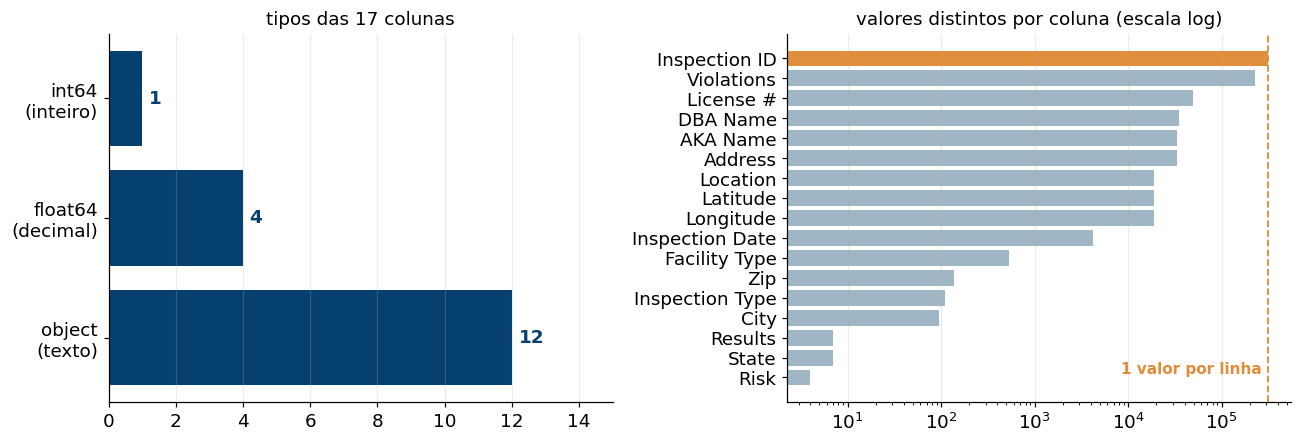

In [ ]:
import matplotlib.pyplot as plt
from pathlib import Path

FIGS = Path("figuras"); FIGS.mkdir(exist_ok=True)
plt.rcParams.update({
    "font.size": 12, "axes.titlesize": 12, "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": .25,
})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))

tipos = df.dtypes.value_counts()
nomes = {"str": "texto", "object": "texto", "int64": "inteiro", "float64": "decimal"}
ax1.barh([f"{t}\n({nomes.get(str(t), '')})" for t in tipos.index], tipos.values, color="#06406F")
for i, v in enumerate(tipos.values):
    ax1.text(v + .2, i, str(v), va="center", color="#06406F", fontweight="bold")
ax1.set_xlim(0, 15); ax1.set_title("tipos das 17 colunas"); ax1.grid(axis="y", alpha=0)

# escala log: de 4 (Risk) a 315.963 (Inspection ID) não cabe em escala linear
card = df.nunique().sort_values()
cores = ["#E08D3C" if n == "Inspection ID" else "#9FB6C4" for n in card.index]
ax2.barh(card.index, card.values, color=cores)
ax2.set_xscale("log")
ax2.axvline(len(df), color="#E08D3C", ls="--", lw=1.2)
ax2.text(len(df) * .85, .2, "1 valor por linha", color="#E08D3C",
         fontweight="bold", ha="right", fontsize=10)
ax2.set_title("valores distintos por coluna (escala log)"); ax2.grid(axis="y", alpha=0)

plt.tight_layout()
plt.savefig(FIGS / "fi-01-estrutura.png", dpi=200, bbox_inches="tight")   # ANTES do show()
plt.show()

---
## Conclusão da Estrutura

- **315.963 linhas × 17 colunas**; 12 de texto, 4 decimais, 1 inteira;
- A unidade da linha é a **inspeção**, e não o estabelecimento.

| achado | decisão |
|---|---|
| `Inspection ID` tem 1 valor por linha (iniciando de 44.247–2.643.194, com buracos) | descartar como preditor; manter como chave |
| `License #` = 49.130 estabelecimentos em 315.963 linhas; `0` usado como "sem licença" (831 linhas) | ler como texto; `0` vira ausente; **dividir treino/teste por licença ou por data**, nunca aleatório |
| `Location` é `Latitude`+`Longitude` em texto | descartar |
| `State` é `IL` em 315.864 de 315.963 linhas | descartar (quase constante) |
| `Zip` lido como `float64`; `Inspection Date` lida como texto | ler CEP como texto; converter a data (`%m/%d/%Y`) — cobre 04/01/2010 a 23/09/2026 |
| `City` tem 94 valores para uma cidade só (`Chicago`, `chicago`, `CCHICAGO`…) | normalizar antes de agrupar |
| `Risk` é ordinal (alto/médio/baixo) + 83 linhas `All` | codificar a ordem; tratar `All` à parte |
| `Facility Type` tem 527 valores, `Restaurant` = 68% | agrupar a cauda em `Outros` |
| `Results` tem 7 valores, dos quais 4 (≈44,7 mil linhas) são "inspeção não realizada" | definir o alvo explicitamente antes de modelar |

---
## 2 · Qualidade — *dá para confiar?*

In [ ]:
df_q = df.copy(deep=True)

data_extracao = pd.Timestamp("2026-09-24")

print(f"Linhas: {df_q.shape[0]:,}")
print(f"Colunas: {df_q.shape[1]}")
print(f"Data da análise: {data_extracao.date()}")

Linhas: 315,963
Colunas: 17
Data da análise: 2026-09-24


In [ ]:
resumo_vazios = pd.DataFrame({
    "faltantes": df_q.isna().sum(),
    "percentual_faltante": (df_q.isna().mean() * 100).round(2),
    "valores_distintos": df_q.nunique(dropna=True),
    "tipo_atual": df_q.dtypes.astype(str)
}).sort_values("faltantes", ascending=False)

colunas_com_vazio = resumo_vazios[
    resumo_vazios["faltantes"] > 0
]

display(colunas_com_vazio)

,faltantes,percentual_faltante,valores_distintos,tipo_atual
Violations,89080,28.19,225170,object
Facility Type,5347,1.69,527,object
AKA Name,2424,0.77,33450,object
Longitude,1051,0.33,18952,float64
Location,1051,0.33,18952,object
Latitude,1051,0.33,18952,float64
City,181,0.06,94,object
Risk,87,0.03,4,object
State,75,0.02,7,object
Zip,42,0.01,139,float64


In [ ]:
marcadores_de_vazio = {
    "",
    "nan",
    "null",
    "none",
    "n/a",
    "na",
    "unknown"
}

contagem_marcadores = {}

for coluna in df_q.select_dtypes(include="object").columns:
    valores = (
        df_q[coluna]
        .dropna()
        .astype(str)
        .str.strip()
        .str.lower()
    )

    contagem_marcadores[coluna] = int(
        valores.isin(marcadores_de_vazio).sum()
    )

marcadores_textuais = (
    pd.Series(
        contagem_marcadores,
        name="possiveis_vazios_escritos"
    )
    .sort_values(ascending=False)
)

display(
    marcadores_textuais[
        marcadores_textuais > 0
    ].to_frame()
)

,possiveis_vazios_escritos
DBA Name,3
Address,3


In [ ]:
duplicatas_exatas = int(df_q.duplicated().sum())

ids_repetidos = int(
    df_q["Inspection ID"]
    .duplicated(keep=False)
    .sum()
)

print("Linhas completamente idênticas:", duplicatas_exatas)
print("Linhas com Inspection ID repetido:", ids_repetidos)

Linhas completamente idênticas: 0
Linhas com Inspection ID repetido: 0


In [ ]:
licenca_valida = (
    df_q["License #"].notna()
    & df_q["License #"].ne(0)
)

chave_suspeita = [
    "License #",
    "Inspection Date",
    "Inspection Type"
]

mascara_suspeita = (
    licenca_valida
    & df_q.duplicated(chave_suspeita, keep=False)
)

possiveis_duplicatas = (
    df_q.loc[
        mascara_suspeita,
        [
            "Inspection ID",
            "License #",
            "DBA Name",
            "Inspection Date",
            "Inspection Type",
            "Results"
        ]
    ]
    .sort_values(chave_suspeita)
)

print(
    "Linhas com a mesma licença, data e tipo de inspeção:",
    len(possiveis_duplicatas)
)

display(possiveis_duplicatas.head(20))

Linhas com a mesma licença, data e tipo de inspeção: 2757


,Inspection ID,License #,DBA Name,Inspection Date,Inspection Type,Results
167333,1965749,241.0,HARD WATER BAR & GRILL,09/30/2016,Canvass,No Entry
168335,1965752,241.0,HOP HAUS ROGERS PARK,09/30/2016,Canvass,No Entry
229924,1092541,349.0,CLOVER CORP,08/09/2013,Canvass,Pass w/ Conditions
231233,1092549,349.0,KELLY'S PUB,08/09/2013,Canvass,Pass w/ Conditions
269630,543349,1362.0,MONTESSORI OF ENGLEWOOD,05/04/2011,Canvass,Pass
270090,166390,1362.0,JEWEL FOOD STORE #3232,05/04/2011,Canvass,Out of Business
34433,1965764,1392.0,JEWEL FOOD STORE #1296,09/30/2016,Complaint Re-Inspection,Fail
45356,1965672,1392.0,JEWEL FOOD STORE #1296,09/30/2016,Complaint Re-Inspection,Fail
126511,2129732,1491.0,BLACKIE'S,12/27/2017,Canvass,Out of Business
143013,2129733,1491.0,HALF SOUR,12/27/2017,Canvass,Pass w/ Conditions


In [ ]:
for coluna in ["Risk", "Results", "State"]:
    print(f"\n--- {coluna} ---")

    display(
        df_q[coluna]
        .value_counts(dropna=False)
        .rename("linhas")
        .to_frame()
    )


--- Risk ---


,linhas
Risk,
Risk 1 (High),235113
Risk 2 (Medium),56135
Risk 3 (Low),24545
NaN,87
All,83



--- Results ---


,linhas
Results,
Pass,163532
Fail,60842
Pass w/ Conditions,46875
Out of Business,25879
No Entry,14140
Not Ready,4599
Business Not Located,96



--- State ---


,linhas
State,
IL,315864
NaN,75
IN,13
CA,5
WI,3
DC,1
CO,1
NY,1


In [ ]:
cidade_normalizada = (
    df_q["City"]
    .astype("string")
    .str.strip()
    .str.upper()
)

print("Antes da normalização:")
display(
    df_q["City"]
    .value_counts(dropna=False)
    .head(15)
    .rename("linhas")
    .to_frame()
)

print("Depois de retirar espaços e padronizar maiúsculas:")
display(
    cidade_normalizada
    .value_counts(dropna=False)
    .head(15)
    .rename("linhas")
    .to_frame()
)

print(
    "Linhas com License # igual a zero:",
    int(df_q["License #"].eq(0).sum())
)

Antes da normalização:


,linhas
City,
CHICAGO,314653
Chicago,536
NaN,181
chicago,175
CCHICAGO,62
SCHAUMBURG,30
EVANSTON,28
CHicago,22
MAYWOOD,15


Depois de retirar espaços e padronizar maiúsculas:


,linhas
City,
CHICAGO,315386
<NA>,181
CCHICAGO,62
SCHAUMBURG,30
EVANSTON,28
MAYWOOD,16
ELK GROVE VILLAGE,13
CHICAGOCHICAGO,12
OAK PARK,12


Linhas com License # igual a zero: 833


In [ ]:
datas = pd.to_datetime(
    df_q["Inspection Date"],
    format="%m/%d/%Y",
    errors="coerce"
)

zip_numerico = pd.to_numeric(
    df_q["Zip"],
    errors="coerce"
)

latitude = pd.to_numeric(
    df_q["Latitude"],
    errors="coerce"
)

longitude = pd.to_numeric(
    df_q["Longitude"],
    errors="coerce"
)

datas_invalidas = int(datas.isna().sum())

datas_futuras = int(
    (datas > data_extracao).sum()
)

zips_fora_do_dominio = int(
    (
        zip_numerico.notna()
        & (
            (zip_numerico < 10000)
            | (zip_numerico > 99999)
        )
    ).sum()
)

zips_com_decimal = int(
    (
        zip_numerico.notna()
        & (zip_numerico % 1 != 0)
    ).sum()
)

coordenadas_fora_do_dominio = int(
    (
        latitude.notna()
        & ~latitude.between(-90, 90)
    ).sum()
    +
    (
        longitude.notna()
        & ~longitude.between(-180, 180)
    ).sum()
)

coordenadas_parciais = int(
    (latitude.isna() ^ longitude.isna()).sum()
)

print("Menor data válida:", datas.min())
print("Maior data válida:", datas.max())
print("Datas inválidas:", datas_invalidas)
print("Datas futuras:", datas_futuras)
print("CEPs fora do intervalo de 5 dígitos:", zips_fora_do_dominio)
print("CEPs com parte decimal diferente de zero:", zips_com_decimal)
print("Coordenadas fora do domínio:", coordenadas_fora_do_dominio)
print("Linhas com apenas uma coordenada presente:", coordenadas_parciais)

Menor data válida: 2010-01-04 00:00:00
Maior data válida: 2026-09-23 00:00:00
Datas inválidas: 0
Datas futuras: 0
CEPs fora do intervalo de 5 dígitos: 0
CEPs com parte decimal diferente de zero: 0
Coordenadas fora do domínio: 0
Linhas com apenas uma coordenada presente: 0


In [ ]:
colunas_geograficas = [
    "Latitude",
    "Longitude",
    "Location"
]

padrao_geografico = (
    df_q[colunas_geograficas]
    .isna()
    .value_counts(dropna=False)
    .rename("linhas")
    .reset_index()
)

display(padrao_geografico)

,Latitude,Longitude,Location,linhas
0,False,False,False,314912
1,True,True,True,1051


In [ ]:
violacoes_por_resultado = (
    df_q.groupby(
        "Results",
        dropna=False
    )
    .agg(
        linhas=("Inspection ID", "size"),
        violacoes_faltantes=(
            "Violations",
            lambda serie: serie.isna().sum()
        ),
        percentual_sem_violacoes=(
            "Violations",
            lambda serie: round(
                serie.isna().mean() * 100,
                2
            )
        )
    )
    .sort_values("linhas", ascending=False)
)

display(violacoes_por_resultado)

,linhas,violacoes_faltantes,percentual_sem_violacoes
Results,,,
Pass,163532,40671,24.87
Fail,60842,3648,6.00
Pass w/ Conditions,46875,948,2.02
Out of Business,25879,25835,99.83
No Entry,14140,13365,94.52
Not Ready,4599,4517,98.22
Business Not Located,96,96,100.00


In [ ]:
decisoes_qualidade = pd.DataFrame([
    {
        "problema": "License # igual a zero",
        "interpretacao": "Código usado para estabelecimento sem licença",
        "decisao_prevista": "Converter zero para ausente e tratar a coluna como identificador"
    },
    {
        "problema": "Grafias diferentes em City",
        "interpretacao": "Diferenças de maiúsculas e espaços",
        "decisao_prevista": "Remover espaços e converter o texto para maiúsculas"
    },
    {
        "problema": "Zip armazenado como decimal",
        "interpretacao": "CEP é código, não medida numérica",
        "decisao_prevista": "Validar e converter para texto"
    },
    {
        "problema": "Location repete latitude e longitude",
        "interpretacao": "Informação geográfica redundante",
        "decisao_prevista": "Manter latitude e longitude e descartar Location"
    },
    {
        "problema": "Risk com All ou ausente",
        "interpretacao": "Valores fora da escala Risk 1, Risk 2 e Risk 3",
        "decisao_prevista": "Investigar e tratar separadamente; não imputar automaticamente"
    },
    {
        "problema": "Results sem inspeção sanitária concluída",
        "interpretacao": "Out of Business, No Entry, Not Ready e Business Not Located não são aprovação ou falha",
        "decisao_prevista": "Excluir da definição do alvo após decisão do grupo"
    },
    {
        "problema": "Possíveis duplicatas",
        "interpretacao": "Repetição pode ser erro ou inspeção legítima",
        "decisao_prevista": "Remover somente duplicatas comprovadas"
    }
])

display(decisoes_qualidade)

,problema,interpretacao,decisao_prevista
0,License # igual a zero,Código usado para estabelecimento sem licença,Converter zero para ausente e tratar a coluna ...
1,Grafias diferentes em City,Diferenças de maiúsculas e espaços,Remover espaços e converter o texto para maiús...
2,Zip armazenado como decimal,"CEP é código, não medida numérica",Validar e converter para texto
3,Location repete latitude e longitude,Informação geográfica redundante,Manter latitude e longitude e descartar Location
4,Risk com All ou ausente,"Valores fora da escala Risk 1, Risk 2 e Risk 3",Investigar e tratar separadamente; não imputar...
5,Results sem inspeção sanitária concluída,"Out of Business, No Entry, Not Ready e Busines...",Excluir da definição do alvo após decisão do g...
6,Possíveis duplicatas,Repetição pode ser erro ou inspeção legítima,Remover somente duplicatas comprovadas


In [ ]:
print("CONCLUSÃO DA QUALIDADE")
print("-" * 50)

print(
    f"{len(colunas_com_vazio)} das {df_q.shape[1]} colunas "
    "possuem pelo menos um valor ausente."
)

print(
    f"Foram encontradas {duplicatas_exatas} linhas "
    "completamente idênticas."
)

print(
    f"Foram encontradas {ids_repetidos} linhas com "
    "Inspection ID repetido."
)

print(
    f"Existem {len(possiveis_duplicatas)} linhas com a mesma "
    "licença, data e tipo de inspeção; elas precisam ser "
    "investigadas antes de qualquer remoção."
)

print(
    f"Existem {datas_invalidas} datas que não puderam ser "
    f"convertidas e {datas_futuras} datas futuras."
)

print(
    "\nAs principais necessidades previstas são: normalizar "
    "categorias de texto, converter CEP e licença para códigos, "
    "investigar os mecanismos dos valores ausentes e remover "
    "somente duplicatas comprovadas."
)

CONCLUSÃO DA QUALIDADE
--------------------------------------------------
12 das 17 colunas possuem pelo menos um valor ausente.
Foram encontradas 0 linhas completamente idênticas.
Foram encontradas 0 linhas com Inspection ID repetido.
Existem 2757 linhas com a mesma licença, data e tipo de inspeção; elas precisam ser investigadas antes de qualquer remoção.
Existem 0 datas que não puderam ser convertidas e 0 datas futuras.

As principais necessidades previstas são: normalizar categorias de texto, converter CEP e licença para códigos, investigar os mecanismos dos valores ausentes e remover somente duplicatas comprovadas.


### Conclusão da qualidade

O dataset possui 315.963 inspeções e apresenta boa integridade estrutural: não foram encontradas linhas completamente duplicadas, `Inspection ID` repetidos, datas inválidas, datas futuras, CEPs impossíveis ou coordenadas fora do domínio.

Das 17 colunas, 12 apresentam algum valor ausente. A maior ausência está em `Violations`, com 89.080 linhas (28,19%). Essa ausência não ocorre ao acaso: ela está presente em quase todos os registros nos quais a inspeção não foi concluída, mas em apenas 6% dos resultados `Fail` e 2,02% dos resultados `Pass w/ Conditions`. Portanto, em muitos casos o vazio significa “não se aplica”, e não perda aleatória de informação.

`Facility Type` possui 5.347 ausências (1,69%) e deverá ser investigada antes de qualquer preenchimento. `AKA Name` pode estar ausente simplesmente porque o estabelecimento não possui nome alternativo. As 1.051 ausências de `Latitude`, `Longitude` e `Location` ocorrem exatamente nas mesmas linhas, indicando um único problema de geocodificação.

Foram encontradas 2.757 linhas com a mesma licença, data e tipo de inspeção. Como não existem linhas idênticas nem `Inspection ID` repetidos, esses casos não serão removidos automaticamente: podem representar inspeções legítimas ou estabelecimentos diferentes associados à mesma licença.

Também foram encontradas inconsistências categóricas. `City` possui diferenças de maiúsculas, espaços e erros de digitação; `Risk` contém 83 registros `All`, fora da escala de risco 1–3; e 24 registros apresentam estados diferentes de Illinois. Esses casos precisam ser normalizados ou investigados.

As decisões previstas são normalizar categorias textuais, converter `Zip` e `License #` para códigos, transformar licença zero em ausente, descartar `Location` por redundância, investigar as ausências de `Facility Type` e remover somente duplicatas comprovadas.

---
## 3 · Distribuições — *que forma tem cada variável?*

Objetivo : prever o fail. Analisemos, então, o alvo : Results


In [ ]:
print(
    df["Results"]
    .value_counts(normalize=True, dropna=False)
    .round(3)
)

Results
Pass                    0.518
Fail                    0.193
Pass w/ Conditions      0.148
Out of Business         0.082
No Entry                0.045
Not Ready               0.015
Business Not Located    0.000
Name: proportion, dtype: float64


Análise do número de inspeções por estabelecimento.

In [ ]:
licencas_validas = df["License #"].replace(0, pd.NA)

insp_por_lic = licencas_validas.value_counts()

print(f"média   : {insp_por_lic.mean():.2f}")
print(f"mediana : {insp_por_lic.median():.0f}")
print(f"skew    : {insp_por_lic.skew():.2f}")

média   : 6.41
mediana : 3
skew    : 2.59


A média é de 6.41, mais do que o dobro da mediana (3). A assimetira (*skew*) é de 2.59 : indicando uma cauda à direita.
É preferível descrever o estabelecimento típico utilizando a mediana (Média > Mediana e assemetria elevada -> uma minoria de estabelecimentos puxa a média para cima). Metade dos estabelecimentos situa-se abaixo de 3 ; portanto, utilizar a média não reflete a realidade.


In [ ]:
q1, q3 = insp_por_lic.quantile([.25, .75])
iqr = q3 - q1
sup = q3 + 1.5*iqr
print("limite superior :", sup)
print("suspeitos :", (insp_por_lic > sup).sum())

limite superior : 21.0
suspeitos : 2652


2652 estabelecimentos suspeitos em aproximadamente 49100. Ultrapassam o limite, são 5,4%.
O limite Q3 + 1.5xIQR = 21 inspeções, sendo 2652 estabelecimentos ultrapassam esse limite. Essa regra supõe uma distribuição ~ simétrica. Com skew alto, é normal que tenha muitos suspeitos. Há estabelecimentos inspecionados com muita frequência (redes grandes ou historicamente problemáticas por exemplo). Suspeito não significa erro.

Análise do "facility type"

In [ ]:
vc = df["Facility Type"].value_counts()
print((vc.head(10).sum() / len(df)).round(2))
print((vc < 50).sum(), "tipos com menos de 50 ocorrencias")

0.94
486 tipos com menos de 50 ocorrencias


Os 10 tipos mais frequentes representam 94% do total de tipos. 486 dos 527 tipos aparecem menos de 50 vezes.
Decisão: agrupar, se necessário, os tipos pouco representados em uma categoria "Outros", a fim de garantir um sinal estatístico suficiente.


"Canvass" é a inspeção de rotina.

In [ ]:
print(df["Inspection Type"].value_counts(normalize=True).head(10).round(3))

Inspection Type
Canvass                     0.516
License                     0.134
Canvass Re-Inspection       0.111
Complaint                   0.095
License Re-Inspection       0.041
Complaint Re-Inspection     0.040
Short Form Complaint        0.029
Non-Inspection              0.018
Suspected Food Poisoning    0.003
Consultation                0.002
Name: proportion, dtype: float64


"Canvass" representa 51% das linhas: trata-se da inspeção de rotina que vamos analisar (o estabelecimento passará com sucesso pela próxima inspeção de rotina?).

>
> | Achado | Decisao |
> |---|---|
> | `Results : 4 valores sem resultado sanitário` | Restringir a Pass/Fail/Pass w/Condition/Fail |
> | `Média (6,41) > mediana (3), assimetria 2,59`| ADescrever o estabelecimento típico pela mediana |
> | `2.652 estabelecimentos suspeitos (5,4%)` | Manter: são casos legítimos |
> | `Facility Type: 10 tipos = 94% das inspeções` | Agrupar os tipos pouco representados em "Outros" |
> | `Inspection Type: Canvass = 51,6%` | Manter apenas Canvass, que representa o objetivo |



---
## 4 · Correlação — *quais variáveis andam juntas?*

**Objetivo desta etapa:** descobrir quais variáveis andam junto com o **Fail** (sinal para o modelo) e quais andam juntas entre si (redundância, que vai guiar a seleção de features).

**Recorte usado** (decidido na seção 3): só inspeções **Canvass**, com `Results` em Pass, Pass w/ Conditions ou Fail. Alvo binário: `fail = 1` quando `Results == "Fail"`.

Cada tipo de par pede uma medida diferente:

| par | medida | por quê |
|---|---|---|
| numérica × numérica ou × alvo | Spearman | usa postos: aguenta assimetria e outliers (vimos skew alto na seção 3) |
| categórica × alvo | taxa de Fail por categoria (`groupby`, como na a03) | Pearson não faz sentido para categorias sem ordem |
| categórica × categórica | Cramér's V (0 a 1), como aprofundamento | resume a força da associação num número só |

In [ ]:
import seaborn as sns
from matplotlib.ticker import PercentFormatter
from scipy.stats import chi2_contingency

base = df.copy()

base["License #"] = base["License #"].replace(0, pd.NA)

base["data"] = pd.to_datetime(
    base["Inspection Date"],
    format="%m/%d/%Y"
)

hist = (base.dropna(subset=["License #"]).sort_values(["License #", "data", "Inspection ID"]).copy())
hist["_fail"] = (hist["Results"] == "Fail").astype(int)
g = hist.groupby("License #")
hist["insp_anteriores"] = g.cumcount()
hist["fails_anteriores"] = g["_fail"].cumsum() - hist["_fail"]
hist["fail_anterior"] = g["_fail"].shift()
hist["dias_desde_ultima"] = g["data"].diff().dt.days

rotina = hist[hist["Inspection Type"].str.strip().str.upper().eq("CANVASS")
              & hist["Results"].isin(["Pass", "Pass w/ Conditions", "Fail"])]
hist["fail_ultima_rotina"] = rotina.groupby("License #")["_fail"].shift()
hist["taxa_fail_hist"] = hist["fails_anteriores"] / hist["insp_anteriores"].replace(0, np.nan)
cols_hist = ["insp_anteriores", "fails_anteriores", "fail_anterior", "dias_desde_ultima",
             "fail_ultima_rotina", "taxa_fail_hist"]
base[cols_hist] = hist[cols_hist]

ok = (base["Inspection Type"].str.strip().str.upper().eq("CANVASS")
      & base["Results"].isin(["Pass", "Pass w/ Conditions", "Fail"]))
d = base.loc[ok].copy()
d["fail"] = (d["Results"] == "Fail").astype(int)

d["risco"] = d["Risk"].map({"Risk 1 (High)": 1, "Risk 2 (Medium)": 2, "Risk 3 (Low)": 3})
d["risco_txt"] = d["Risk"].fillna("SEM RISCO")
d["ano"] = d["data"].dt.year
d["mes"] = d["data"].dt.month
d["dia_semana"] = d["data"].dt.dayofweek
d["n_violacoes"] = d["Violations"].str.count(r" \| ").add(1).fillna(0)
ft = d["Facility Type"].str.strip().str.upper().fillna("DESCONHECIDO")
d["tipo_estab"] = ft.where(ft.isin(ft.value_counts().head(10).index), "OUTROS")
d["zip"] = d["Zip"].map(lambda z: f"{z:.0f}" if pd.notna(z) else "SEM ZIP")

print(f"{len(d):,} inspeções Canvass com resultado sanitário")
print(f"taxa de Fail: {d['fail'].mean():.1%}")

132,088 inspeções Canvass com resultado sanitário
taxa de Fail: 22.6%


### 4.1 · Variáveis numéricas (Spearman)

`n_violacoes` entra só como **controle de vazamento**: o número de violações é anotado *durante* a inspeção, então ele praticamente descreve o próprio resultado. Se ele aparecer muito correlacionado com `fail`, isso confirma que a coluna `Violations` não pode ser usada como preditora da mesma inspeção.

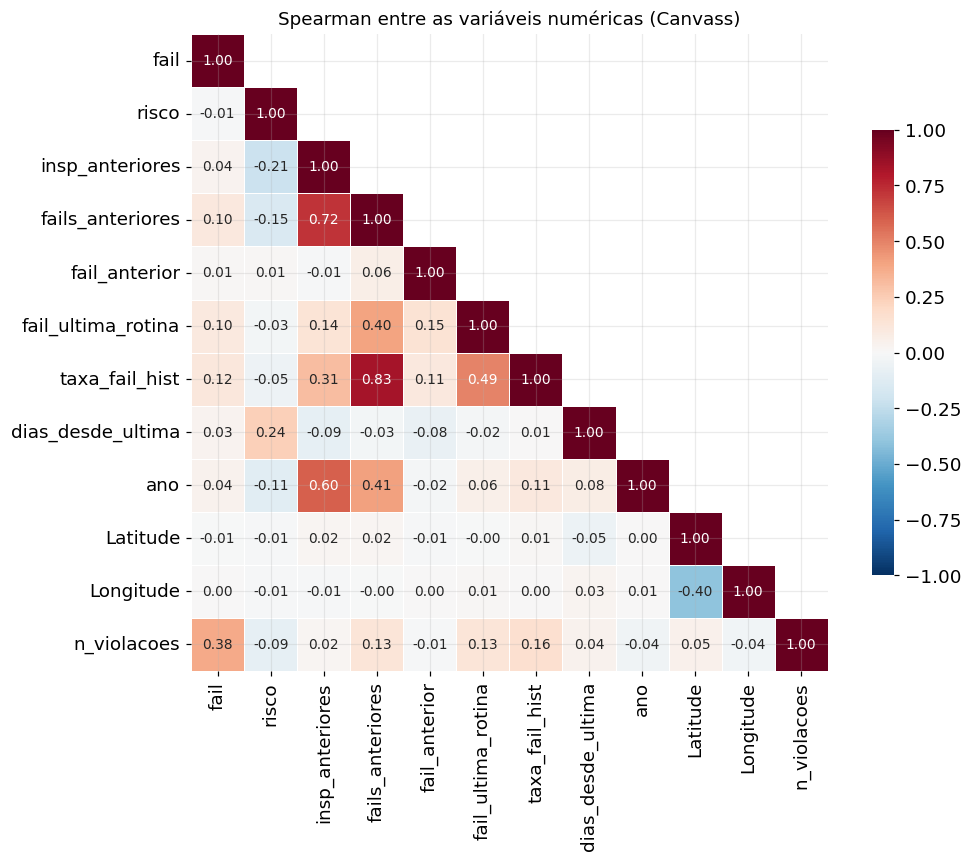

In [ ]:
num = ["fail", "risco", "insp_anteriores", "fails_anteriores", "fail_anterior",
       "fail_ultima_rotina", "taxa_fail_hist",
       "dias_desde_ultima", "ano", "Latitude", "Longitude", "n_violacoes"]
corr = d[num].corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            center=0, square=True, linewidths=.5, cbar_kws={"shrink": .7},
            annot_kws={"size": 9}, ax=ax)
ax.set_title("Spearman entre as variáveis numéricas (Canvass)")
plt.tight_layout()
plt.savefig(FIGS / "fi-04-spearman.png", dpi=200, bbox_inches="tight")
plt.show()

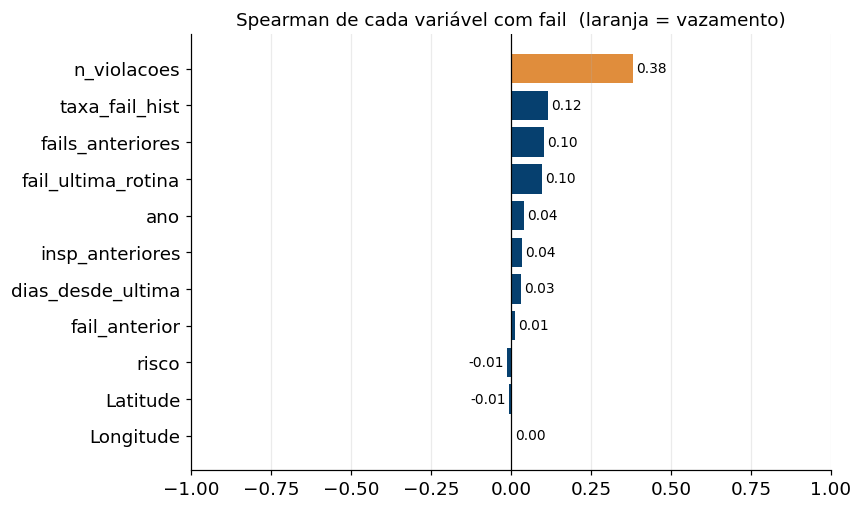

n_violacoes           0.380
taxa_fail_hist        0.116
fails_anteriores      0.104
fail_ultima_rotina    0.097
ano                   0.041
insp_anteriores       0.036
dias_desde_ultima     0.031
fail_anterior         0.013
risco                -0.011
Latitude             -0.007
Longitude             0.004
Name: fail, dtype: float64


In [ ]:
com_alvo = corr["fail"].drop("fail").sort_values(key=abs)
cores = ["#E08D3C" if c == "n_violacoes" else "#06406F" for c in com_alvo.index]

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(com_alvo.index, com_alvo.values, color=cores)
ax.axvline(0, color="black", lw=.8)
for i, v in enumerate(com_alvo.values):
    ax.text(v + (.01 if v >= 0 else -.01), i, f"{v:.2f}", va="center",
            ha="left" if v >= 0 else "right", fontsize=9)
ax.set_xlim(-1, 1)
ax.set_title("Spearman de cada variável com fail  (laranja = vazamento)")
ax.grid(axis="y", alpha=0)
plt.tight_layout()
plt.savefig(FIGS / "fi-04-spearman-alvo.png", dpi=200, bbox_inches="tight")
plt.show()

print(com_alvo.sort_values(key=abs, ascending=False).round(3))

### 4.2 · Variáveis categóricas: taxa de Fail por categoria

Para as categóricas, a pergunta é a mesma do `groupby` da a03: **a taxa de Fail muda de uma categoria para outra?** Se a taxa de um grupo fica longe da média geral (linha tracejada), a variável carrega sinal sobre o alvo.

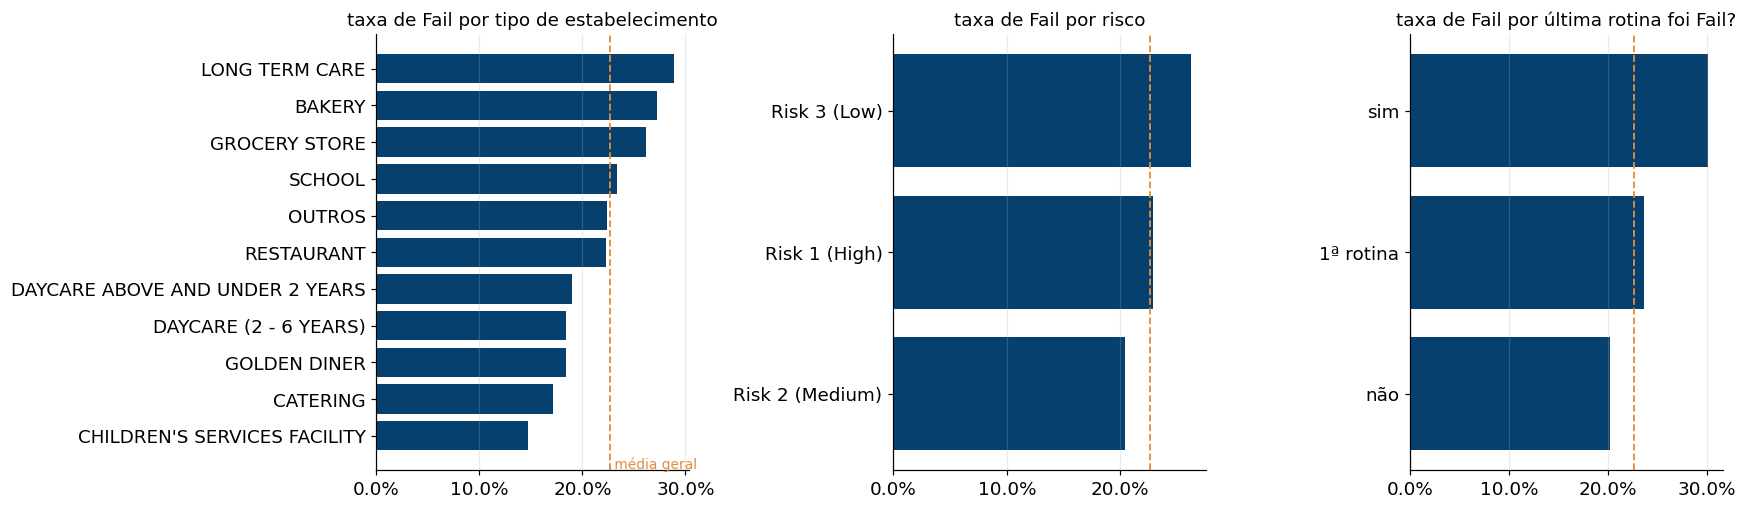


--- tipo de estabelecimento
                                  taxa      n
tipo_estab                                   
LONG TERM CARE                   0.289   1443
BAKERY                           0.273   2056
GROCERY STORE                    0.261  11663
SCHOOL                           0.233  14646
OUTROS                           0.224   4464
RESTAURANT                       0.223  91091
DAYCARE ABOVE AND UNDER 2 YEARS  0.190   1446
DAYCARE (2 - 6 YEARS)            0.184    990
GOLDEN DINER                     0.184    675
CATERING                         0.171    910
CHILDREN'S SERVICES FACILITY     0.147   2704

--- risco
                  taxa       n
risco_txt                     
SEM RISCO        1.000       1
Risk 3 (Low)     0.262    4282
Risk 1 (High)    0.229  108330
Risk 2 (Medium)  0.205   19475

--- última rotina foi Fail?
                     taxa      n
fail_ultima_rotina              
sim                 0.301  22589
1ª rotina           0.237  26871
não            

In [ ]:
# taxa de Fail por categoria: mostra PARA ONDE aponta a associação
taxa_geral = d["fail"].mean()
grupos = {
    "tipo de estabelecimento": d["tipo_estab"],
    "risco": d["risco_txt"],
    "última rotina foi Fail?": d["fail_ultima_rotina"].map({0: "não", 1: "sim"}).fillna("1ª rotina"),
}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (nome, s) in zip(axes, grupos.items()):
    t = d.groupby(s)["fail"].agg(taxa="mean", n="size")
    t = t[t["n"] >= 100].sort_values("taxa")          # categorias com pouco dado ficam de fora
    ax.barh(t.index, t["taxa"], color="#06406F")
    ax.axvline(taxa_geral, color="#E08D3C", ls="--", lw=1.2)
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.set_title(f"taxa de Fail por {nome}")
    ax.grid(axis="y", alpha=0)
axes[0].text(taxa_geral, -.9, " média geral", color="#E08D3C", fontsize=9)
plt.tight_layout()
plt.savefig(FIGS / "fi-04-taxa-fail-categorias.png", dpi=200, bbox_inches="tight")
plt.show()

for nome, s in grupos.items():
    print(f"\n--- {nome}")
    print(d.groupby(s)["fail"].agg(taxa="mean", n="size").sort_values("taxa", ascending=False).round(3))

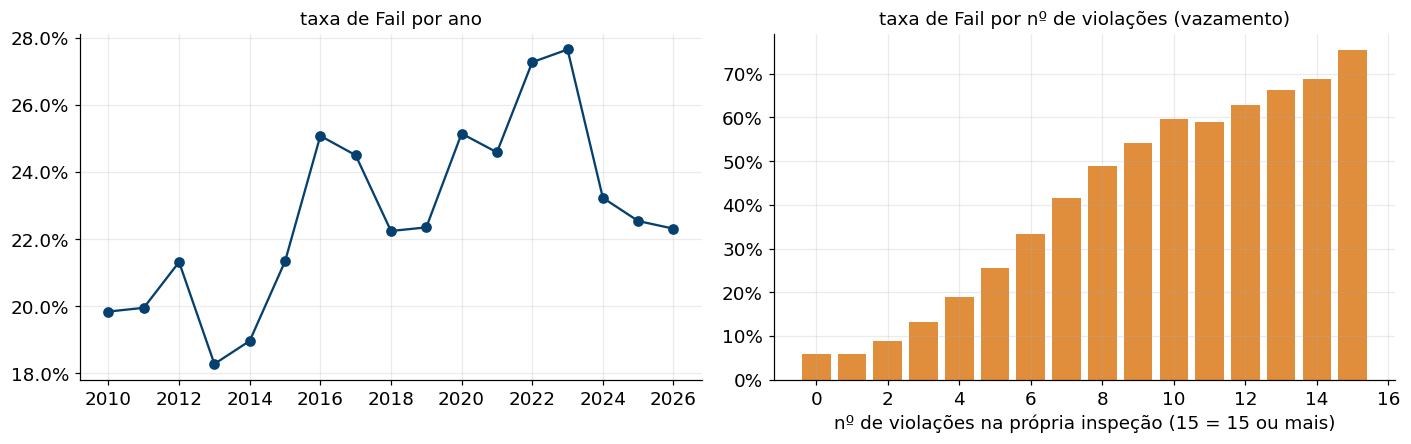

ano
2010    0.198
2011    0.200
2012    0.213
2013    0.183
2014    0.190
2015    0.213
2016    0.251
2017    0.245
2018    0.222
2019    0.224
2020    0.251
2021    0.246
2022    0.273
2023    0.277
2024    0.232
2025    0.225
2026    0.223
Name: fail, dtype: float64


In [ ]:
# tempo e vazamento: como a taxa de Fail muda com o ano e com o nº de violações
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))

por_ano = d.groupby("ano")["fail"].mean()
ax1.plot(por_ano.index, por_ano.values, marker="o", color="#06406F")
ax1.yaxis.set_major_formatter(PercentFormatter(1))
ax1.set_title("taxa de Fail por ano")

por_viol = d.groupby(d["n_violacoes"].clip(upper=15))["fail"].mean()
ax2.bar(por_viol.index, por_viol.values, color="#E08D3C")
ax2.yaxis.set_major_formatter(PercentFormatter(1))
ax2.set_xlabel("nº de violações na própria inspeção (15 = 15 ou mais)")
ax2.set_title("taxa de Fail por nº de violações (vazamento)")

plt.tight_layout()
plt.savefig(FIGS / "fi-04-tempo-vazamento.png", dpi=200, bbox_inches="tight")
plt.show()

print(por_ano.round(3))

### 🔬 Aprofundamento: Cramér's V

Os gráficos acima mostram **para onde** aponta cada categoria. Para **comparar a força** da associação entre variáveis diferentes num número só, dá para usar o **Cramér's V** (0 = nenhuma associação, 1 = uma determina a outra). Não é conteúdo da aula: fica como complemento. Usamos a versão com correção de viés, porque colunas com muitas categorias (como `zip`) inflam o V sem correção.

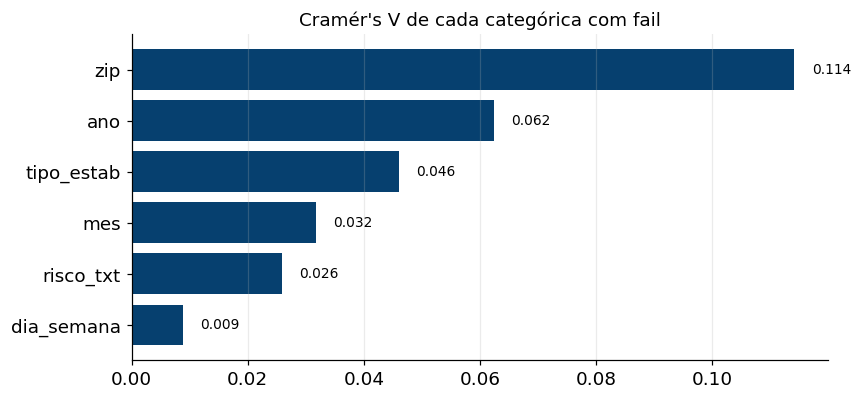

zip           0.114
ano           0.062
tipo_estab    0.046
mes           0.032
risco_txt     0.026
dia_semana    0.009
dtype: float64


In [ ]:
def cramers_v(x, y):
    """Cramér's V com correção de viés (Bergsma, 2013)."""
    tab = pd.crosstab(x, y)
    chi2 = chi2_contingency(tab, correction=False)[0]
    n = tab.values.sum()
    r, k = tab.shape
    phi2 = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    r_c, k_c = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / max(1e-12, min(k_c - 1, r_c - 1)))

cat = ["tipo_estab", "risco_txt", "zip", "ano", "mes", "dia_semana"]
v_alvo = pd.Series({c: cramers_v(d[c].astype(str), d["fail"]) for c in cat}).sort_values()

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(v_alvo.index, v_alvo.values, color="#06406F")
for i, v in enumerate(v_alvo.values):
    ax.text(v + .003, i, f"{v:.3f}", va="center", fontsize=9)
ax.set_title("Cramér's V de cada categórica com fail")
ax.grid(axis="y", alpha=0)
plt.tight_layout()
plt.savefig(FIGS / "fi-04-cramer-alvo.png", dpi=200, bbox_inches="tight")
plt.show()

print(v_alvo.sort_values(ascending=False).round(3))

### 4.3 · Redundância entre as categóricas (aprofundamento, Cramér's V)

Se duas variáveis explicativas carregam a mesma informação, manter as duas não ajuda o modelo. Esta matriz é a base da **seleção de features**.

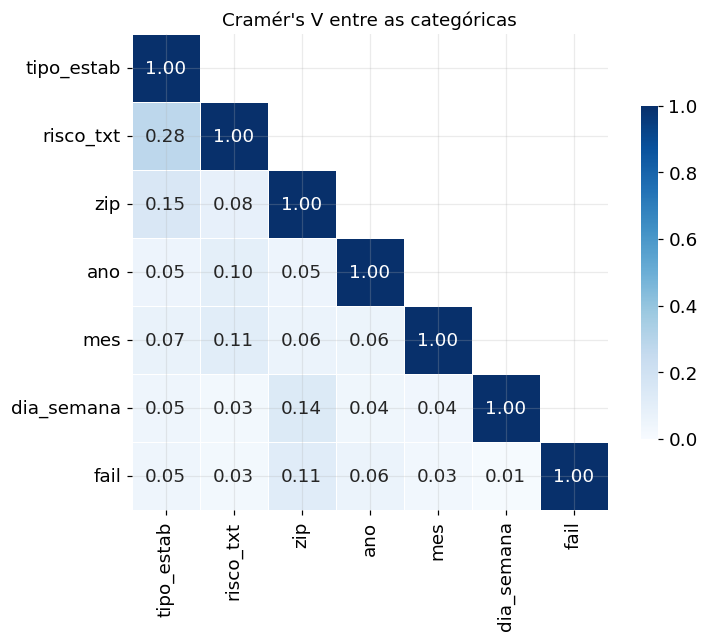

            tipo_estab  risco_txt   zip   ano   mes  dia_semana  fail
tipo_estab        1.00       0.28  0.15  0.05  0.07        0.05  0.05
risco_txt         0.28       1.00  0.08  0.10  0.11        0.03  0.03
zip               0.15       0.08  1.00  0.05  0.06        0.14  0.11
ano               0.05       0.10  0.05  1.00  0.06        0.04  0.06
mes               0.07       0.11  0.06  0.06  1.00        0.04  0.03
dia_semana        0.05       0.03  0.14  0.04  0.04        1.00  0.01
fail              0.05       0.03  0.11  0.06  0.03        0.01  1.00


In [ ]:
cols_v = cat + ["fail"]
mv = pd.DataFrame(np.eye(len(cols_v)), index=cols_v, columns=cols_v)
for i, a in enumerate(cols_v):
    for b in cols_v[i + 1:]:
        mv.loc[a, b] = mv.loc[b, a] = cramers_v(d[a].astype(str), d[b].astype(str))

fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(mv, mask=np.triu(np.ones_like(mv, dtype=bool), k=1), annot=True, fmt=".2f",
            cmap="Blues", vmin=0, vmax=1, square=True, linewidths=.5,
            cbar_kws={"shrink": .7}, ax=ax)
ax.set_title("Cramér's V entre as categóricas")
plt.tight_layout()
plt.savefig(FIGS / "fi-04-cramer-matriz.png", dpi=200, bbox_inches="tight")
plt.show()

print(mv.round(2))

### Conclusão da Correlação

Base: **132.088 inspeções Canvass** com resultado sanitário, **22,6% de Fail** (cerca de 1 Fail para cada 3,4 aprovações).

📌 **Nenhuma variável sozinha explica o Fail.** Tirando o vazamento, a maior correlação com o alvo é |ρ| ≈ 0,12. O modelo vai depender de combinações de variáveis, e com o alvo desbalanceado a acurácia sozinha não serve como métrica.

📌 **Vazamento confirmado.** `n_violacoes` tem ρ = 0,38 com `fail`, mais de 3 vezes qualquer outra variável, e a taxa de Fail sobe com o número de violações. A coluna é preenchida durante a própria inspeção.

📌 **O histórico do estabelecimento é o melhor sinal.** `taxa_fail_hist` (0,116), `fails_anteriores` (0,104) e `fail_ultima_rotina` (0,097) lideram. Quando a última rotina foi Fail, a taxa sobe para **30,1%**, contra **20,3%** quando passou (1ª rotina: 23,7%).
Já `fail_anterior` (último registro de qualquer tipo) fica em ≈ 0,01: depois de um Fail vem uma re-inspeção, que em geral passa, e isso apaga o sinal. O que importa é a última **rotina**.

📌 **Redundâncias.** `insp_anteriores` × `fails_anteriores` = 0,72 e `insp_anteriores` × `ano` = 0,60: quanto mais tempo no dataset, mais inspeções acumuladas. `Risk` × `tipo_estab` tem V = 0,28.

📌 **Localização importa, mas não de forma linear.** `zip` é a categórica mais associada (V = 0,114), enquanto Latitude e Longitude têm ρ ≈ 0: o efeito existe por região, não "quanto mais ao norte, mais Fail".

📌 **O tempo muda o alvo.** A taxa de Fail vai de ~19% (2013–2014) a ~27–28% (2022–2023). Isso reforça a decisão da seção 1: dividir treino e teste **por data**.

📌 **Risk é contraintuitivo.** Risk 3 (Low) falha mais (26,2%) que High (22,9%) e Medium (20,5%). `Risk` descreve o tipo de operação e define a frequência de inspeção, não a chance de falhar numa inspeção.

| achado | decisão |
|---|---|
| `n_violacoes` / `Violations` ρ = 0,38 (vazamento) | **não usar** como preditora da mesma inspeção; no máximo, violações da rotina *anterior* |
| histórico: `taxa_fail_hist`, `fails_anteriores`, `fail_ultima_rotina` | **manter**: principais candidatas para a engenharia de features |
| `fail_anterior` ≈ 0,01 | **descartar**, substituída por `fail_ultima_rotina` |
| `insp_anteriores` redundante com `fails_anteriores` (0,72) e `ano` (0,60) | preferir `taxa_fail_hist` e avaliar tirar `insp_anteriores` na seleção |
| `zip` V = 0,114, lat/lon ρ ≈ 0 | usar `zip` (ou agrupamento geográfico); lat/lon cruas não ajudam um modelo linear |
| taxa de Fail muda com o `ano` | divisão treino/teste por data; `ano` pode entrar como feature |
| `tipo_estab` V = 0,046 (14,7% a 28,9%) | **manter** agrupado em top 10 + OUTROS |
| `Risk` fraco e parcialmente redundante com `tipo_estab` | manter por enquanto e decidir na seleção de features |
| `mes` V = 0,032, `dia_semana` V = 0,009 | sinal fraco; `dia_semana` é candidata a descarte |

---
## 5 · Preparação dos dados — como deixar a base pronta?

Nesta etapa, aplicamos as decisões tomadas durante a análise exploratória. Tratamos formatos, categorias, valores ausentes, duplicatas, recorte do problema e colunas com vazamento.

A preparação será feita em uma cópia do dataset congelado, preservando o `df` original.

In [ ]:
df_prep = df.copy(deep=True)

linhas_iniciais = len(df_prep)

print("Base original:", df.shape)
print("Base de preparação:", df_prep.shape)

Base original: (315963, 17)
Base de preparação: (315963, 17)


In [ ]:
marcadores_de_vazio = {
    "", "nan", "null", "none", "n/a", "na", "unknown"
}

colunas_texto = df_prep.select_dtypes(
    include=["object", "string"]
).columns

for coluna in colunas_texto:
    serie = df_prep[coluna].astype("string").str.strip()

    mascara_vazio = (
        serie
        .str.lower()
        .isin(marcadores_de_vazio)
    )

    serie = serie.mask(mascara_vazio, pd.NA)
    df_prep[coluna] = serie

colunas_categoricas = [
    "Inspection Type",
    "Results",
    "Risk",
    "Facility Type",
    "City",
    "State"
]

for coluna in colunas_categoricas:
    df_prep[coluna] = (
        df_prep[coluna]
        .str.upper()
        .str.replace(r"\s+", " ", regex=True)
    )

correcoes_city = {
    "CCHICAGO": "CHICAGO",
    "CHICAGOO": "CHICAGO",
    "CHICAGOCHICAGO": "CHICAGO"
}

df_prep["City"] = df_prep["City"].replace(correcoes_city)

In [ ]:
df_prep["Inspection Date"] = pd.to_datetime(
    df_prep["Inspection Date"],
    format="%m/%d/%Y",
    errors="coerce"
)

licenca_numerica = pd.to_numeric(
    df_prep["License #"],
    errors="coerce"
).astype("Int64")

df_prep["License #"] = (
    licenca_numerica
    .replace(0, pd.NA)
    .astype("string")
)

zip_numerico = pd.to_numeric(
    df_prep["Zip"],
    errors="coerce"
).astype("Int64")

df_prep["Zip"] = (
    zip_numerico
    .astype("string")
    .str.zfill(5)
)


print(df_prep[
    ["Inspection Date", "License #", "Zip"]
].dtypes)

Inspection Date    datetime64[ns]
License #          string[python]
Zip                string[python]
dtype: object


In [ ]:
duplicatas_exatas = int(
    df_prep.duplicated().sum()
)

ids_repetidos = int(
    df_prep["Inspection ID"]
    .duplicated(keep=False)
    .sum()
)

print("Duplicatas exatas:", duplicatas_exatas)
print("Linhas com Inspection ID repetido:", ids_repetidos)


df_prep = (
    df_prep
    .drop_duplicates()
    .copy()
)


if ids_repetidos > 0:
    display(
        df_prep[
            df_prep["Inspection ID"].duplicated(keep=False)
        ].sort_values("Inspection ID")
    )

Duplicatas exatas: 0
Linhas com Inspection ID repetido: 0


In [ ]:
resultados_validos = [
    "PASS",
    "PASS W/ CONDITIONS",
    "FAIL"
]

linhas_antes_recorte = len(df_prep)

mascara_recorte = (
    df_prep["Inspection Type"].eq("CANVASS")
    & df_prep["Results"].isin(resultados_validos)
)

df_prep = (
    df_prep
    .loc[mascara_recorte]
    .copy()
)


df_prep["fail"] = (
    df_prep["Results"].eq("FAIL")
    .astype("int8")
)

print("Linhas antes do recorte:", linhas_antes_recorte)
print("Linhas depois do recorte:", len(df_prep))
print("Linhas retiradas:", linhas_antes_recorte - len(df_prep))

display(
    df_prep["Results"]
    .value_counts()
    .to_frame("linhas")
)

print(
    "Taxa de Fail:",
    f"{df_prep['fail'].mean():.1%}"
)

Linhas antes do recorte: 315963
Linhas depois do recorte: 132088
Linhas retiradas: 183875


,linhas
Results,
PASS,75106
FAIL,29896
PASS W/ CONDITIONS,27086


Taxa de Fail: 22.6%


In [ ]:
categoricas_com_desconhecido = [
    "Facility Type",
    "Risk",
    "City",
    "State",
    "Zip"
]

for coluna in categoricas_com_desconhecido:
    df_prep[coluna] = (
        df_prep[coluna]
        .fillna("DESCONHECIDO")
    )


resumo_vazios_prep = pd.DataFrame({
    "faltantes": df_prep.isna().sum(),
    "percentual": (
        df_prep.isna().mean() * 100
    ).round(2)
})

display(
    resumo_vazios_prep[
        resumo_vazios_prep["faltantes"] > 0
    ].sort_values("faltantes", ascending=False)
)

,faltantes,percentual
Violations,8259,6.25
Latitude,557,0.42
Longitude,557,0.42
Location,557,0.42
License #,352,0.27
AKA Name,261,0.20
Address,1,0.00


In [ ]:
df_prep = df_prep.drop(
    columns=["Location"],
    errors="ignore"
)

colunas_com_vazamento = [
    "Results",
    "Violations"
]

colunas_de_identificacao = [
    "Inspection ID",
    "License #",
    "DBA Name",
    "AKA Name",
    "Address"
]

print("Colunas com vazamento:", colunas_com_vazamento)
print("Colunas de identificação:", colunas_de_identificacao)
print("Location removida:", "Location" not in df_prep.columns)

Colunas com vazamento: ['Results', 'Violations']
Colunas de identificação: ['Inspection ID', 'License #', 'DBA Name', 'AKA Name', 'Address']
Location removida: True


### Decisão sobre valores extremos

A análise exploratória não encontrou datas inválidas, CEPs impossíveis ou coordenadas fora dos limites geográficos.

Também foram encontrados estabelecimentos com quantidade elevada de inspeções. Esses casos não serão removidos, pois podem representar estabelecimentos antigos, redes ou locais fiscalizados com maior frequência.

Portanto, nenhum registro será excluído automaticamente como outlier. Caso alguma variável numérica precise de escala, essa transformação será aplicada posteriormente dentro do pipeline e ajustada somente com os dados de treino.

In [ ]:
decisoes_preparacao = pd.DataFrame([
    {
        "problema": "Textos com espaços e grafias diferentes",
        "decisao": "Remover espaços e padronizar categorias em maiúsculas"
    },
    {
        "problema": "City com erros evidentes de digitação",
        "decisao": "Corrigir apenas variações claramente referentes a Chicago"
    },
    {
        "problema": "License # igual a zero",
        "decisao": "Converter zero em valor ausente e tratar a coluna como código"
    },
    {
        "problema": "Zip armazenado como número decimal",
        "decisao": "Converter para código textual de cinco posições"
    },
    {
        "problema": "Resultados sem inspeção sanitária concluída",
        "decisao": "Manter somente Pass, Pass w/ Conditions e Fail"
    },
    {
        "problema": "Diferentes tipos de inspeção",
        "decisao": "Manter somente inspeções rotineiras Canvass"
    },
    {
        "problema": "Location repete latitude e longitude",
        "decisao": "Remover Location"
    },
    {
        "problema": "Results e Violations revelam o resultado atual",
        "decisao": "Não utilizar como preditoras da mesma inspeção"
    },
    {
        "problema": "Categorias ausentes",
        "decisao": "Representar como DESCONHECIDO"
    },
    {
        "problema": "Casos extremos legítimos",
        "decisao": "Manter; não remover outliers automaticamente"
    }
])

display(decisoes_preparacao)

,problema,decisao
0,Textos com espaços e grafias diferentes,Remover espaços e padronizar categorias em mai...
1,City com erros evidentes de digitação,Corrigir apenas variações claramente referente...
2,License # igual a zero,Converter zero em valor ausente e tratar a col...
3,Zip armazenado como número decimal,Converter para código textual de cinco posições
4,Resultados sem inspeção sanitária concluída,"Manter somente Pass, Pass w/ Conditions e Fail"
5,Diferentes tipos de inspeção,Manter somente inspeções rotineiras Canvass
6,Location repete latitude e longitude,Remover Location
7,Results e Violations revelam o resultado atual,Não utilizar como preditoras da mesma inspeção
8,Categorias ausentes,Representar como DESCONHECIDO
9,Casos extremos legítimos,Manter; não remover outliers automaticamente


In [ ]:
assert df_prep["Inspection Type"].eq("CANVASS").all()

assert df_prep["Results"].isin(
    resultados_validos
).all()

assert df_prep["fail"].isin([0, 1]).all()

assert df_prep["Inspection ID"].is_unique

assert "Location" not in df_prep.columns

assert not df_prep["License #"].eq("0").any()


print("PREPARAÇÃO CONCLUÍDA")
print("-" * 40)
print("Linhas originais:", linhas_iniciais)
print("Linhas preparadas:", len(df_prep))
print("Colunas preparadas:", df_prep.shape[1])
print("Inspection ID único:", df_prep["Inspection ID"].is_unique)
print("Taxa de Fail:", f"{df_prep['fail'].mean():.1%}")

PREPARAÇÃO CONCLUÍDA
----------------------------------------
Linhas originais: 315963
Linhas preparadas: 132088
Colunas preparadas: 17
Inspection ID único: True
Taxa de Fail: 22.6%


---
## 6 · Engenharia de features

Objetivo: medir se cada feature criada acrescenta informação nova ao modelo, e não só recombina o que ele já tinha. Seguimos os 5 passos do slide 26 da a09:

1. medir o ponto de partida com **todas** as colunas que já existem;
2. gerar candidatas (razão, diferença, agregação, extração, índice, interação, mudar a forma);
3. medir cada uma em validação cruzada, uma de cada vez;
4. classificar: recombinou, mudou a forma ou trouxe informação nova?
5. desconfiar do que sobe demais: comparar treino com validação.

**Métrica:** AUC, porque o alvo é binário (22,6% de Fail). É o papel que o R² faz na aula, que trabalha com regressão. **Modelo:** a mesma regressão logística do começo ao fim, como a aula faz com a regressão linear.

**Validação:** o slide 6 embaralha o dado antes de dividir em 5 partes. Aqui não embaralhamos: a seção 1 mostrou que o mesmo estabelecimento aparece várias vezes, e a seção 4 mostrou que a taxa de Fail muda com o ano. Por isso usamos `TimeSeriesSplit`: cada fold treina no passado e testa no futuro. Imputação, padronização e one-hot ficam dentro de um pipeline, ajustados só no treino de cada fold (antecipando a a11).

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# ponto de partida (slide 26, passo 1): TODAS as colunas que já existiam antes da engenharia
BASE_NUM = ["risco", "ano", "mes", "dia_semana", "Latitude", "Longitude"]
BASE_CAT = ["tipo_estab", "zip"]

# validação cruzada em ordem de data: cada fold treina no passado e testa no futuro (decisão da seção 1)
ordem = d.sort_values(["data", "Inspection ID"]).index
cv_t = TimeSeriesSplit(n_splits=5)

def medir(num_cols=(), cat_cols=(), base=True, treino=False):
    """AUC média em validação cruzada.
    base=True  -> soma as colunas passadas ao ponto de partida (BASE_NUM + BASE_CAT)
    base=False -> usa só as colunas passadas
    treino=True -> devolve também a AUC no próprio treino (slide 21)"""
    if base:
        num = BASE_NUM + [c for c in num_cols if c not in BASE_NUM]
        cat = BASE_CAT + [c for c in cat_cols if c not in BASE_CAT]
    else:
        num, cat = list(num_cols), list(cat_cols)
    etapas = []
    if num:
        etapas.append((make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                                     StandardScaler()), num))
    if cat:
        etapas.append((OneHotEncoder(handle_unknown="ignore", min_frequency=100), cat))
    modelo = make_pipeline(make_column_transformer(*etapas), LogisticRegression(max_iter=2000))
    r = cross_validate(modelo, d.loc[ordem, num + cat], d.loc[ordem, "fail"],
                       cv=cv_t, scoring="roc_auc", return_train_score=treino)
    if treino:
        return r["test_score"].mean(), r["train_score"].mean()
    return r["test_score"].mean()

In [ ]:
auc_0, treino_0 = medir(treino=True)
print(f"ponto de partida (todas as colunas originais): AUC = {auc_0:.3f} | treino = {treino_0:.3f}")
print(f"só risco e ano (base fraca da versão anterior)   : AUC = {medir(['risco', 'ano'], base=False):.3f}")

ponto de partida (todas as colunas originais): AUC = 0.554 | treino = 0.618
só risco e ano (base fraca da versão anterior)   : AUC = 0.501


O ponto de partida com todas as colunas originais tem **AUC = 0,554**. É o número que toda feature criada precisa superar (slide 26: no projeto, a feature criada tem de vencer as colunas que já estão lá). Com só `risco` e `ano`, a AUC seria 0,501, praticamente um sorteio.

A diferença entre treino (0,618) e validação (0,554) já existe no ponto de partida: 0,063. Esse número serve de referência para o passo 5.

### Candidatas de histórico

Na etapa de Correlação, um conjunto de colunas de histórico já tinha sido calculado (`insp_anteriores`, `fails_anteriores`, `fail_ultima_rotina`, `taxa_fail_hist`, `dias_desde_ultima`). Aqui cada uma é somada **sozinha** ao ponto de partida, para medir seu ganho real em validação cruzada, e não sua correlação isolada.

In [ ]:
# passo 3 do slide 26: cada candidata somada SOZINHA ao ponto de partida
candidatas = ["insp_anteriores", "fails_anteriores", "taxa_fail_hist",
              "dias_desde_ultima", "fail_ultima_rotina"]
linhas = []
for f in candidatas:
    cv, tr = medir([f], treino=True)
    linhas.append({"feature": f, "auc_cv": cv, "ganho": cv - auc_0, "auc_treino": tr})
tab_hist = pd.DataFrame(linhas).sort_values("ganho", ascending=False).reset_index(drop=True)
display(tab_hist.round(3))

,feature,auc_cv,ganho,auc_treino
0,taxa_fail_hist,0.576,0.022,0.629
1,fails_anteriores,0.576,0.022,0.628
2,fail_ultima_rotina,0.573,0.018,0.627
3,dias_desde_ultima,0.557,0.002,0.619
4,insp_anteriores,0.554,0.000,0.618


| Feature | Forma (slide 12) | Ganho | Interpretação |
|---|---|---|---|
| `taxa_fail_hist` | razão | +0,022 | proporção de Fails no histórico |
| `fails_anteriores` | agregação | +0,022 | empata com a razão: carrega a mesma informação |
| `fail_ultima_rotina` | extração | +0,018 | resultado da última rotina |
| `dias_desde_ultima` | diferença | +0,002 | quase nada |
| `insp_anteriores` | agregação | 0,000 | nenhum ganho |

`insp_anteriores` não rende nada. A seção 4 já apontava o motivo: ela anda junto com `ano` (ρ = 0,60), que já está no ponto de partida, porque estabelecimentos mais antigos no dataset acumulam mais inspeções. É o mesmo caso da `IdadeCasa` na aula (slide 10): a coluna parece nova, mas o modelo já tinha a informação.

Já `fail_ultima_rotina`, que tinha a 3ª maior correlação com o alvo na seção 4 (0,097), rende menos que `taxa_fail_hist` e `fails_anteriores`. Correlação mede a variável sozinha contra o alvo; o ganho mede o que ela acrescenta ao modelo (slide 22).

**Decisão:** `taxa_fail_hist` e `fails_anteriores` são as features prioritárias do histórico (como carregam a mesma informação, só uma deve ficar no modelo final); `fail_ultima_rotina` fica como candidata; `dias_desde_ultima` e `insp_anteriores` não se sustentam contra o ponto de partida.

### Corrigindo o vazamento

A etapa de Correlação confirmou que `n_violacoes` vaza o alvo: ρ = 0,38, porque a coluna é preenchida durante a mesma inspeção que se quer prever. Pela regra do slide 25 ("nenhuma feature pode ser construída com o alvo"), a coluna bruta não pode entrar no modelo.

Em vez de descartar essa informação por completo, criamos uma versão que não vaza: o número de violações da **rotina anterior** daquele estabelecimento (`viol_ultima_rotina`), obtido com o mesmo `.shift()` já usado para `fail_ultima_rotina`.

In [ ]:
hist["n_violacoes"] = hist["Violations"].str.count(r" \| ").add(1).fillna(0)

rotina2 = hist[hist["Inspection Type"].str.strip().str.upper().eq("CANVASS")
               & hist["Results"].isin(["Pass", "Pass w/ Conditions", "Fail"])]

hist["viol_ultima_rotina"] = rotina2.groupby("License #")["n_violacoes"].shift()
d["viol_ultima_rotina"] = hist["viol_ultima_rotina"]

auc_viol = medir(["viol_ultima_rotina"])
auc_viol_taxa = medir(["taxa_fail_hist", "viol_ultima_rotina"])
print(f"+ viol_ultima_rotina                  : {auc_viol:.3f} (ganho = {auc_viol - auc_0:+.3f})")
print(f"+ taxa_fail_hist + viol_ultima_rotina : {auc_viol_taxa:.3f} (ganho = {auc_viol_taxa - auc_0:+.3f})")

+ viol_ultima_rotina                  : 0.605 (ganho = +0.051)
+ taxa_fail_hist + viol_ultima_rotina : 0.611 (ganho = +0.057)


Sozinha, `viol_ultima_rotina` rende **+0,051**, mais que o dobro de qualquer outra feature de histórico. Junto com `taxa_fail_hist`, a AUC chega a **0,611** (+0,057).

**Decisão:** manter `viol_ultima_rotina`. É a prova de que um vazamento identificado pode ser reconstruído de forma honesta, usando só informação disponível no momento da previsão, e ainda ser a feature mais útil da seção.

### Índice composto: combinando os sinais de histórico

In [ ]:
d["gravidade_hist"] = (
    d["taxa_fail_hist"].fillna(0)
    + (d["fail_ultima_rotina"].fillna(0) * 0.5)
    + (d["viol_ultima_rotina"].fillna(0) / 10)
)

auc_idx6 = medir(["gravidade_hist"])
print(f"+ gravidade_hist (índice composto): {auc_idx6:.3f} (ganho = {auc_idx6 - auc_0:+.3f})")

+ gravidade_hist (índice composto): 0.589 (ganho = +0.035)


`gravidade_hist` junta três sinais de histórico numa coluna só, como o índice de amenidades da aula (slide 15). Sozinho, atinge **0,589** (+0,035): melhor que qualquer componente isolado, menos `viol_ultima_rotina` (+0,051).

A explicação está nos pesos (1; 0,5; 0,1), escolhidos à mão: a componente mais forte, `viol_ultima_rotina`, ficou com o menor peso. Combinar ajudou, mas a combinação escolhida não é a melhor possível.

**Decisão:** manter `gravidade_hist` como candidata e comparar, na seleção, o índice com os três componentes separados (deixando o modelo escolher os pesos).

\### Interação risco × tipo de estabelecimento

O slide 16 define interação como o **produto** a × b: o efeito de uma variável depende do valor da outra, e o modelo linear não forma esse produto sozinho. Com duas categóricas, o produto das dummies de risco e de tipo é uma dummy para cada combinação (por exemplo, `Risk 1 (High) × RESTAURANT`).

A versão anterior desta célula usava a **taxa de Fail** de cada combinação, calculada na base inteira. Isso é Target Encoding medido no lugar errado, o vazamento que os slides 21 e 25 proíbem. Esta versão não usa o alvo.

In [ ]:
# interação = produto a × b (slide 16). Com duas categóricas, o produto das dummies de risco
# e de tipo é uma dummy para cada combinação risco × tipo. Nada aqui usa o alvo (slide 25).
d["risco_x_tipo"] = d["risco_txt"] + " × " + d["tipo_estab"]

auc_int = medir(cat_cols=["risco_x_tipo"])
print("combinações distintas:", d["risco_x_tipo"].nunique())
print(f"+ risco_x_tipo (produto): {auc_int:.3f} (ganho = {auc_int - auc_0:+.3f})")

combinações distintas: 28
+ risco_x_tipo (produto): 0.558 (ganho = +0.004)


São 28 combinações, e a interação rende **+0,004**: praticamente nada. As duas partes (`risco` e `tipo_estab`) já estavam no ponto de partida, e o slide 16 avisa que o produto de colunas que já estão no modelo não traz informação nova.

**Decisão:** descartar `risco_x_tipo`.

### Mudar a forma: log das contagens de histórico

O slide 14 mostra a outra família de transformação: mudar a **forma** da coluna, sem trazer nada de fora. Na seção 3, o número de inspeções por estabelecimento teve skew de 2,59 (cauda longa à direita). A regressão logística procura uma relação linear, e a cauda puxa essa relação para os poucos casos extremos. Testamos `log1p` em `insp_anteriores` e `dias_desde_ultima`, comparando cada versão com a coluna crua.

In [ ]:
# mudar a forma (slide 14): log1p reduz a cauda longa das contagens
for col in ["insp_anteriores", "dias_desde_ultima"]:
    print(f"{col:18s} skew: {d[col].skew():.2f} -> depois do log: {np.log1p(d[col]).skew():.2f}")

d["log_insp"] = np.log1p(d["insp_anteriores"])
d["log_dias"] = np.log1p(d["dias_desde_ultima"])

print()
for crua, log in [("insp_anteriores", "log_insp"), ("dias_desde_ultima", "log_dias")]:
    a_crua, a_log = medir([crua]), medir([log])
    print(f"{crua:18s}: {a_crua:.3f} | {log}: {a_log:.3f} (diferença = {a_log - a_crua:+.3f})")

insp_anteriores    skew: 4.33 -> depois do log: -0.30
dias_desde_ultima  skew: 4.12 -> depois do log: -2.77

insp_anteriores   : 0.554 | log_insp: 0.554 (diferença = -0.001)
dias_desde_ultima : 0.557 | log_dias: 0.558 (diferença = +0.001)


O log corrige a assimetria de `insp_anteriores` (skew de 4,33 para −0,30), mas inverte a de `dias_desde_ultima` (de 4,12 para −2,77: a cauda passa para a esquerda). Nas duas, o ganho em relação à coluna crua é nulo (−0,001 e +0,001).

Na aula, o log de `LotArea` subiu o R² de 0,323 para 0,400 (slide 14). Aqui não ajudou porque as duas colunas já não carregavam informação contra o ponto de partida: mudar a forma de uma coluna sem sinal não cria sinal.

**Decisão:** descartar `log_insp` e `log_dias`. Resultado negativo também é resultado (slide 26).

### Resumo: classificação e treino × CV

Passos 4 e 5 do slide 26. Para cada candidata: a forma de derivar (slide 12), a classificação (recombinou, mudou a forma ou trouxe informação nova) e a comparação entre a AUC de treino e a de validação. Uma feature que sobe o treino sem subir a validação é o sinal de alerta do slide 21.

,feature,forma (slide 12),classificação (slide 26),auc_cv,ganho,auc_treino,treino - cv
0,viol_ultima_rotina,extração,informação nova,0.605,0.051,0.644,0.039
1,gravidade_hist,índice composto,informação nova,0.589,0.035,0.633,0.044
2,taxa_fail_hist,razão,informação nova,0.576,0.022,0.629,0.053
3,fails_anteriores,agregação,informação nova,0.576,0.022,0.628,0.052
4,fail_ultima_rotina,extração,informação nova,0.573,0.018,0.627,0.054
5,risco_x_tipo,interação,recombinou o que já havia,0.558,0.004,0.621,0.063
6,log_dias,mudar a forma,mudou a forma,0.558,0.003,0.620,0.062
7,dias_desde_ultima,diferença,informação nova,0.557,0.002,0.619,0.063
8,insp_anteriores,agregação,recombinou o que já havia,0.554,0.000,0.618,0.064
9,log_insp,mudar a forma,mudou a forma,0.554,-0.000,0.618,0.064


ponto de partida: CV 0.554 | treino 0.618 | treino - cv +0.063


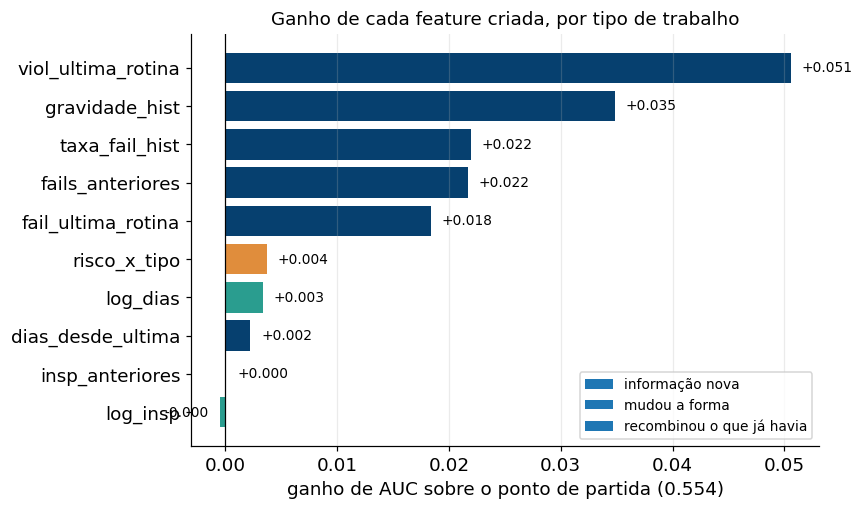

In [ ]:
# passos 4 e 5 do slide 26: classificar cada candidata e comparar treino × CV
classe = {
    "insp_anteriores":    ("agregação",       "recombinou o que já havia"),
    "fails_anteriores":   ("agregação",       "informação nova"),
    "taxa_fail_hist":     ("razão",           "informação nova"),
    "dias_desde_ultima":  ("diferença",       "informação nova"),
    "fail_ultima_rotina": ("extração",        "informação nova"),
    "viol_ultima_rotina": ("extração",        "informação nova"),
    "gravidade_hist":     ("índice composto", "informação nova"),
    "log_insp":           ("mudar a forma",   "mudou a forma"),
    "log_dias":           ("mudar a forma",   "mudou a forma"),
    "risco_x_tipo":       ("interação",       "recombinou o que já havia"),
}

linhas = []
for f, (forma, tipo) in classe.items():
    num, cat = ([], [f]) if f == "risco_x_tipo" else ([f], [])
    cv, tr = medir(num, cat, treino=True)
    linhas.append({"feature": f, "forma (slide 12)": forma, "classificação (slide 26)": tipo,
                   "auc_cv": cv, "ganho": cv - auc_0, "auc_treino": tr, "treino - cv": tr - cv})
resumo = pd.DataFrame(linhas).sort_values("ganho", ascending=False).reset_index(drop=True)
display(resumo.round(3))
print(f"ponto de partida: CV {auc_0:.3f} | treino {treino_0:.3f} | treino - cv {treino_0 - auc_0:+.3f}")

cor_tipo = {"informação nova": "#06406F", "mudou a forma": "#2A9D8F",
            "recombinou o que já havia": "#E08D3C"}
s = resumo.sort_values("ganho")
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(s["feature"], s["ganho"], color=[cor_tipo[t] for t in s["classificação (slide 26)"]])
ax.axvline(0, color="black", lw=.8)
for i, v in enumerate(s["ganho"]):
    ax.text(v + (.001 if v >= 0 else -.001), i, f"{v:+.3f}", va="center",
            ha="left" if v >= 0 else "right", fontsize=9)
for t, c in cor_tipo.items():
    ax.barh([], [], color=c, label=t)
ax.legend(loc="lower right", fontsize=9)
ax.set_xlabel(f"ganho de AUC sobre o ponto de partida ({auc_0:.3f})")
ax.set_title("Ganho de cada feature criada, por tipo de trabalho")
ax.grid(axis="y", alpha=0)
plt.tight_layout()
plt.savefig(FIGS / "fi-06-features-auc.png", dpi=200, bbox_inches="tight")
plt.show()

### Conclusão da Engenharia de Features

| Feature | Forma (slide 12) | Classificação (slide 26) | Ganho em CV | Treino − CV | Decisão |
|---|---|---|---|---|---|
| `viol_ultima_rotina` | extração | informação nova | +0,051 | 0,039 | manter: melhor feature |
| `gravidade_hist` | índice composto | informação nova | +0,035 | 0,044 | candidata: comparar com os componentes na seleção |
| `taxa_fail_hist` | razão | informação nova | +0,022 | 0,053 | manter |
| `fails_anteriores` | agregação | informação nova | +0,022 | 0,052 | redundante com `taxa_fail_hist` |
| `fail_ultima_rotina` | extração | informação nova | +0,018 | 0,054 | candidata |
| `risco_x_tipo` | interação | recombinou o que já havia | +0,004 | 0,063 | descartar |
| `log_dias` | mudar a forma | mudou a forma | +0,003 | 0,062 | descartar |
| `dias_desde_ultima` | diferença | informação nova | +0,002 | 0,063 | descartar |
| `insp_anteriores` | agregação | recombinou o que já havia (redundante com `ano`) | 0,000 | 0,064 | descartar |
| `log_insp` | mudar a forma | mudou a forma | 0,000 | 0,064 | descartar |

Ponto de partida: AUC 0,554, treino − CV = 0,063.

**Treino × CV (passo 5):** nenhuma feature aumentou de forma relevante a diferença entre treino e validação, e as de histórico até a diminuíram (0,039 com `viol_ultima_rotina`). O ganho delas aparece nos dados que o modelo não viu, e não é ajuste ao ruído do treino.

**Que tipo de trabalho pagou (slide 20):** trazer informação nova do histórico do estabelecimento rendeu de +0,018 a +0,051, e o índice composto +0,035. Recombinar o que já havia (interação) e mudar a forma (log) renderam praticamente zero. É o mesmo padrão da aula.

**Correlação não ordenou o ganho (slide 22):** `fail_ultima_rotina` tinha a 3ª maior correlação e ficou atrás de `taxa_fail_hist` e `fails_anteriores`.

O critério do G2 (pelo menos 3 features criadas e justificadas) está coberto: `viol_ultima_rotina`, `gravidade_hist`, `risco_x_tipo`, `log_insp` e `log_dias` foram criadas nesta seção, e as de histórico vieram da seção 4. Todas foram medidas em validação cruzada contra o mesmo ponto de partida.

## 7 · Seleção de features (aprofundamento)

> Não é conteúdo da a09: o slide 7 diz que cortar colunas é **seleção**, assunto da a20. Fica como complemento, assim como o Cramér's V na seção 4.

Objetivo: escolher, entre as colunas originais e as features criadas na seção 6, o menor conjunto que mantém o desempenho. A pergunta muda: na seção 6 cada feature foi somada **sozinha** ao ponto de partida; aqui medimos **o que cada uma acrescenta quando as outras já estão no modelo**. Usamos a mesma função `medir` da seção 6 (mesma métrica, mesmo modelo, mesma validação temporal), então os números das duas seções são comparáveis.

Primeiro, o teto: o que acontece se colocarmos **todas** as features criadas de uma vez?

In [ ]:
# teto: ponto de partida + TODAS as features criadas na seção 6
todas_criadas = ["insp_anteriores", "fails_anteriores", "taxa_fail_hist", "dias_desde_ultima",
                 "fail_ultima_rotina", "viol_ultima_rotina", "gravidade_hist", "log_insp", "log_dias"]
auc_tudo, treino_tudo = medir(todas_criadas, ["risco_x_tipo"], treino=True)

print(f"ponto de partida       : CV {auc_0:.3f} | treino {treino_0:.3f}")
print(f"+ todas as criadas     : CV {auc_tudo:.3f} | treino {treino_tudo:.3f}")

ponto de partida       : CV 0.554 | treino 0.618
+ todas as criadas     : CV 0.615 | treino 0.652


Com todas as features criadas, a AUC vai de 0,554 para **0,615**. Mas são 9 colunas numéricas a mais, além da interação com 28 combinações, e a seção 6 mostrou que várias delas não rendem nada sozinhas.

**Decisão:** usar 0,615 como teto de referência e procurar o menor conjunto que chegue perto dele.

### Índice composto ou componentes?

`gravidade_hist` é a soma de `taxa_fail_hist`, `fail_ultima_rotina` e `viol_ultima_rotina` com pesos escolhidos à mão (1; 0,5; 0,1). Colocar o índice **e** os componentes no mesmo modelo repetiria a mesma informação (é a multicolinearidade do slide 23), então testamos as duas versões separadamente, somadas ao ponto de partida.

In [ ]:
hist_comp = ["taxa_fail_hist", "fail_ultima_rotina", "viol_ultima_rotina"]

auc_idx  = medir(["gravidade_hist"])
auc_comp = medir(hist_comp)
hist_escolhido = hist_comp if auc_comp >= auc_idx else ["gravidade_hist"]

print(f"+ gravidade_hist (índice) : {auc_idx:.3f}")
print(f"+ os 3 componentes        : {auc_comp:.3f}")
print("-> histórico escolhido:", hist_escolhido)

+ gravidade_hist (índice) : 0.589
+ os 3 componentes        : 0.611
-> histórico escolhido: ['taxa_fail_hist', 'fail_ultima_rotina', 'viol_ultima_rotina']


Os três componentes separados chegam a **0,611**, contra **0,589** do índice. Com as colunas separadas, a regressão logística aprende os pesos a partir dos dados. Na seção 6, o índice deu o menor peso justamente à componente mais forte (`viol_ultima_rotina`).

**Decisão:** usar os três componentes e tirar `gravidade_hist`. O índice mostrou que combinar os sinais de histórico funciona, mas o modelo faz essa combinação melhor sozinho.

### Ablação: o que cada coluna acrescenta

Partimos do conjunto completo (as 8 colunas originais mais os 3 componentes de histórico, AUC 0,611) e tiramos uma coluna de cada vez. Se a AUC cai sem ela (Δ negativo), a coluna carrega informação que as outras não têm. Se fica igual ou sobe, ela é dispensável.

conjunto completo: 0.611


,feature,auc_sem_ela,delta
0,viol_ultima_rotina,0.5808,-0.0303
1,taxa_fail_hist,0.6063,-0.0048
2,tipo_estab,0.6096,-0.0014
3,ano,0.6102,-0.0009
4,dia_semana,0.6111,0.0000
5,risco,0.6111,0.0000
6,Latitude,0.6111,0.0001
7,Longitude,0.6111,0.0001
8,fail_ultima_rotina,0.6113,0.0002
9,mes,0.6117,0.0006


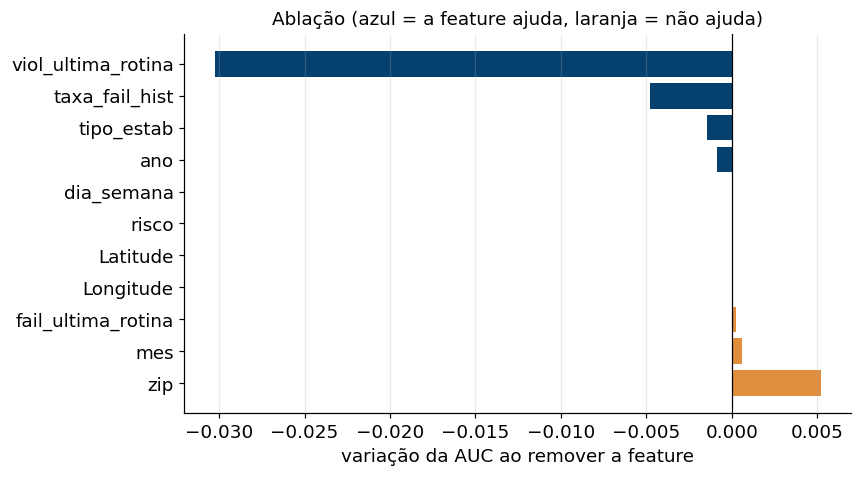

In [ ]:
# conjunto completo: colunas originais + histórico escolhido
num_sel  = BASE_NUM + hist_escolhido
cat_sel  = BASE_CAT
auc_full = medir(num_sel, cat_sel, base=False)
print(f"conjunto completo: {auc_full:.3f}")

linhas = []
for f in num_sel + cat_sel:
    auc = medir([c for c in num_sel if c != f], [c for c in cat_sel if c != f], base=False)
    linhas.append({"feature": f, "auc_sem_ela": auc, "delta": auc - auc_full})
ablacao = pd.DataFrame(linhas).sort_values("delta").reset_index(drop=True)
display(ablacao.round(4))

fig, ax = plt.subplots(figsize=(8, 4.5))
cores = ["#06406F" if v < 0 else "#E08D3C" for v in ablacao["delta"]]
ax.barh(ablacao["feature"], ablacao["delta"], color=cores)
ax.axvline(0, color="black", lw=.8)
ax.invert_yaxis()
ax.set_xlabel("variação da AUC ao remover a feature")
ax.set_title("Ablação (azul = a feature ajuda, laranja = não ajuda)")
ax.grid(axis="y", alpha=0)
plt.tight_layout()
plt.savefig(FIGS / "fi-07-ablacao.png", dpi=200, bbox_inches="tight")
plt.show()

| Coluna | Δ ao remover | Leitura |
|---|---|---|
| `viol_ultima_rotina` | −0,030 | de longe a mais importante |
| `taxa_fail_hist` | −0,005 | segundo sinal de histórico |
| `tipo_estab` | −0,001 | pequeno, mas ajuda |
| `ano` | −0,0009 | perto de zero |
| `dia_semana`, `risco` | 0,000 | não acrescentam nada |
| `Latitude`, `Longitude` | +0,0001 | não acrescentam nada |
| `fail_ultima_rotina` | +0,0002 | não acrescenta nada |
| `mes` | +0,0006 | não acrescenta nada |
| `zip` | +0,005 | atrapalha |

Três leituras:

* `viol_ultima_rotina`, a versão sem vazamento de Violations criada na seção 6, é a coluna que mais pesa. Reconstruir o vazamento de forma honesta valeu a pena.
* `zip` era a categórica mais associada ao Fail na seção 4 (V = 0,114), mas na validação temporal **piora** o modelo. Com dezenas de CEPs em one-hot, o modelo aprende padrões por CEP do passado que não se repetem no futuro. É o slide 22 de novo: associação não garante ganho.
* `fail_ultima_rotina` não acrescenta nada com `taxa_fail_hist` no modelo. `risco` confirma a seção 4 (Risk descreve o tipo de operação, não a chance de falhar), e `Latitude`/`Longitude` confirmam o ρ ≈ 0 visto lá.

**Decisão:** manter as colunas com Δ claramente negativo e descartar `zip`, `mes`, `fail_ultima_rotina`, `Latitude`, `Longitude`, `risco` e `dia_semana`. `ano` fica para o corte final.

### As candidatas que ficaram de fora fazem falta?

Na seção 6, `fails_anteriores`, `insp_anteriores`, `dias_desde_ultima` e `risco_x_tipo` ficaram de fora. Aqui colocamos cada uma de volta no conjunto completo para confirmar.

In [ ]:
# as candidatas que ficaram de fora fazem falta no conjunto completo?
for extra, eh_cat in [("fails_anteriores", False), ("insp_anteriores", False),
                      ("dias_desde_ultima", False), ("risco_x_tipo", True)]:
    num = num_sel if eh_cat else num_sel + [extra]
    cat = cat_sel + [extra] if eh_cat else cat_sel
    auc = medir(num, cat, base=False)
    print(f"+ {extra:18s}: {auc:.3f} (Δ = {auc - auc_full:+.3f})")

+ fails_anteriores  : 0.613 (Δ = +0.002)
+ insp_anteriores   : 0.611 (Δ = -0.000)
+ dias_desde_ultima : 0.612 (Δ = +0.000)
+ risco_x_tipo      : 0.612 (Δ = +0.001)


Nenhuma faz diferença: `fails_anteriores` +0,002, `risco_x_tipo` +0,001, `insp_anteriores` e `dias_desde_ultima` 0,000. `fails_anteriores` é quase a mesma informação de `taxa_fail_hist` (na seção 6, as duas renderam +0,022).

**Decisão:** descartar as quatro. `taxa_fail_hist` já representa o histórico de Fails e, por ser uma proporção, não cresce só porque o estabelecimento está há mais tempo no dataset.

### Conjunto final

Regra de corte: fica a coluna cuja remoção derruba a AUC em mais de **0,001** (`LIMIAR`). É um critério simples e explícito: quem ficou abaixo dele não fez diferença mensurável no modelo.

numéricas  : ['taxa_fail_hist', 'viol_ultima_rotina']
categóricas: ['tipo_estab']
AUC final  : 0.616 | treino 0.612 (ponto de partida 0.554, ganho +0.061)


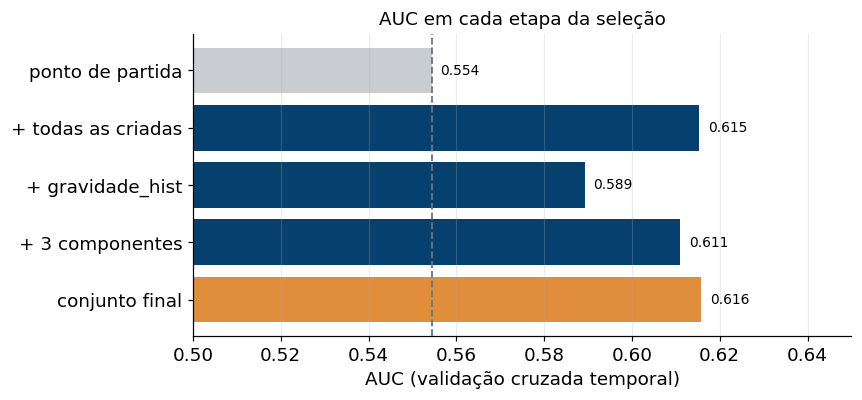

In [ ]:
LIMIAR = 0.001   # fica quem, ao sair, derruba a AUC mais que isso
ficam = ablacao.loc[ablacao["delta"] < -LIMIAR, "feature"].tolist()
num_final = [c for c in num_sel if c in ficam]
cat_final = [c for c in cat_sel if c in ficam]
auc_final, treino_final = medir(num_final, cat_final, base=False, treino=True)

print("numéricas  :", num_final)
print("categóricas:", cat_final)
print(f"AUC final  : {auc_final:.3f} | treino {treino_final:.3f} "
      f"(ponto de partida {auc_0:.3f}, ganho {auc_final - auc_0:+.3f})")

etapas_sel = {
    "ponto de partida": auc_0,
    "+ todas as criadas": auc_tudo,
    "+ gravidade_hist": auc_idx,
    "+ 3 componentes": auc_comp,
    "conjunto final": auc_final,
}
s = pd.Series(etapas_sel)
cores = ["#C9CDD2", "#06406F", "#06406F", "#06406F", "#E08D3C"]

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(s.index, s.values, color=cores)
ax.axvline(auc_0, color="#6C757D", ls="--", lw=1.2)
for i, v in enumerate(s.values):
    ax.text(v + .002, i, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlim(0.50, 0.65)
ax.invert_yaxis()
ax.set_xlabel("AUC (validação cruzada temporal)")
ax.set_title("AUC em cada etapa da seleção")
ax.grid(axis="y", alpha=0)
plt.tight_layout()
plt.savefig(FIGS / "fi-07-selecao-auc.png", dpi=200, bbox_inches="tight")
plt.show()

### Conclusão da Seleção de Features

| Coluna | Δ ao remover | Decisão |
|---|---|---|
| `viol_ultima_rotina` | −0,030 | **manter** |
| `taxa_fail_hist` | −0,005 | **manter** |
| `tipo_estab` | −0,001 | **manter** |
| `ano` | −0,0009 | descartar (abaixo do limiar) |
| `dia_semana`, `risco` | 0,000 | descartar |
| `Latitude`, `Longitude` | +0,0001 | descartar |
| `fail_ultima_rotina` | +0,0002 | descartar (coberta por `taxa_fail_hist`) |
| `mes` | +0,0006 | descartar |
| `zip` | +0,005 | descartar (piora na validação temporal) |
| `gravidade_hist` | não se aplica | substituída pelos componentes (0,611 contra 0,589) |
| `fails_anteriores`, `insp_anteriores`, `dias_desde_ultima`, `risco_x_tipo` | de 0,000 a +0,002 | descartar |

**Conjunto final:** `taxa_fail_hist`, `viol_ultima_rotina` e `tipo_estab`, com AUC de **0,616**, contra 0,554 do ponto de partida (+0,061) e 0,615 com todas as features criadas. Com 3 colunas o modelo chega ao mesmo resultado que com todas. A AUC de treino (0,612) ficou no nível da validação, então não há sinal de ajuste ao ruído (slide 21).

Conclusão geral: quase todo o sinal para prever o Fail está no histórico do estabelecimento, principalmente em quantas violações ele teve na última rotina. Localização (`zip`, `Latitude`, `Longitude`), classificação de risco e calendário, que pareciam promissores na correlação, não se sustentam quando o modelo é testado no futuro. Isso reforça o que apareceu na seção 6: correlação isolada não garante ganho real no modelo.

Observação: com `LIMIAR = 0.001`, `tipo_estab` passa por pouco e `ano` fica logo abaixo.

---
## 8 · Resultado — *para que serve o modelo?*

A AUC diz se o modelo ordena bem, mas não diz o que isso significa na prática. A pergunta aqui é a da prefeitura: **se os fiscais visitarem primeiro os estabelecimentos que o modelo aponta como mais arriscados, encontram mais Fails do que visitando em qualquer ordem?**

**Como medimos:**
- o modelo é uma **regressão logística** (`LogisticRegression`), a mesma das seções 6 e 7, para que o resultado seja comparável com a AUC da validação cruzada;
- usamos o conjunto final de features da seção 7 (`taxa_fail_hist`, `viol_ultima_rotina`, `tipo_estab`);
- treinamos com os **80% mais antigos** das inspeções e testamos nos **20% mais recentes**, que o modelo nunca viu, mantendo a regra da seção 1 de treinar no passado e testar no futuro;
- ordenamos as inspeções de teste do maior para o menor risco previsto e contamos quantos % dos Fails aparecem a cada fatia inspecionada (**curva de ganho**). A linha tracejada é a ordem aleatória: inspecionar 20% encontra, em média, 20% dos Fails.

teste: 2023-04-25 a 2026-09-23 | 26,418 inspeções | AUC = 0.623
inspecionando os 10% mais arriscados -> 16% dos Fails (aleatório: 10%)
inspecionando os 20% mais arriscados -> 30% dos Fails (aleatório: 20%)
inspecionando os 30% mais arriscados -> 42% dos Fails (aleatório: 30%)


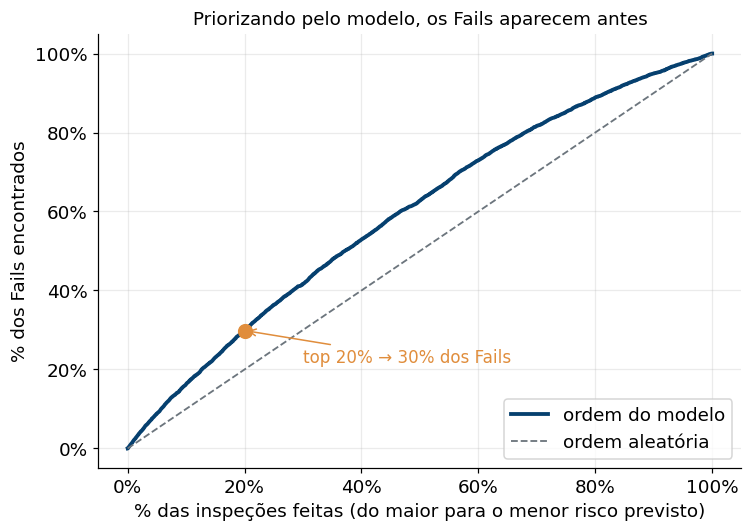

In [ ]:
# treina no passado (80% mais antigo) e testa no futuro (20% mais recente), que o modelo nunca viu
from sklearn.metrics import roc_auc_score

corte = int(len(ordem) * 0.8)
idx_treino, idx_teste = ordem[:corte], ordem[corte:]

etapas = [(make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), num_final)]
if cat_final:
    etapas.append((OneHotEncoder(handle_unknown="ignore", min_frequency=100), cat_final))
modelo = make_pipeline(make_column_transformer(*etapas), LogisticRegression(max_iter=2000))
modelo.fit(d.loc[idx_treino, num_final + cat_final], d.loc[idx_treino, "fail"])

teste = d.loc[idx_teste, ["fail"]].copy()
teste["risco_previsto"] = modelo.predict_proba(d.loc[idx_teste, num_final + cat_final])[:, 1]
print(f"teste: {d.loc[idx_teste, 'data'].min().date()} a {d.loc[idx_teste, 'data'].max().date()} "
      f"| {len(teste):,} inspeções | AUC = {roc_auc_score(teste['fail'], teste['risco_previsto']):.3f}")

# ordena do mais arriscado para o menos e acumula os Fails encontrados
teste = teste.sort_values("risco_previsto", ascending=False)
pct_inspecionado = np.arange(1, len(teste) + 1) / len(teste)
pct_fails = teste["fail"].cumsum().to_numpy() / teste["fail"].sum()

for p in [0.10, 0.20, 0.30]:
    achados = pct_fails[int(p * len(teste)) - 1]
    print(f"inspecionando os {p:.0%} mais arriscados -> {achados:.0%} dos Fails (aleatório: {p:.0%})")

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(pct_inspecionado, pct_fails, color="#06406F", lw=2.5, label="ordem do modelo")
ax.plot([0, 1], [0, 1], color="#6C757D", ls="--", lw=1.2, label="ordem aleatória")
p20 = pct_fails[int(0.2 * len(teste)) - 1]
ax.scatter([0.2], [p20], color="#E08D3C", s=80, zorder=3)
ax.annotate(f"top 20% → {p20:.0%} dos Fails", (0.2, p20), xytext=(0.30, p20 - 0.08),
            fontsize=11, color="#E08D3C", arrowprops=dict(arrowstyle="->", color="#E08D3C"))
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("% das inspeções feitas (do maior para o menor risco previsto)")
ax.set_ylabel("% dos Fails encontrados")
ax.set_title("Priorizando pelo modelo, os Fails aparecem antes")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(FIGS / "slide-09-ganho.png", dpi=200, bbox_inches="tight")
plt.show()

### Conclusão do Resultado

Teste em **26.418 inspeções** (abr/2023 a set/2026), que o modelo não viu no treino: **AUC = 0,623**, próxima da validação cruzada da seção 7 (0,616), ou seja, o modelo não piorou ao chegar no futuro.

| Inspecionando os mais arriscados | Fails encontrados | Ordem aleatória |
|---|---|---|
| 10% | 16% | 10% |
| **20%** | **30%** | 20% |
| 30% | 42% | 30% |

📌 **Priorizando pelo modelo, os primeiros 20% das inspeções encontram 30% dos Fails, cerca de 1,5 vez o que encontraria uma ordem aleatória.**

**Limitações:**
- o ganho é **moderado**: o modelo serve para **priorizar** a fila de inspeções, não para afirmar quais estabelecimentos vão falhar;
- as features foram escolhidas na seção 7 com validação cruzada sobre o período inteiro, que inclui os anos do teste, então o resultado pode estar levemente otimista;
- os números acima são da extração congelada de 2026-09-24.

In [ ]:
print("Features numéricas:", num_final)
print("Features categóricas:", cat_final)

print("\nLinhas de treino:", len(idx_treino))
print("Linhas de teste:", len(idx_teste))

print(f"\nAUC de validação da regressão logística: {auc_final:.3f}")

display(modelo)

Features numéricas: ['taxa_fail_hist', 'viol_ultima_rotina']
Features categóricas: ['tipo_estab']

Linhas de treino: 105670
Linhas de teste: 26418

AUC de validação da regressão logística: 0.616


Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('pipeline',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 strategy='median')),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  ['taxa_fail_hist',
                                                   'viol_ultima_rotina']),
                                                 ('onehotencoder',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                min_frequency=100),
                                                  ['tipo_estab'])])),
                ('logisticregression', LogisticRegression(max_iter=2000))])

---
## Comparação de modelos — Regressão Logística × Random Forest

Nesta etapa, comparamos a regressão logística com uma Random Forest. Para que a comparação seja justa, os dois modelos utilizam as mesmas features, o mesmo pré-processamento e a mesma divisão temporal.

A Random Forest consegue representar relações não lineares e interações entre as features, mas é menos interpretável que a regressão logística.

In [ ]:
features_finais = num_final + cat_final

X_comparacao = d[features_finais]
y_comparacao = d["fail"]

X_treino_rf = X_comparacao.loc[idx_treino]
X_teste_rf = X_comparacao.loc[idx_teste]

y_treino_rf = y_comparacao.loc[idx_treino]
y_teste_rf = y_comparacao.loc[idx_teste]

print("Treino:", X_treino_rf.shape)
print("Teste:", X_teste_rf.shape)
print("Features utilizadas:", features_finais)

Treino: (105670, 3)
Teste: (26418, 3)
Features utilizadas: ['taxa_fail_hist', 'viol_ultima_rotina', 'tipo_estab']


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# Recria a regressão logística sem aproveitar o treinamento anterior
modelo_log_comparacao = clone(modelo)

# Copia exatamente o pré-processamento usado pela regressão logística
mesmo_preprocessamento = clone(
    modelo.steps[0][1]
)

modelo_rf = Pipeline([
    (
        "preprocessamento",
        mesmo_preprocessamento
    ),
    (
        "random_forest",
        RandomForestClassifier(
            n_estimators=200,
            max_depth=12,
            min_samples_leaf=10,
            random_state=42,
            n_jobs=-1
        )
    )
])

print(modelo_rf)

Pipeline(steps=[('preprocessamento',
                 ColumnTransformer(transformers=[('pipeline',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 strategy='median')),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  ['taxa_fail_hist',
                                                   'viol_ultima_rotina']),
                                                 ('onehotencoder',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                min_frequency=100),
                                                  ['tipo_

In [ ]:
modelo_log_comparacao.fit(
    X_treino_rf,
    y_treino_rf
)

modelo_rf.fit(
    X_treino_rf,
    y_treino_rf
)

print("Modelos treinados.")

Modelos treinados.


In [ ]:
prob_log = modelo_log_comparacao.predict_proba(
    X_teste_rf
)[:, 1]

prob_rf = modelo_rf.predict_proba(
    X_teste_rf
)[:, 1]

auc_log_teste = roc_auc_score(
    y_teste_rf,
    prob_log
)

auc_rf_teste = roc_auc_score(
    y_teste_rf,
    prob_rf
)

print(f"AUC Logística no teste:     {auc_log_teste:.3f}")
print(f"AUC Random Forest no teste: {auc_rf_teste:.3f}")
print(f"Diferença:                  {auc_rf_teste - auc_log_teste:+.3f}")

AUC Logística no teste:     0.623
AUC Random Forest no teste: 0.619
Diferença:                  -0.004


,modelo,AUC_teste
0,Regressão logística,0.622786
1,Random Forest,0.618923


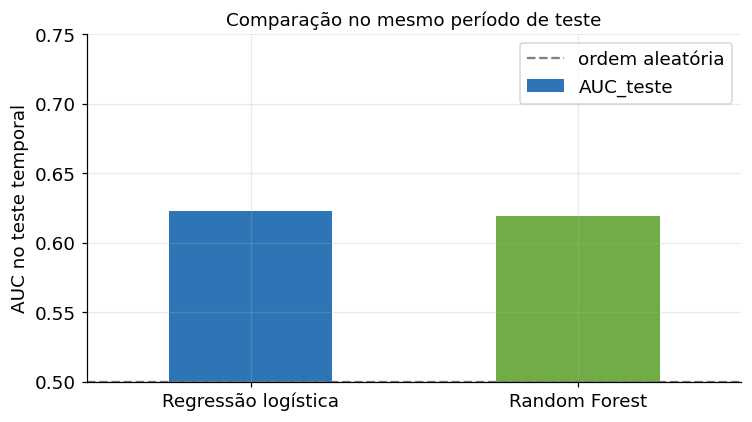

In [ ]:
comparacao_modelos = pd.DataFrame({
    "modelo": [
        "Regressão logística",
        "Random Forest"
    ],
    "AUC_teste": [
        auc_log_teste,
        auc_rf_teste
    ]
}).sort_values("AUC_teste", ascending=False)

display(comparacao_modelos)

ax = comparacao_modelos.plot.bar(
    x="modelo",
    y="AUC_teste",
    legend=False,
    color=["#2E75B6", "#70AD47"],
    figsize=(7, 4)
)

ax.axhline(
    0.5,
    color="gray",
    linestyle="--",
    label="ordem aleatória"
)

ax.set_ylim(0.5, 0.75)
ax.set_ylabel("AUC no teste temporal")
ax.set_xlabel("")
ax.set_title("Comparação no mesmo período de teste")
ax.legend()

plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(FIGS / "fi-09-comparacao-modelos.png", dpi=200, bbox_inches="tight")
plt.show()

### Conclusão da comparação

A Random Forest obteve AUC de 0,619, enquanto a regressão logística obteve 0,623 no mesmo período de teste. Portanto, a Random Forest não melhorou o resultado. Como a diferença é pequena e a regressão logística é mais simples e interpretável, ela permanece como o modelo escolhido. Os dois resultados indicam desempenho moderado e superior a uma ordenação aleatória.

### Corte temporal
Nesta seção, filtramos a base de dados a partir de 2018 para remover ruidos historicos e focamos na analise do impacto da pandemia doe COVID-19. Em seguida, estabelecimos uma partição cronologica estrita (treino, validação e teste) para evitar vazamento de dados.

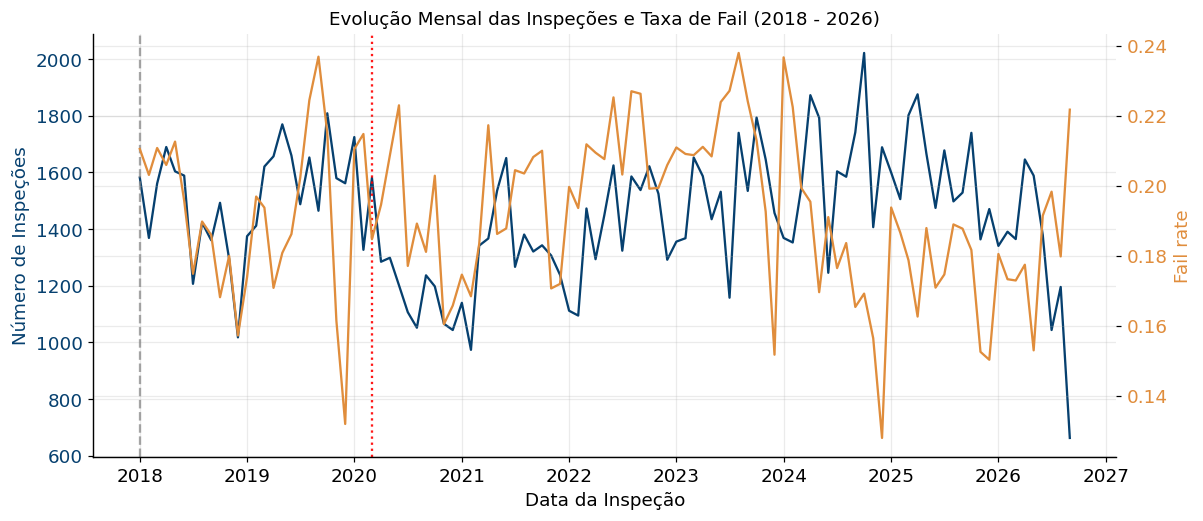

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# pré processamento e filtrando a partir de 2018
df_q['Inspection Date'] = pd.to_datetime(df_q['Inspection Date'], format='%m/%d/%Y', errors='coerce')
df_18 = df_q[df_q['Inspection Date'].dt.year >= 2018].copy()

# criacao do alvo fail binario
df_18['Fail'] = (df_18['Results'] == 'Fail').astype(int)

# agregacao mensal
monthly_agg = df_18.groupby(df_18['Inspection Date'].dt.to_period('M')).agg(
    n_inspections=('Inspection ID', 'count'),
    fail_rate=('Fail', 'mean')
).reset_index()
monthly_agg['Inspection Date'] = monthly_agg['Inspection Date'].dt.to_timestamp()

fig, ax1 = plt.subplots(figsize=(12, 5))

# eixo esquerdo : numéro de inspecoes
color = '#06406F'
ax1.set_xlabel('Data da Inspeção')
ax1.set_ylabel('Número de Inspeções', color=color)
ax1.plot(monthly_agg['Inspection Date'], monthly_agg['n_inspections'], color=color, linewidth=1.5, label='Nº Inspeções')
ax1.tick_params(axis='y', labelcolor=color)

# eixo direito : fail rate
ax2 = ax1.twinx()
color = '#E08D3C'
ax2.set_ylabel('Fail rate', color=color)
ax2.plot(monthly_agg['Inspection Date'], monthly_agg['fail_rate'], color=color, linewidth=1.5, label='Fail rate')
ax2.tick_params(axis='y', labelcolor=color)

# marcar visualmente 2018 et 03/2020 (inicio do periodo e covid-19)
ax1.axvline(pd.to_datetime('2018-01-01'), color='gray', linestyle='--', alpha=0.7, label='Início (2018)')
ax1.axvline(pd.to_datetime('2020-03-01'), color='red', linestyle=':', alpha=0.9, label='COVID-19 (2020)')

plt.title('Evolução Mensal das Inspeções e Taxa de Fail (2018 - 2026)')
plt.show()

In [ ]:
# marcos temporais fixos
TRAIN_END = pd.Timestamp('2022-12-31')
VAL_END = pd.Timestamp('2024-12-31')

# criando mascara
mask_train = df_18['Inspection Date'] <= TRAIN_END
mask_val = (df_18['Inspection Date'] > TRAIN_END) & (df_18['Inspection Date'] <= VAL_END)
mask_test = df_18['Inspection Date'] > VAL_END

# attribucao aos dataframes correspondentes
train_df = df_18[mask_train] # 2018 a fim de 2022
val_df = df_18[mask_val] # 2023 a fim de 2024
test_df = df_18[mask_test] # 2025 até o fim

# resultados
print(f"Treino: {len(train_df):,} linhas ({len(train_df)/len(df_18)*100:.1f}%)")
print(f"Validação: {len(val_df):,} linhas ({len(val_df)/len(df_18)*100:.1f}%)")
print(f"Teste: {len(test_df):,} linhas ({len(test_df)/len(df_18)*100:.1f}%)")

Treino: 84,171 linhas (55.2%)
Validação: 37,489 linhas (24.6%)
Teste: 30,819 linhas (20.2%)


152 479 inspecoes analisadas a partir de 2018. Treino : 55,2% em 5 anos, e validaçao : 24,6% em 2 anos.

## Features históricas do estabelecimento (lags)

Nesta seção, reunimos em uma única função as informações do histórico de cada estabelecimento. Para prever uma inspeção, usamos somente dados de inspeções anteriores: resultado da última rotina, violações da última rotina, taxa histórica de Fail e dias desde a última inspeção.

As inspeções são ordenadas por licença e data. O uso de `shift(1)` impede que o resultado da própria inspeção ou informações futuras sejam usados na previsão.

In [ ]:
def criar_features_historicas(dados):
    """
    Cria features usando somente inspeções anteriores
    do mesmo estabelecimento.
    """

    base = dados.copy()

    # Garante que a data está no formato correto
    base["Inspection Date"] = pd.to_datetime(
        base["Inspection Date"],
        errors="coerce"
    )

    # Guarda a ordem original para recuperá-la no final
    base["_ordem_original"] = np.arange(len(base))

    # License # identifica o estabelecimento.
    # Zero e valores inválidos não são licenças válidas.
    base["_licenca_hist"] = pd.to_numeric(
        base["License #"],
        errors="coerce"
    ).replace(0, np.nan)

    # Conta quantas violações foram registradas na inspeção atual.
    # O caractere "|" separa diferentes violações no texto.
    texto_violacoes = (
        base["Violations"]
        .fillna("")
        .astype(str)
        .str.strip()
    )

    base["_n_violacoes_atual"] = np.where(
        texto_violacoes.eq(""),
        0,
        texto_violacoes.str.count(r"\|") + 1
    )

    # Coloca as inspeções de cada estabelecimento em ordem temporal
    base = base.sort_values(
        ["_licenca_hist", "Inspection Date", "Inspection ID"],
        kind="stable",
        na_position="last"
    )

    # Linhas com licença válida podem receber histórico
    licenca_valida = base["_licenca_hist"].notna()

    historico = base.loc[licenca_valida].copy()

    por_estabelecimento = historico.groupby(
        "_licenca_hist",
        sort=False
    )

    # Resultado da inspeção imediatamente anterior
    historico["fail_ultima_rotina"] = (
        por_estabelecimento["Fail"].shift(1)
    )

    # Número de violações registrado na inspeção anterior
    historico["viol_ultima_rotina"] = (
        por_estabelecimento["_n_violacoes_atual"].shift(1)
    )

    # Proporção de Fails somente nas inspeções anteriores
    historico["taxa_fail_hist"] = (
        por_estabelecimento["Fail"]
        .transform(lambda serie: serie.shift(1).expanding().mean())
    )

    # Data da inspeção anterior
    data_anterior = (
        por_estabelecimento["Inspection Date"].shift(1)
    )

    # Intervalo desde a inspeção anterior
    historico["dias_desde_ultima_rotina"] = (
        historico["Inspection Date"] - data_anterior
    ).dt.days

    features_criadas = [
        "fail_ultima_rotina",
        "viol_ultima_rotina",
        "taxa_fail_hist",
        "dias_desde_ultima_rotina"
    ]

    # Cria as colunas na base completa
    for coluna in features_criadas:
        base[coluna] = np.nan
        base.loc[historico.index, coluna] = historico[coluna]

    # Indica se o estabelecimento possui uma inspeção anterior
    base["tem_historico"] = (
        base["fail_ultima_rotina"].notna().astype(int)
    )

    # Recupera a ordem original das linhas
    base = (
        base
        .sort_values("_ordem_original")
        .drop(
            columns=[
                "_ordem_original",
                "_licenca_hist",
                "_n_violacoes_atual"
            ]
        )
    )

    return base

In [ ]:
df_hist = criar_features_historicas(df_18)

features_historicas = [
    "fail_ultima_rotina",
    "viol_ultima_rotina",
    "taxa_fail_hist",
    "dias_desde_ultima_rotina"
]

print("Linhas da base original:", len(df_18))
print("Linhas após criar as features:", len(df_hist))
print("\nFeatures históricas criadas:")

for coluna in features_historicas:
    print("-", coluna)

Linhas da base original: 152479
Linhas após criar as features: 152479

Features históricas criadas:
- fail_ultima_rotina
- viol_ultima_rotina
- taxa_fail_hist
- dias_desde_ultima_rotina


In [ ]:
licencas_validas = (
    pd.to_numeric(df_hist["License #"], errors="coerce")
    .replace(0, np.nan)
)

# Escolhe uma licença que possui várias inspeções
licenca_exemplo = licencas_validas.value_counts().index[0]

colunas_exemplo = [
    "License #",
    "Inspection Date",
    "Results",
    "Fail",
    "Violations",
    "fail_ultima_rotina",
    "viol_ultima_rotina",
    "taxa_fail_hist",
    "dias_desde_ultima_rotina"
]

exemplo_historico = (
    df_hist.loc[
        licencas_validas.eq(licenca_exemplo),
        colunas_exemplo
    ]
    .sort_values(["Inspection Date"])
)

print("Licença usada como exemplo:", licenca_exemplo)
display(exemplo_historico.head(10))

Licença usada como exemplo: 2594606.0


,License #,Inspection Date,Results,Fail,Violations,fail_ultima_rotina,viol_ultima_rotina,taxa_fail_hist,dias_desde_ultima_rotina
140131,2594606.0,2018-04-19,Fail,1,"11. ADEQUATE NUMBER, CONVENIENT, ACCESSIBLE, D...",NaN,NaN,NaN,NaN
136383,2594606.0,2018-09-20,Not Ready,0,NaN,1.0,7.0,1.000000,154.0
311272,2594606.0,2018-10-16,Pass w/ Conditions,0,"3. MANAGEMENT, FOOD EMPLOYEE AND CONDITIONAL E...",0.0,0.0,0.500000,26.0
128161,2594606.0,2019-01-24,Fail,1,2. CITY OF CHICAGO FOOD SERVICE SANITATION CER...,0.0,10.0,0.333333,100.0
42494,2594606.0,2019-02-05,Fail,1,2. CITY OF CHICAGO FOOD SERVICE SANITATION CER...,1.0,7.0,0.500000,12.0
128639,2594606.0,2019-02-21,Pass w/ Conditions,0,2. CITY OF CHICAGO FOOD SERVICE SANITATION CER...,1.0,6.0,0.600000,16.0
8488,2594606.0,2019-07-02,Fail,1,"1. PERSON IN CHARGE PRESENT, DEMONSTRATES KNOW...",0.0,3.0,0.500000,131.0
123139,2594606.0,2019-07-12,Fail,1,"1. PERSON IN CHARGE PRESENT, DEMONSTRATES KNOW...",1.0,13.0,0.571429,10.0
121233,2594606.0,2019-07-18,Pass w/ Conditions,0,"1. PERSON IN CHARGE PRESENT, DEMONSTRATES KNOW...",1.0,10.0,0.625000,6.0
293628,2594606.0,2020-05-08,Fail,1,"1. PERSON IN CHARGE PRESENT, DEMONSTRATES KNOW...",0.0,9.0,0.555556,295.0


In [ ]:
resumo_features = pd.DataFrame({
    "tipo": df_hist[features_historicas].dtypes.astype(str),
    "valores_preenchidos": df_hist[features_historicas].notna().sum(),
    "valores_ausentes": df_hist[features_historicas].isna().sum(),
    "percentual_ausente": (
        df_hist[features_historicas].isna().mean() * 100
    ).round(2)
})

display(resumo_features)

print(
    "Intervalos negativos encontrados:",
    int((df_hist["dias_desde_ultima_rotina"] < 0).sum())
)

print(
    "Linhas com histórico disponível:",
    int(df_hist["tem_historico"].sum())
)

print(
    "Linhas sem inspeção anterior:",
    int((df_hist["tem_historico"] == 0).sum())
)

,tipo,valores_preenchidos,valores_ausentes,percentual_ausente
fail_ultima_rotina,float64,123622,28857,18.93
viol_ultima_rotina,float64,123622,28857,18.93
taxa_fail_hist,float64,123622,28857,18.93
dias_desde_ultima_rotina,float64,123622,28857,18.93


Intervalos negativos encontrados: 0
Linhas com histórico disponível: 123622
Linhas sem inspeção anterior: 28857


In [ ]:
checagem = df_hist.copy()

checagem["_licenca"] = (
    pd.to_numeric(checagem["License #"], errors="coerce")
    .replace(0, np.nan)
)

primeiras_inspecoes = (
    checagem.loc[checagem["_licenca"].notna()]
    .sort_values(
        ["_licenca", "Inspection Date", "Inspection ID"]
    )
    .groupby("_licenca", sort=False)
    .head(1)
)

percentual_sem_historico = (
    primeiras_inspecoes[features_historicas]
    .isna()
    .all(axis=1)
    .mean() * 100
)

print(
    "Primeiras inspeções sem histórico:",
    f"{percentual_sem_historico:.2f}%"
)

Primeiras inspeções sem histórico: 100.00%


In [ ]:
treino_hist = df_hist.loc[mask_train].copy()
validacao_hist = df_hist.loc[mask_val].copy()
teste_hist = df_hist.loc[mask_test].copy()

resumo_cortes = pd.DataFrame({
    "período": ["Treino", "Validação", "Teste"],
    "linhas": [
        len(treino_hist),
        len(validacao_hist),
        len(teste_hist)
    ],
    "data_inicial": [
        treino_hist["Inspection Date"].min(),
        validacao_hist["Inspection Date"].min(),
        teste_hist["Inspection Date"].min()
    ],
    "data_final": [
        treino_hist["Inspection Date"].max(),
        validacao_hist["Inspection Date"].max(),
        teste_hist["Inspection Date"].max()
    ],
    "taxa_de_fail": [
        treino_hist["Fail"].mean(),
        validacao_hist["Fail"].mean(),
        teste_hist["Fail"].mean()
    ]
})

resumo_cortes["taxa_de_fail"] = (
    resumo_cortes["taxa_de_fail"] * 100
).round(2)

display(resumo_cortes)

,período,linhas,data_inicial,data_final,taxa_de_fail
0,Treino,84171,2018-01-02,2022-12-30,19.55
1,Validação,37489,2023-01-03,2024-12-31,19.52
2,Teste,30819,2025-01-02,2026-09-23,17.77


### Conclusão das features históricas

Foram criadas quatro features baseadas exclusivamente nas inspeções anteriores de cada estabelecimento:

- `fail_ultima_rotina`: indica se a inspeção anterior terminou em Fail;
- `viol_ultima_rotina`: número de violações registrado na inspeção anterior;
- `taxa_fail_hist`: proporção de Fails no histórico anterior;
- `dias_desde_ultima_rotina`: intervalo de dias desde a inspeção anterior.

As inspeções foram ordenadas por licença e data, e o uso de `shift(1)` garantiu que nenhuma linha utilizasse o próprio resultado ou informações futuras. Estabelecimentos sem licença válida ou sem inspeção anterior permanecem sem histórico.

As bases `treino_hist`, `validacao_hist` e `teste_hist` estão prontas para serem utilizadas na comparação dos modelos.

---
## Novas correlações com Fail — estabelecimento e local

**Pergunta:** além do histórico do próprio estabelecimento, o que mais anda junto com o Fail?

**Ponto de partida.** A seção 7 fechou o conjunto final em `taxa_fail_hist`, `viol_ultima_rotina` e
`tipo_estab`, e concluiu que localização e calendário "não se sustentam quando o modelo é testado no
futuro". Esta seção volta a essas hipóteses para verificar se a conclusão vale para qualquer forma da
variável ou só para a forma testada.

**Como cada experimento é registrado** (toda mudança termina em resultado e conclusão, e a conclusão abre o próximo ciclo):

| passo | conteúdo |
|---|---|
| 1. Hipótese | o que esperamos e por quê |
| 2. Critério definido antes | **mantém** se a AUC de validação subir mais que `LIMIAR = 0,001` **e** o IC 95% (bootstrap) do ganho ficar acima de zero |
| 3. Mudança | feature criada |
| 4. Resultado | número e gráfico |
| 5. Conclusão | manter ou descartar, e por quê |
| 6. Próximo ciclo | nova hipótese que surgiu |

**Regras para evitar vazamento**
- Recorte: inspeções **Canvass** com resultado sanitário, a partir de **2018** (mesmo corte da seção "Corte temporal").
- Split fixo: treino até 31/12/2022, validação 2023–2024, **teste a partir de 2025 (não é usado aqui)**.
- A associação com o alvo (Cramér's V, Spearman, taxa por grupo) é calculada **só no treino**.
- Toda feature usa só informação **anterior** à data da inspeção.
- A seção trabalha sobre uma cópia (`df_z`) e usa nomes próprios (`dz`, `tr_z`, `va_z`...), sem alterar as variáveis das seções anteriores.

In [ ]:
from scipy.stats import chi2_contingency, spearmanr
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score
from sklearn.cluster import KMeans

AZUL, LARANJA, CINZA = "#06406F", "#E08D3C", "#9AA0A6"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})

df_z = df.copy()
print(df_z.shape)

(315963, 17)


### 0 · Preparação: base, histórico de referência e split

O histórico é calculado sobre **todas** as inspeções, inclusive as anteriores a 2018, porque isso é
passado legítimo. Depois, a base é recortada em Canvass a partir de 2018.

In [ ]:
df_z["data"] = pd.to_datetime(df_z["Inspection Date"], format="%m/%d/%Y")
df_z["lic"] = pd.to_numeric(df_z["License #"], errors="coerce").replace(0, np.nan)
df_z["tipo_insp"] = df_z["Inspection Type"].fillna("").astype(str).str.strip().str.upper()
df_z["res"] = df_z["Results"].fillna("").astype(str).str.strip().str.upper()
df_z["_fail"] = df_z["res"].eq("FAIL").astype(int)
df_z["n_viol"] = df_z["Violations"].str.count(r"\|").add(1).fillna(0)
df_z = df_z.sort_values(["data", "Inspection ID"]).reset_index(drop=True)
rotina_z = df_z["tipo_insp"].eq("CANVASS") & df_z["res"].isin(["PASS", "PASS W/ CONDITIONS", "FAIL"])

# histórico de referência (só o passado de cada licença)
h_z = df_z[df_z["lic"].notna()].sort_values(["lic", "data", "Inspection ID"])
g_z = h_z.groupby("lic")
df_z.loc[h_z.index, "taxa_fail_hist"] = (g_z["_fail"].cumsum() - h_z["_fail"]) / g_z.cumcount().replace(0, np.nan)
df_z.loc[h_z.index, "primeira_data"] = g_z["data"].cummin()          # 1ª inspeção registrada ATÉ a data
r_z = h_z[rotina_z.loc[h_z.index]]
df_z.loc[r_z.index, "viol_ultima_rotina"] = r_z.groupby("lic")["n_viol"].shift()

# base do problema
dz = df_z[rotina_z & (df_z["data"].dt.year >= 2018)].copy()
dz["fail"] = dz["_fail"]
TRAIN_END_Z, VAL_END_Z = pd.Timestamp("2022-12-31"), pd.Timestamp("2024-12-31")
tr_z = dz["data"] <= TRAIN_END_Z
va_z = (dz["data"] > TRAIN_END_Z) & (dz["data"] <= VAL_END_Z)

ft_z = dz["Facility Type"].fillna("DESCONHECIDO").astype(str).str.strip().str.upper()
dz["tipo_estab"] = ft_z.where(ft_z.isin(ft_z[tr_z].value_counts().head(10).index), "OUTROS")

print(f"base: {len(dz):,} inspeções | treino {tr_z.sum():,} | validação {va_z.sum():,} | teste (reservado) {(~tr_z & ~va_z).sum():,}")
print(f"taxa de Fail: treino {dz.loc[tr_z, 'fail'].mean():.1%} | validação {dz.loc[va_z, 'fail'].mean():.1%}")

base: 62,994 inspeções | treino 34,179 | validação 15,872 | teste (reservado) 12,943
taxa de Fail: treino 24.2% | validação 25.3%


#### Função de avaliação

Treina uma regressão logística no **treino** e mede a AUC na **validação**, comparando com o conjunto de
referência. O intervalo de confiança do ganho vem de um bootstrap pareado (as mesmas linhas reamostradas
para os dois modelos). É uma versão local; quando a função de avaliação comum do grupo ficar pronta,
os números devem ser conferidos com ela.

In [ ]:
REF_NUM, REF_CAT = ["taxa_fail_hist", "viol_ultima_rotina"], ["tipo_estab"]
LIMIAR_Z = 0.001
yv_z = dz.loc[va_z, "fail"].to_numpy()
rng_z = np.random.default_rng(0)
BOOT_Z = [rng_z.integers(0, len(yv_z), len(yv_z)) for _ in range(200)]

def prever_local(num, cat):
    etapas_z = []
    if num:
        etapas_z.append((make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), num))
    if cat:
        etapas_z.append((OneHotEncoder(handle_unknown="ignore", min_frequency=100), cat))
    modelo_z = make_pipeline(make_column_transformer(*etapas_z), LogisticRegression(max_iter=2000))
    modelo_z.fit(dz.loc[tr_z, num + cat], dz.loc[tr_z, "fail"])
    return modelo_z.predict_proba(dz.loc[va_z, num + cat])[:, 1]

p_ref = prever_local(REF_NUM, REF_CAT)
AUC_REF = roc_auc_score(yv_z, p_ref)
print(f"referência (taxa_fail_hist + viol_ultima_rotina + tipo_estab): AUC validação = {AUC_REF:.4f}")

def avaliar_local(nome, num=(), cat=(), troca_cat=None):
    num = REF_NUM + list(num)
    cat = list(troca_cat) if troca_cat else REF_CAT + list(cat)
    p_z = prever_local(num, cat)
    auc = roc_auc_score(yv_z, p_z)
    deltas_z = [roc_auc_score(yv_z[i], p_z[i]) - roc_auc_score(yv_z[i], p_ref[i]) for i in BOOT_Z]
    lo_z, hi_z = np.percentile(deltas_z, [2.5, 97.5])
    decisao = "MANTER" if (auc - AUC_REF > LIMIAR_Z and lo_z > 0) else "descartar"
    return {"candidata": nome, "auc": auc, "ganho": auc - AUC_REF, "ic_baixo": lo_z, "ic_alto": hi_z, "decisão": decisao}

def cramers_v_local(x_z, y_z):
    tab_z = pd.crosstab(x_z, y_z)
    chi2, p_z = chi2_contingency(tab_z, correction=False)[:2]
    n_z = tab_z.to_numpy().sum(); r_, k_ = tab_z.shape
    phi2 = max(0, chi2 / n_z - (k_ - 1) * (r_ - 1) / (n_z - 1))
    rc, kc = r_ - (r_ - 1) ** 2 / (n_z - 1), k_ - (k_ - 1) ** 2 / (n_z - 1)
    return np.sqrt(phi2 / min(kc - 1, rc - 1)), p_z

def grafico_ganho(tab_z, titulo):
    tab_z = tab_z.sort_values("ganho")
    fig_z, ax_z = plt.subplots(figsize=(8, .45 * len(tab_z) + 1.2))
    cores = [AZUL if dec == "MANTER" else CINZA for dec in tab_z["decisão"]]
    ax_z.barh(tab_z["candidata"], tab_z["ganho"], color=cores, height=.6)
    ax_z.errorbar(tab_z["ganho"], tab_z["candidata"], xerr=[tab_z["ganho"] - tab_z["ic_baixo"], tab_z["ic_alto"] - tab_z["ganho"]],
                fmt="none", ecolor="black", elinewidth=1, capsize=3)
    folga = .02 * (tab_z["ic_alto"].max() - min(tab_z["ic_baixo"].min(), 0))
    for y_z, (v_z, lo_z, hi_z) in enumerate(zip(tab_z["ganho"], tab_z["ic_baixo"], tab_z["ic_alto"])):
        ax_z.text(max(hi_z, 0) + folga if v_z >= 0 else min(lo_z, 0) - folga, y_z, f"{v_z:+.4f}", va="center",
                ha="left" if v_z >= 0 else "right", fontsize=9)
    esq, dir_ = ax_z.get_xlim(); ax_z.set_xlim(esq - 6 * folga, dir_ + 6 * folga)
    ax_z.axvline(0, color="black", lw=.8)
    ax_z.set_xlabel("ganho de AUC na validação (barra = IC 95%)   ·   azul = mantida, cinza = descartada")
    ax_z.set_title(titulo, loc="left")
    ax_z.grid(axis="y", alpha=0)
    plt.tight_layout(); plt.show()

referência (taxa_fail_hist + viol_ultima_rotina + tipo_estab): AUC validação = 0.6191


---
### Ciclo 1 · Atributos do estabelecimento e do local

#### 1. Hipóteses

| # | candidata | hipótese | forma |
|---|---|---|---|
| H1 | `idade_anos` | estabelecimentos novos ainda não dominam as rotinas e falham mais | anos desde a 1ª inspeção registrada da licença |
| H2 | `dia_semana` | inspeções na segunda pegam a cozinha depois do fim de semana | categoria |
| H3 | `rede` / `log_n_lic` | redes têm processos padronizados e falham menos que independentes | nº de licenças com o mesmo nome **até a data** |
| H4 | `zip` | a região importa (V = 0,114 na seção 4), mas foi descartada na seção 7 como one-hot | one-hot **e** taxa de Fail passada do Zip |
| H5 | `regiao` | agrupar latitude/longitude em 25 regiões (k-means ajustado só no treino) resume a localização melhor que o Zip | one-hot **e** taxa passada |
| H6 | `tipo_estab_det` | o top 10 + "OUTROS" esconde tipos com taxas muito diferentes | top 25 + grupos por palavra-chave |

#### 2. Critério
Definido na introdução: ganho > 0,001 **e** IC 95% do ganho acima de zero.

In [ ]:
# H1 · idade
dz["idade_anos"] = (dz["data"] - dz["primeira_data"]).dt.days / 365.25

# H2 · dia da semana
dz["dia_semana"] = dz["data"].dt.day_name()

# H3 · rede: licenças distintas com o mesmo nome, contando só as que já tinham aparecido até a data
df_z["nome"] = (df_z["DBA Name"].fillna("").astype(str).str.upper()
              .str.replace(r"[^A-Z0-9 ]", "", regex=True).str.replace(r"\s+", " ", regex=True).str.strip())
primeira_z = (df_z[df_z["lic"].notna()].groupby(["nome", "lic"])["data"].min().reset_index().sort_values("data"))
primeira_z["n"] = primeira_z.groupby("nome").cumcount() + 1
dz["nome"] = df_z.loc[dz.index, "nome"]
aux_z = pd.merge_asof(dz[["data", "nome"]].reset_index().sort_values("data"), primeira_z[["data", "nome", "n"]],
                    on="data", by="nome", direction="backward").set_index("index")
dz["n_lic_mesmo_nome"] = aux_z["n"].reindex(dz.index).fillna(1)
dz["log_n_lic"] = np.log1p(dz["n_lic_mesmo_nome"])
dz["rede"] = pd.cut(dz["n_lic_mesmo_nome"], [0, 1, 4, 19, np.inf],
                   labels=["1 (independente)", "2-4", "5-19", "20+"]).astype(str)

# H4 · zip, e a taxa de Fail passada de um grupo (acumulada desde 2018, só dias anteriores,
#      suavizada para a taxa geral passada com peso m)
dz["zip"] = pd.to_numeric(dz["Zip"], errors="coerce").map(lambda z_z: f"{z_z:.0f}" if pd.notna(z_z) else "SEM")

def taxa_acumulada(col, m=50):
    agg = dz.groupby([col, "data"])["fail"].agg(["sum", "count"]).reset_index().sort_values([col, "data"])
    gg_z = agg.groupby(col)
    agg["s"] = gg_z["sum"].cumsum() - agg["sum"]          # tira o próprio dia
    agg["c"] = gg_z["count"].cumsum() - agg["count"]
    geral = dz.groupby("data")["fail"].agg(["sum", "count"]).cumsum().shift().fillna(0)
    agg = agg.merge(geral.rename(columns={"sum": "sg", "count": "cg"}), left_on="data", right_index=True)
    prior = (agg["sg"] / agg["cg"]).fillna(dz.loc[tr_z, "fail"].mean())
    agg["t"] = (agg["s"] + m * prior) / (agg["c"] + m)
    return dz[[col, "data"]].merge(agg[[col, "data", "t"]], on=[col, "data"], how="left")["t"].to_numpy()

dz["zip_taxa_acum"] = taxa_acumulada("zip")

# H5 · regiões por k-means (ajustado só no treino)
coord_z = dz[["Latitude", "Longitude"]]
tem_coord = coord_z.notna().all(axis=1)
km_z = KMeans(25, n_init=10, random_state=0).fit(coord_z[tr_z & tem_coord])
dz["regiao"] = "SEM"
dz.loc[tem_coord, "regiao"] = ["R" + str(k_z) for k_z in km_z.predict(coord_z[tem_coord])]
dz["regiao_taxa_acum"] = taxa_acumulada("regiao")

# H6 · tipo de estabelecimento mais detalhado
PALAVRAS = [("SCHOOL", "ESCOLA"), ("DAYCARE", "CRECHE"), ("DAY CARE", "CRECHE"), ("CHILDREN", "CRECHE"),
            ("BAKERY", "PADARIA"), ("GROCERY", "MERCADO"), ("RESTAURANT", "RESTAURANTE"), ("LIQUOR", "BEBIDAS"),
            ("COFFEE", "CAFE"), ("CAFE", "CAFE"), ("HOSPITAL", "SAUDE"), ("NURSING", "SAUDE"), ("LONG TERM", "SAUDE"),
            ("CATER", "BUFFET"), ("BANQUET", "BUFFET"), ("GAS STATION", "POSTO"), ("MOBILE", "MOVEL")]
def agrupa_tipo(s_z):
    return next((v_z for k_z, v_z in PALAVRAS if k_z in s_z), "OUTROS")
dz["tipo_estab_det"] = ft_z.where(ft_z.isin(ft_z[tr_z].value_counts().head(25).index), ft_z.map(agrupa_tipo))
print("features criadas")

features criadas


#### 4a. Resultado: associação com o Fail (só treino)

In [ ]:
treino_z = dz[tr_z]
assoc_z = []
for c_z in ["zip", "regiao", "tipo_estab_det", "tipo_estab", "rede", "dia_semana"]:
    v_z, p_z = cramers_v_local(treino_z[c_z], treino_z["fail"])
    assoc_z.append({"variável": c_z, "medida": "Cramér's V", "valor": v_z, "p": p_z, "níveis": treino_z[c_z].nunique()})
for c_z in ["zip_taxa_acum", "regiao_taxa_acum", "n_lic_mesmo_nome", "idade_anos"]:
    s_z = treino_z[[c_z, "fail"]].dropna(); rho, p_z = spearmanr(s_z[c_z], s_z["fail"])
    assoc_z.append({"variável": c_z, "medida": "Spearman ρ", "valor": rho, "p": p_z, "níveis": None})
assoc_z = pd.DataFrame(assoc_z)
assoc_z["p"] = assoc_z["p"].map(lambda v_z: f"{v_z:.1e}")
display(assoc_z.round({"valor": 3}))

,variável,medida,valor,p,níveis
0,zip,Cramér's V,0.168,1.2e-167,79.0
1,regiao,Cramér's V,0.140,1.5e-130,26.0
2,tipo_estab_det,Cramér's V,0.074,1.4e-28,37.0
3,tipo_estab,Cramér's V,0.066,3.0e-29,11.0
4,rede,Cramér's V,0.059,1.9e-26,4.0
5,dia_semana,Cramér's V,0.017,8.8e-03,6.0
6,zip_taxa_acum,Spearman ρ,0.152,3.6e-175,NaN
7,regiao_taxa_acum,Spearman ρ,0.130,5.4e-129,NaN
8,n_lic_mesmo_nome,Spearman ρ,-0.058,5.1e-27,NaN
9,idade_anos,Spearman ρ,0.006,2.9e-01,NaN


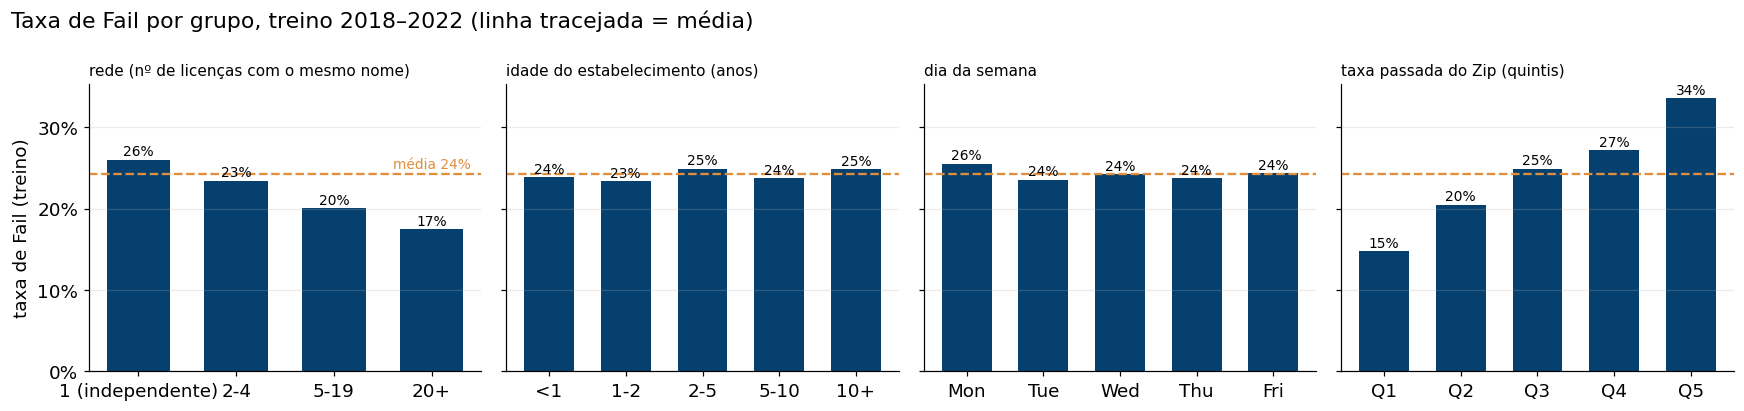

sábado: 38 inspeções (fora do gráfico por ter n muito pequeno)


In [ ]:
fig_z, axs_z = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
taxa_geral_z = treino_z["fail"].mean()
grupos_z = {
    "rede (nº de licenças com o mesmo nome)": treino_z.groupby("rede")["fail"].mean().reindex(["1 (independente)", "2-4", "5-19", "20+"]),
    "idade do estabelecimento (anos)": treino_z.groupby(pd.cut(treino_z["idade_anos"], [-.01, 1, 2, 5, 10, 40],
                                                        labels=["<1", "1-2", "2-5", "5-10", "10+"]), observed=True)["fail"].mean(),
    "dia da semana": treino_z[treino_z["dia_semana"] != "Saturday"].groupby("dia_semana")["fail"].mean()
                     .reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]).rename(lambda s_z: s_z[:3]),
    "taxa passada do Zip (quintis)": treino_z.groupby(pd.qcut(treino_z["zip_taxa_acum"], 5, labels=["Q1", "Q2", "Q3", "Q4", "Q5"]),
                                               observed=True)["fail"].mean(),
}
for ax_z, (titulo, s_z) in zip(axs_z, grupos_z.items()):
    ax_z.bar(s_z.index.astype(str), s_z.values, color=AZUL, width=.65)
    ax_z.axhline(taxa_geral_z, color=LARANJA, ls="--", lw=1.5)
    for x_z, v_z in enumerate(s_z.values):
        ax_z.text(x_z, v_z + .005, f"{v_z:.0%}", ha="center", fontsize=9)
    ax_z.set_title(titulo, fontsize=10, loc="left"); ax_z.grid(axis="x", alpha=0)
    ax_z.yaxis.set_major_formatter(plt.FuncFormatter(lambda v_z, _: f"{v_z:.0%}"))
axs_z[0].set_ylabel("taxa de Fail (treino)")
axs_z[0].text(3.4, taxa_geral_z + .008, f"média {taxa_geral_z:.0%}", color=LARANJA, fontsize=9, ha="right")
plt.suptitle("Taxa de Fail por grupo, treino 2018–2022 (linha tracejada = média)", x=.01, ha="left")
plt.tight_layout(); plt.show()
print("sábado:", (treino_z["dia_semana"] == "Saturday").sum(), "inspeções (fora do gráfico por ter n muito pequeno)")

#### 4b. Resultado: ganho no modelo (treino → validação)

,candidata,auc,ganho,ic_baixo,ic_alto,decisão
0,idade_anos,0.6182,-0.0010,-0.0016,-0.0005,descartar
1,dia_semana,0.6182,-0.0009,-0.0022,0.0001,descartar
2,rede (4 faixas),0.6210,0.0018,-0.0004,0.0040,descartar
3,log_n_lic,0.6215,0.0023,0.0001,0.0043,MANTER
4,zip (one-hot),0.6028,-0.0163,-0.0237,-0.0100,descartar
5,zip_taxa_acum,0.6246,0.0055,0.0005,0.0108,MANTER
6,regiao (one-hot),0.6097,-0.0095,-0.0155,-0.0037,descartar
7,regiao_taxa_acum,0.6201,0.0009,-0.0030,0.0044,descartar
8,tipo_estab_det (no lugar de tipo_estab),0.6192,0.0000,-0.0007,0.0006,descartar


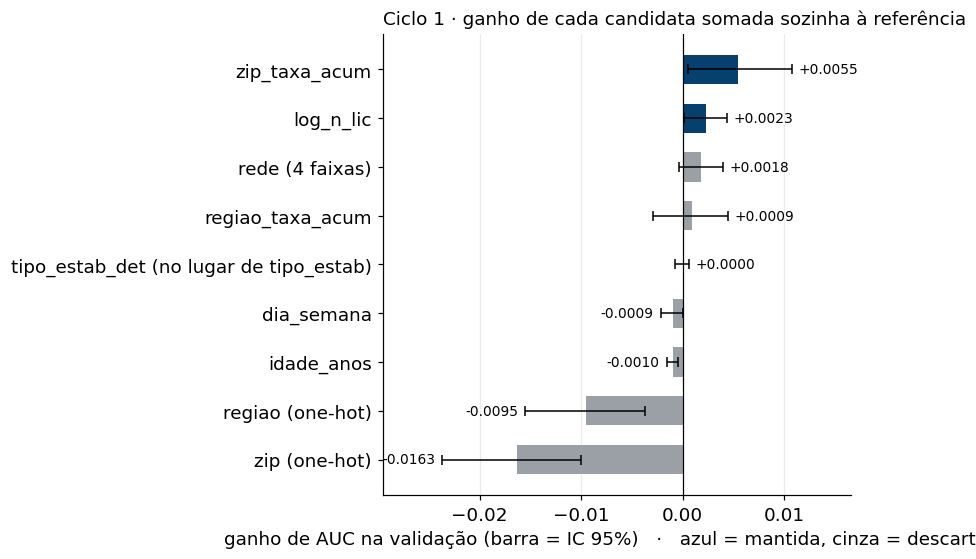

In [ ]:
ciclo1 = pd.DataFrame([
    avaliar_local("idade_anos", num=["idade_anos"]),
    avaliar_local("dia_semana", cat=["dia_semana"]),
    avaliar_local("rede (4 faixas)", cat=["rede"]),
    avaliar_local("log_n_lic", num=["log_n_lic"]),
    avaliar_local("zip (one-hot)", cat=["zip"]),
    avaliar_local("zip_taxa_acum", num=["zip_taxa_acum"]),
    avaliar_local("regiao (one-hot)", cat=["regiao"]),
    avaliar_local("regiao_taxa_acum", num=["regiao_taxa_acum"]),
    avaliar_local("tipo_estab_det (no lugar de tipo_estab)", troca_cat=["tipo_estab_det"]),
])
display(ciclo1.round(4))
grafico_ganho(ciclo1, "Ciclo 1 · ganho de cada candidata somada sozinha à referência")

#### 5. Conclusão do Ciclo 1

| candidata | associação (treino) | ganho na validação [IC 95%] | decisão |
|---|---|---|---|
| `zip_taxa_acum` | ρ = 0,152; Q1 15% → Q5 34% de Fail | **+0,0055** [+0,0005; +0,0108] | **manter** |
| `log_n_lic` | ρ = −0,058; independente 26% → rede 20+ 17% | **+0,0023** [+0,0001; +0,0043] | **manter** (no limite) |
| `rede` (4 faixas) | V = 0,059 | +0,0018 [−0,0004; +0,0040] | descartar: IC inclui zero, e `log_n_lic` carrega a mesma informação |
| `regiao_taxa_acum` | ρ = 0,130 | +0,0009 [−0,0030; +0,0044] | descartar: pior que o Zip |
| `tipo_estab_det` | V sobe de 0,066 para 0,073 | +0,0001 | descartar: os tipos novos têm poucas inspeções |
| `dia_semana` | V = 0,017; só a segunda se destaca (26%) | −0,0009 | descartar |
| `idade_anos` | ρ = 0,006 (p = 0,29); 23–25% em todas as faixas | −0,0010 | descartar: **H1 refutada** |
| `regiao` (one-hot) | V = 0,140 | −0,0095 | descartar |
| `zip` (one-hot) | V = 0,168, a maior associação | **−0,0163** | descartar |

📌 **O Zip foi descartado na seção 7 pela forma, não por falta de sinal.** Ele tem a maior associação
com o Fail (V = 0,168), mas como one-hot **piora** a validação em 0,016: as 79 colunas fixam a taxa de
cada Zip no período 2018–2022. A mesma informação resumida em **uma** coluna (a taxa de Fail passada do Zip)
melhora a AUC. Isso corrige a conclusão da seção 7 ("localização não se sustenta"): ela vale para o
one-hot, não para a localização em si.

📌 **Redes falham menos.** A taxa cai de 26% (independentes) para 17% (20 ou mais licenças com o mesmo
nome). O ganho no modelo é pequeno e fica no limite do critério.

📌 **Hipóteses refutadas:** idade do estabelecimento, dia da semana e um tipo de estabelecimento mais
detalhado não acrescentam nada.

**Próximo ciclo:** se a taxa acumulada desde 2018 já ajuda, uma taxa **recente** (janela móvel) deveria
ajudar mais, caso o risco de cada região mude com o tempo.

---
### Ciclo 2 · A forma da variável de região

#### 1. Hipótese
O Zip carrega sinal, mas o **one-hot congela a taxa de cada Zip no período de treino**. Se a taxa de
cada região muda com o tempo, uma taxa calculada sobre uma **janela móvel recente** (últimos N dias,
só passado) deveria capturar melhor esse sinal que a taxa acumulada desde 2018.

#### 2. Critério
O mesmo do ciclo 1. Por causa do tamanho do ganho, também foram exigidas **três verificações de vazamento**
antes de aceitar o resultado:
1. **conferência manual** do valor da feature em uma linha qualquer;
2. **defasagem**: o ganho tem de se manter quando os últimos 7 ou 30 dias não podem ser usados
   (simula o atraso entre a inspeção e a publicação dos dados);
3. **taxa relativa**: o ganho tem de se manter quando se desconta a taxa da cidade inteira na mesma janela
   (descarta a hipótese de que a feature só capta a tendência geral no tempo).

In [ ]:
PRIOR_Z = dz.loc[tr_z, "fail"].mean()
agg_zip = dz.groupby(["zip", "data"])["fail"].agg(["sum", "count"]).reset_index()

def taxa_janela(dias, defasagem=0, m=50, agg=agg_zip, col="zip"):
    """Taxa de Fail do grupo nos `dias` anteriores, ignorando os últimos `defasagem` dias e o próprio dia."""
    partes = []
    for z_z, gz_z in agg.groupby(col):
        diario = gz_z.set_index("data")[["sum", "count"]].sort_index().asfreq("D", fill_value=0)
        s_z = diario["sum"].shift(defasagem + 1).rolling(dias, min_periods=1).sum().fillna(0)
        c_z = diario["count"].shift(defasagem + 1).rolling(dias, min_periods=1).sum().fillna(0)
        partes.append(pd.DataFrame({col: z_z, "data": diario.index, "t": ((s_z + m * PRIOR_Z) / (c_z + m)).values}))
    partes = pd.concat(partes)
    return dz[[col, "data"]].merge(partes, on=[col, "data"], how="left")["t"].to_numpy()

for dias in [30, 90, 180, 365]:
    dz[f"zip_taxa_{dias}d"] = taxa_janela(dias)
for gap in [7, 30]:
    dz[f"zip_taxa_90d_def{gap}"] = taxa_janela(90, defasagem=gap)

# verificação 1: conferência manual de uma linha da validação
linha_z = dz[va_z].sample(1, random_state=1).iloc[0]
viz_z = dz[(dz["zip"] == linha_z["zip"]) & (dz["data"] < linha_z["data"]) & (dz["data"] >= linha_z["data"] - pd.Timedelta(days=90))]
manual_z = (viz_z["fail"].sum() + 50 * PRIOR_Z) / (len(viz_z) + 50)
print(f"Zip {linha_z['zip']} em {linha_z['data'].date()}: manual = {manual_z:.4f} | feature = {linha_z['zip_taxa_90d']:.4f}")
assert abs(manual_z - linha_z["zip_taxa_90d"]) < 1e-9

# verificação 3: taxa relativa (zip ÷ cidade inteira na mesma janela de 90 dias)
dz["_todos"] = "CIDADE"
agg_cid = dz.groupby(["_todos", "data"])["fail"].agg(["sum", "count"]).reset_index()
dz["cidade_taxa_90d"] = taxa_janela(90, agg=agg_cid, col="_todos", m=0)
dz["zip_rel_90d"] = dz["zip_taxa_90d"] / dz["cidade_taxa_90d"]

Zip 60623 em 2023-12-04: manual = 0.3495 | feature = 0.3495


,candidata,auc,ganho,ic_baixo,ic_alto,decisão
0,zip (one-hot),0.6028,-0.0163,-0.0237,-0.0100,descartar
1,zip_taxa_acum (desde 2018),0.6246,0.0055,0.0005,0.0108,MANTER
2,zip_taxa_365d,0.6517,0.0325,0.0246,0.0399,MANTER
3,zip_taxa_180d,0.6718,0.0527,0.0442,0.0620,MANTER
4,zip_taxa_90d,0.6860,0.0669,0.0580,0.0760,MANTER
5,zip_taxa_30d,0.6830,0.0639,0.0556,0.0739,MANTER
6,"zip_taxa_90d, defasagem 7d",0.6784,0.0593,0.0506,0.0685,MANTER
7,"zip_taxa_90d, defasagem 30d",0.6612,0.0421,0.0337,0.0496,MANTER
8,zip_rel_90d (÷ cidade),0.6736,0.0545,0.0459,0.0631,MANTER


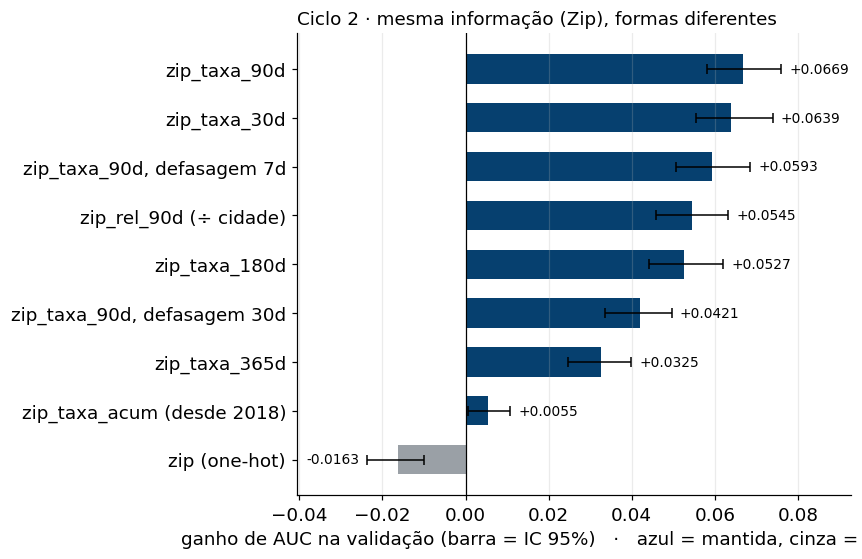

In [ ]:
ciclo2 = pd.DataFrame([
    avaliar_local("zip (one-hot)", cat=["zip"]),
    avaliar_local("zip_taxa_acum (desde 2018)", num=["zip_taxa_acum"]),
    avaliar_local("zip_taxa_365d", num=["zip_taxa_365d"]),
    avaliar_local("zip_taxa_180d", num=["zip_taxa_180d"]),
    avaliar_local("zip_taxa_90d", num=["zip_taxa_90d"]),
    avaliar_local("zip_taxa_30d", num=["zip_taxa_30d"]),
    avaliar_local("zip_taxa_90d, defasagem 7d", num=["zip_taxa_90d_def7"]),
    avaliar_local("zip_taxa_90d, defasagem 30d", num=["zip_taxa_90d_def30"]),
    avaliar_local("zip_rel_90d (÷ cidade)", num=["zip_rel_90d"]),
])
display(ciclo2.round(4))
grafico_ganho(ciclo2, "Ciclo 2 · mesma informação (Zip), formas diferentes")

In [ ]:
# o sinal se mantém nos dois anos da validação?
p90 = prever_local(REF_NUM + ["zip_taxa_90d_def7"], REF_CAT)
anos_z = dz.loc[va_z, "data"].dt.year.to_numpy()
print(pd.DataFrame({ano: {"referência": roc_auc_score(yv_z[anos_z == ano], p_ref[anos_z == ano]),
                          "+ zip_taxa_90d (def. 7d)": roc_auc_score(yv_z[anos_z == ano], p90[anos_z == ano])}
                    for ano in [2023, 2024]}).round(4))

# redundância com o histórico do próprio estabelecimento (treino)
print(dz.loc[tr_z, ["zip_taxa_90d_def7", "zip_taxa_acum", "taxa_fail_hist", "viol_ultima_rotina", "log_n_lic"]]
      .corr("spearman").round(2))

                            2023    2024
referência                0.6046  0.6317
+ zip_taxa_90d (def. 7d)  0.6597  0.6907
                    zip_taxa_90d_def7  zip_taxa_acum  taxa_fail_hist  \
zip_taxa_90d_def7                1.00           0.56            0.06   
zip_taxa_acum                    0.56           1.00            0.15   
taxa_fail_hist                   0.06           0.15            1.00   
viol_ultima_rotina               0.07           0.16            0.28   
log_n_lic                       -0.08          -0.12           -0.08   

                    viol_ultima_rotina  log_n_lic  
zip_taxa_90d_def7                 0.07      -0.08  
zip_taxa_acum                     0.16      -0.12  
taxa_fail_hist                    0.28      -0.08  
viol_ultima_rotina                1.00      -0.07  
log_n_lic                        -0.07       1.00  


#### 3. Conclusão do Ciclo 2

📌 **A janela recente multiplica o ganho.** A taxa dos últimos 90 dias rende **+0,067**, contra
+0,0055 da taxa acumulada. O ganho é máximo em 30–90 dias e cai com janelas maiores (180d: +0,053;
365d: +0,033). O sinal é **recente**: o que aconteceu no Zip nos últimos meses vale mais que o histórico longo.

📌 **As três verificações de vazamento passaram:**
1. o valor conferido à mão é igual ao da feature (o próprio dia não entra na conta);
2. com **7 dias** de defasagem o ganho continua em +0,059, e com **30 dias** em +0,042, então o ganho
   não vem de inspeções do mesmo dia ou dos dias imediatamente anteriores;
3. dividindo pela taxa da cidade inteira na mesma janela, o ganho continua em +0,055, então a feature
   não está captando só a tendência geral no tempo.

Além disso, o ganho aparece nos **dois** anos da validação (2023: 0,605 → 0,660; 2024: 0,632 → 0,691), e a
correlação com o histórico do próprio estabelecimento é baixa (ρ = 0,06 com `taxa_fail_hist`): é
**informação nova**, não uma recombinação.

**Decisão:** manter **`zip_taxa_90d_def7`** (90 dias, defasagem de 7 dias). Ela rende um pouco menos que a
versão sem defasagem (+0,059 contra +0,067), mas é a forma realista, porque o resultado de uma inspeção não
fica disponível no mesmo instante.

⚠️ **Por que funciona? Hipótese ainda não verificada.** O dataset não tem a coluna do fiscal responsável.
Uma explicação possível é que cada área seja inspecionada por uma mesma equipe durante um período, e que o
rigor dessa equipe altere a taxa de Fail da região. Outra é a existência de problemas locais temporários.
Se for a primeira, o modelo estaria prevendo em parte **quem** inspeciona, não só **como** está o
estabelecimento. Isso precisa ser discutido no relatório.

⚠️ **Cuidado com otimismo:** o tamanho da janela foi escolhido olhando a validação (9 variantes testadas).
A confirmação honesta é o **teste** (2025 em diante), reservado para a comparação final de modelos.

**Próximo ciclo:** juntar `zip_taxa_90d_def7` e `log_n_lic` à referência e verificar se cada uma ainda
contribui no conjunto.

---
### Ciclo 3 · Conjunto proposto e ablação

#### 1. Hipótese
`zip_taxa_90d_def7` (taxa de Fail do Zip nos 90 dias anteriores, com 7 dias de defasagem) e `log_n_lic`
trazem informações diferentes (correlação baixa entre si) e, juntas, somam ganho à referência.

#### 2. Critério
Cada coluna do conjunto final precisa derrubar a AUC em mais que `LIMIAR` quando é removida (mesma regra
da seção 7). Também é medido o efeito prático: a % dos Fails encontrados ao visitar primeiro os 20% de
maior risco previsto.

In [ ]:
NOVO_NUM = REF_NUM + ["zip_taxa_90d_def7", "log_n_lic"]
p_novo = prever_local(NOVO_NUM, REF_CAT)
auc_novo = roc_auc_score(yv_z, p_novo)
deltas_z = [roc_auc_score(yv_z[i], p_novo[i]) - roc_auc_score(yv_z[i], p_ref[i]) for i in BOOT_Z]
print(f"referência {AUC_REF:.4f} -> conjunto novo {auc_novo:.4f} (ganho {auc_novo - AUC_REF:+.4f}, "
      f"IC 95% [{np.percentile(deltas_z, 2.5):+.4f}, {np.percentile(deltas_z, 97.5):+.4f}])")

ablacao_z = []
for f_z in NOVO_NUM + REF_CAT:
    p_z = prever_local([c_z for c_z in NOVO_NUM if c_z != f_z], [c_z for c_z in REF_CAT if c_z != f_z])
    ablacao_z.append({"coluna": f_z, "Δ ao remover": roc_auc_score(yv_z, p_z) - auc_novo})
ablacao_z = pd.DataFrame(ablacao_z).sort_values("Δ ao remover")
ablacao_z["decisão"] = np.where(ablacao_z["Δ ao remover"] < -LIMIAR_Z, "manter", "descartar")
display(ablacao_z.round(4))

def pct_fails_top(p_z, q=.20):
    ordem_z = np.argsort(-p_z); k_z = int(q * len(p_z))
    return yv_z[ordem_z[:k_z]].sum() / yv_z.sum()

for q in [.10, .20, .30]:
    print(f"visitando os {q:.0%} mais arriscados: referência {pct_fails_top(p_ref, q):.1%} | novo {pct_fails_top(p_novo, q):.1%} dos Fails")

referência 0.6191 -> conjunto novo 0.6796 (ganho +0.0605, IC 95% [+0.0517, +0.0695])


,coluna,Δ ao remover,decisão
2,zip_taxa_90d_def7,-0.0581,manter
1,viol_ultima_rotina,-0.0148,manter
0,taxa_fail_hist,-0.0062,manter
4,tipo_estab,-0.0020,manter
3,log_n_lic,-0.0012,manter


visitando os 10% mais arriscados: referência 15.4% | novo 19.5% dos Fails
visitando os 20% mais arriscados: referência 28.9% | novo 34.8% dos Fails
visitando os 30% mais arriscados: referência 41.4% | novo 47.7% dos Fails


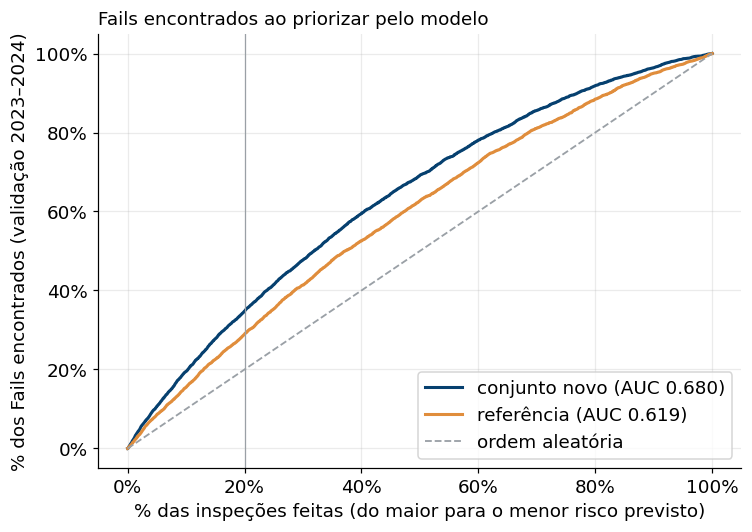

In [ ]:
def curva_ganho_z(p_z):
    o = np.argsort(-p_z)
    return np.arange(1, len(p_z) + 1) / len(p_z), np.cumsum(yv_z[o]) / yv_z.sum()
fig_z, ax_z = plt.subplots(figsize=(7, 5))
x_z, y_z = curva_ganho_z(p_novo); ax_z.plot(x_z, y_z, color=AZUL, lw=2, label=f"conjunto novo (AUC {auc_novo:.3f})")
x_z, y_z = curva_ganho_z(p_ref); ax_z.plot(x_z, y_z, color=LARANJA, lw=2, label=f"referência (AUC {AUC_REF:.3f})")
ax_z.plot([0, 1], [0, 1], color=CINZA, ls="--", lw=1.2, label="ordem aleatória")
ax_z.axvline(.2, color=CINZA, lw=.8)
ax_z.xaxis.set_major_formatter(plt.FuncFormatter(lambda v_z, _: f"{v_z:.0%}"))
ax_z.yaxis.set_major_formatter(plt.FuncFormatter(lambda v_z, _: f"{v_z:.0%}"))
ax_z.set_xlabel("% das inspeções feitas (do maior para o menor risco previsto)")
ax_z.set_ylabel("% dos Fails encontrados (validação 2023–2024)")
ax_z.set_title("Fails encontrados ao priorizar pelo modelo", loc="left")
ax_z.legend(loc="lower right"); plt.tight_layout(); plt.show()

#### 3. Conclusão do Ciclo 3

📌 **AUC de validação: 0,619 → 0,680** (+0,061, IC 95% [+0,052; +0,070]).

📌 **Ablação: todas as 5 colunas passam do `LIMIAR`.** `zip_taxa_90d_def7` passa a ser a coluna mais
importante (−0,058 ao remover), à frente de `viol_ultima_rotina` (−0,015). `log_n_lic` fica logo acima
do limite (−0,0012).

📌 **Efeito prático:** visitando primeiro os 20% de maior risco, a fiscalização encontra **34,8%** dos
Fails, contra 28,9% da referência (10%: 15,4% → 19,5%; 30%: 41,4% → 47,7%).

**Decisão:** levar para a comparação de modelos o conjunto `taxa_fail_hist`, `viol_ultima_rotina`, `tipo_estab`,
**`zip_taxa_90d_def7`** e **`log_n_lic`**.

---
### Conclusão das novas correlações

**Pergunta:** além do histórico do estabelecimento, o que mais anda junto com o Fail?

**Resposta:** a **taxa de Fail recente da região** (Zip, últimos 90 dias) e, em menor grau, o fato de o
estabelecimento ser parte de uma **rede**. Idade, dia da semana e um tipo de estabelecimento mais
detalhado não ajudam.

| ciclo | pergunta | resultado | decisão |
|---|---|---|---|
| 1 | quais atributos do local e do estabelecimento se associam ao Fail? | Zip tem a maior associação (V = 0,168), mas o one-hot piora o modelo; a taxa passada do Zip melhora (+0,0055); redes falham menos (+0,0023) | manter `zip_taxa_acum` e `log_n_lic`; descartar 7 candidatas |
| 2 | a forma da variável de região importa? | janela de 90 dias: +0,067; passou em 3 verificações de vazamento e nos 2 anos da validação | trocar por `zip_taxa_90d_def7` (+0,059, versão realista) |
| 3 | o conjunto proposto se sustenta? | AUC 0,619 → 0,680; top 20% encontra 34,8% dos Fails (antes 28,9%) | levar as 5 colunas para a comparação de modelos |

**Correção de uma conclusão anterior.** A seção 7 concluiu que a localização "não se
sustenta no futuro". Isso vale para o Zip em one-hot. Na forma de taxa recente, ela é a feature que
mais acrescenta ao modelo.

**Para a comparação de modelos**
- Incluir `zip_taxa_90d_def7` e `log_n_lic` na comparação de modelos. O código das duas está nas células
  do Ciclo 1 (`log_n_lic`) e do Ciclo 2 (`taxa_janela`) desta seção.
- Conferir os números com a função de avaliação comum do grupo e usar o teste **uma única vez**.

**Limitações**
- A janela de 90 dias foi escolhida pela validação; o ganho real pode ser um pouco menor no teste.
- Não sabemos a defasagem real entre a inspeção e a publicação no portal; 7 dias é uma suposição.
- **Risco de ciclo de realimentação:** se a prefeitura passar a escolher quem inspecionar pelo modelo, a
  taxa recente de cada Zip passa a depender dessas escolhas.
- O mecanismo por trás do ganho (efeito do fiscal ou da equipe, ou problemas locais) não foi verificado.

**Próximo ciclo (hipóteses que surgiram)**
1. Confirmar no portal de dados de Chicago qual é a defasagem real de publicação e recalcular a feature.
2. Trocar o Zip por uma vizinhança espacial (raio em km, a partir de latitude/longitude) e comparar.
3. Procurar evidência do efeito do fiscal: por exemplo, se o ganho se concentra em períodos com muitas
   inspeções no mesmo Zip em poucos dias.

## 9 · Novas correlações com Fail: violações e tendência

**Pergunta:** além do histórico do estabelecimento (`taxa_fail_hist`, `viol_ultima_rotina`),
o *conteúdo* das violações anteriores e a *tendência* do estabelecimento ajudam a prever o
próximo Fail?

**Hipóteses**

| # | hipótese | onde foi testada |
|---|---|---|
| H1 | algumas violações específicas da rotina anterior anunciam um Fail melhor que outras | esta seção |
| H2 | a taxa de Fail da vizinhança (Zip) no período anterior ajuda | seção anterior (Ciclo 2: `zip_taxa_90d_def7`, mantida) |
| H3 | a tendência do estabelecimento (melhorando ou piorando) acrescenta sinal | esta seção |

**Regras para evitar vazamento** (as mesmas da seção anterior)

- Mesma base e mesmo split fixo: `dz`, treino até 31/12/2022, validação 2023–2024.
- O ranking das violações é calculado **só no treino**.
- Toda feature usa só rotinas **anteriores** do mesmo estabelecimento (`shift` por licença).

**Critério (definido antes dos resultados):** a candidata é mantida se o ganho de AUC na
validação for maior que `LIMIAR = 0,001` **e** o IC 95% (bootstrap) do ganho ficar acima de
zero. Como são várias candidatas, ganhos abaixo de 0,002 são tratados com desconfiança (a20).

In [ ]:
import re
from sklearn.preprocessing import MultiLabelBinarizer

# rotinas válidas, ordenadas por licença e data
r2 = df_z[rotina_z & df_z["lic"].notna()].sort_values(["lic", "data", "Inspection ID"]).copy()

def codigos(txt):
    """Extrai o número de cada violação: 'N. NOME - Comments: ... | N. NOME ...'"""
    if pd.isna(txt):
        return []
    return sorted({int(m.group(1)) for p in re.split(r"\s\|\s", txt)
                   if (m := re.match(r"\s*(\d{1,2})\.\s", p))})

lista_cods = r2["Violations"].map(codigos)
cods = sorted({c for L in lista_cods for c in L})
M = pd.DataFrame(MultiLabelBinarizer(classes=cods).fit_transform(lista_cods),
                 index=r2.index, columns=[f"ant_v{c:02d}" for c in cods])

# violações da rotina ANTERIOR do mesmo estabelecimento (NaN na 1ª rotina)
P = M.groupby(r2["lic"]).shift(1).reindex(dz.index)
dz[P.columns] = P

# ranking no TREINO: taxa de Fail com a violação na rotina anterior − sem ela
tr_r = dz[tr_z & P.notna().all(axis=1)]
rk = pd.DataFrame({"n": tr_r[P.columns].sum(),
                   "com": [tr_r.loc[tr_r[c] == 1, "fail"].mean() for c in P.columns],
                   "sem": [tr_r.loc[tr_r[c] == 0, "fail"].mean() for c in P.columns]})
rk["dif"] = rk["com"] - rk["sem"]
rk = rk[rk["n"] >= 300].sort_values("dif", ascending=False)   # suporte mínimo: 300 casos

# nome de cada violação (primeiro texto encontrado)
nomes = {}
for txt in r2["Violations"].dropna().head(30000):
    for p in re.split(r"\s\|\s", txt):
        m = re.match(r"\s*(\d{1,2})\.\s+(.+?)(?:\s-\sComments:|$)", p, flags=re.S)
        if m:
            nomes.setdefault(int(m.group(1)), m.group(2).strip())
rk["nome"] = [nomes.get(int(i[-2:]), "")[:50] for i in rk.index]
display(rk.head(10).round(3))

# features sem usar o alvo: violações críticas (1-14) e sérias (15-29) da rotina anterior
# (conferir esta classificação no dicionário oficial do Chicago Data Portal)
dz["n_crit_ant"]  = dz[[f"ant_v{c:02d}" for c in range(1, 15) if f"ant_v{c:02d}" in P]].sum(axis=1, min_count=1)
dz["n_seria_ant"] = dz[[f"ant_v{c:02d}" for c in range(15, 30) if f"ant_v{c:02d}" in P]].sum(axis=1, min_count=1)
top1 = rk.index[0]          # violação mais associada (ant_v57)

,n,com,sem,dif,nome
ant_v57,2351.0,0.352,0.228,0.124,ALL FOOD EMPLOYEES HAVE FOOD HANDLER TRAINING
ant_v08,423.0,0.338,0.237,0.102,SANITIZING RINSE FOR EQUIPMENT AND UTENSILS: ...
ant_v23,2942.0,0.327,0.228,0.099,PROPER DATE MARKING AND DISPOSITION
ant_v10,4347.0,0.320,0.224,0.097,ADEQUATE HANDWASHING SINKS PROPERLY SUPPLIED A...
ant_v25,2215.0,0.325,0.231,0.094,CONSUMER ADVISORY PROVIDED FOR RAW/UNDERCOOKED...
ant_v12,366.0,0.331,0.237,0.094,HAND WASHING FACILITIES: WITH SOAP AND SANITAR...
ant_v58,4308.0,0.313,0.225,0.088,ALLERGEN TRAINING AS REQUIRED
ant_v18,1434.0,0.321,0.234,0.088,NO EVIDENCE OF RODENT OR INSECT OUTER OPENINGS...
ant_v48,1422.0,0.321,0.234,0.087,"WAREWASHING FACILITIES: INSTALLED, MAINTAINED ..."
ant_v54,810.0,0.319,0.236,0.083,GARBAGE & REFUSE PROPERLY DISPOSED; FACILITIES...


### Ciclo 1 · Conteúdo das violações da rotina anterior

**1. Hipótese.** Algumas violações anunciam um Fail melhor do que outras. O número de
violações (`viol_ultima_rotina`) não distingue uma da outra.

**2. Critério.** O da introdução. No ranking, suporte mínimo de 300 casos.

**3. Mudança.** Extrair o número de cada violação do texto de `Violations` e marcar, para
cada inspeção, quais violações aconteceram na rotina **anterior** do mesmo estabelecimento.
Criar também `n_crit_ant` e `n_seria_ant` (violações críticas, 1–14, e sérias, 15–29, da
rotina anterior), que não usam o alvo.

**4. Resultado do ranking (treino).** Entre as violações com pelo menos 300 casos:

| violação na rotina anterior | casos | Fail com | Fail sem | diferença |
|---|---|---|---|---|
| 57 (treinamento dos manipuladores de alimento) | 2.351 | 35,2% | 22,8% | +12,4 p.p. |
| 10 (pias de lavagem de mãos) | 4.347 | 32,0% | 22,4% | +9,7 p.p. |
| 58 (treinamento sobre alergênicos) | 4.308 | 31,3% | 22,5% | +8,8 p.p. |

Duas das mais frequentes (57 e 58) são violações de **treinamento e certificação**, não de
temperatura ou pragas. Isso pode refletir o período em que esses códigos passaram a ser
cobrados, e não um risco sanitário em si (hipótese a verificar).

,candidata,auc,ganho,ic_baixo,ic_alto,decisão
0,ant_v57,0.6183,-0.0008,-0.0018,0.0002,descartar
1,n_crit_ant,0.6191,-0.0000,-0.0003,0.0002,descartar
2,n_seria_ant,0.6190,-0.0001,-0.0002,0.0000,descartar
3,media_viol_3,0.6286,0.0095,0.0059,0.0127,MANTER
4,tend_viol,0.6281,0.0089,0.0055,0.0122,MANTER


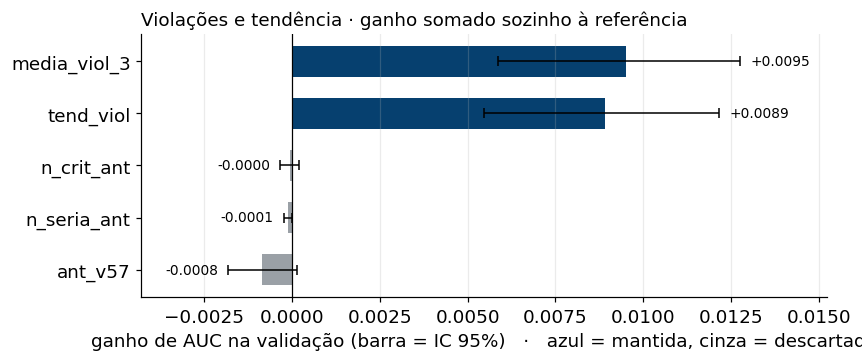

In [ ]:
gr = r2.groupby("lic")
for k in (1, 2, 3):
    r2[f"v{k}"] = gr["n_viol"].shift(k)        # v1 = viol_ultima_rotina

dz["media_viol_3"] = r2[["v1", "v2", "v3"]].mean(axis=1).reindex(dz.index)
dz["tend_viol"]    = (r2["v1"] - r2[["v2", "v3"]].mean(axis=1)).reindex(dz.index)   # > 0 = piorando

# ganho de AUC de cada candidata somada SOZINHA à referência
cand = [top1, "n_crit_ant", "n_seria_ant", "media_viol_3", "tend_viol"]
ciclo_p2 = pd.DataFrame([avaliar_local(c, num=[c]) for c in cand])
display(ciclo_p2.round(4))
grafico_ganho(ciclo_p2, "Violações e tendência · ganho somado sozinho à referência")

**Resultado do ganho de AUC (validação 2023–2024, somada sozinha à referência).**
A referência tem AUC de validação de 0,619.

| candidata | forma (a09) | ganho de AUC | IC 95% | decisão |
|---|---|---|---|---|
| `ant_v57` (violação mais associada) | extração | −0,0008 | [−0,0018; +0,0002] | descartar |
| `n_crit_ant` | agregação | −0,0000 | [−0,0003; +0,0002] | descartar |
| `n_seria_ant` | agregação | −0,0001 | [−0,0002; +0,0000] | descartar |
| `media_viol_3` | agregação | **+0,0095** | [+0,0059; +0,0127] | **manter** |
| `tend_viol` | diferença | **+0,0089** | [+0,0055; +0,0122] | **manter** |

**5. Conclusão.**

 **Associação não é ganho.** A violação 57 tem a maior diferença do
ranking (+12,4 p.p.) e ganho zero no modelo: é rara (2.351 casos) e `viol_ultima_rotina`
já resume boa parte do sinal. `n_crit_ant` e `n_seria_ant` só recombinam o que o modelo já
tinha: descartar.

**A tendência acrescenta informação nova.** `viol_ultima_rotina` olha só a última
rotina. `media_viol_3` e `tend_viol` incluem também as duas rotinas anteriores, e é isso que
rende cerca de +0,009 de AUC, acima do limiar (0,001) e do ruído esperado (0,002, a20). Como
as duas usam os mesmos ingredientes (violações das três últimas rotinas), são provavelmente
redundantes entre si.

**6. Próximo ciclo.** Verificar se o ganho se mantém quando as duas são somadas ao conjunto
proposto na seção anterior, que já tem `zip_taxa_90d_def7` e `log_n_lic`.

,candidata,auc,ganho,ic_baixo,ic_alto,decisão
0,media_viol_3,0.6850,0.0053,0.0035,0.0074,MANTER
1,tend_viol,0.6845,0.0049,0.0031,0.0068,MANTER


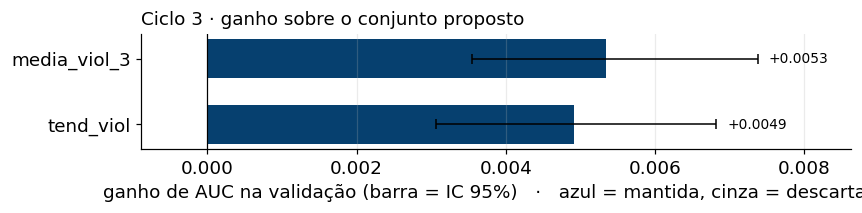

In [ ]:
# as aprovadas, por cima do conjunto proposto (NOVO_NUM, p_novo)
auc_novo = roc_auc_score(yv_z, p_novo)
linhas = []
for f in ["media_viol_3", "tend_viol"]:
    p_f = prever_local(NOVO_NUM + [f], REF_CAT)
    d_f = [roc_auc_score(yv_z[i], p_f[i]) - roc_auc_score(yv_z[i], p_novo[i]) for i in BOOT_Z]
    lo, hi = np.percentile(d_f, [2.5, 97.5])
    g = roc_auc_score(yv_z, p_f) - auc_novo
    linhas.append({"candidata": f, "auc": roc_auc_score(yv_z, p_f), "ganho": g,
                   "ic_baixo": lo, "ic_alto": hi,
                   "decisão": "MANTER" if (g > LIMIAR_Z and lo > 0) else "descartar"})
ciclo_p2b = pd.DataFrame(linhas)
display(ciclo_p2b.round(4))
grafico_ganho(ciclo_p2b, "Ciclo 3 · ganho sobre o conjunto proposto")

### Ciclo 2 · As aprovadas, por cima do conjunto proposto


**1. Hipótese.** O que rende sozinho sobre a referência pode não render quando o conjunto
já tem `zip_taxa_90d_def7` e `log_n_lic`.

**2. Critério.** O mesmo.

**3. Mudança.** Somar ao conjunto proposto `media_viol_3` e `tend_viol`.

**4. Resultado.**

| candidata | AUC | ganho sobre o conjunto proposto | IC 95% | decisão |
|---|---|---|---|---|
| `media_viol_3` | 0,6850 | +0,0053 | [+0,0035; +0,0074] | manter |
| `tend_viol` | 0,6845 | +0,0049 | [+0,0031; +0,0068] | manter |

**O ganho cai quase pela metade** (de +0,0095 sobre a referência para +0,0053), porque
parte do sinal já estava em `zip_taxa_90d_def7`. Mesmo assim, o IC continua acima de zero e
o ganho passa do ruído esperado (0,002, a20): a informação das rotinas 2 e 3 é nova.

As duas candidatas usam os mesmos ingredientes e têm ganhos quase iguais, então são
redundantes entre si.

**5. Conclusão.** Manter **`media_viol_3`** (mais simples e com maior ganho) e descartar
`tend_viol` por redundância.


# Conclusão geral

**O problema.** A prefeitura de Chicago não consegue inspecionar todos os estabelecimentos ao mesmo tempo. A pergunta do projeto foi: dá para prever quais inspeções de rotina (Canvass) vão terminar em Fail, para inspecionar primeiro os estabelecimentos mais arriscados?

**Principais decisões de cada seção**

| seção | o que encontramos | decisão |
|---|---|---|
| 1 · Estrutura | cada linha é uma inspeção, e o mesmo estabelecimento aparece várias vezes | dividir treino e teste por data, nunca de forma aleatória |
| 2 · Qualidade | boa integridade; o vazio em `Violations` quase sempre significa "não se aplica" | normalizar textos, tratar licença 0 como ausente, remover só duplicatas comprovadas |
| 3 · Distribuições | 4 valores de `Results` não são resultado sanitário; Canvass é 51,6% das linhas | alvo binário (Fail contra Pass e Pass w/ Conditions) e recorte só em Canvass |
| 4 · Correlação | nenhuma variável sozinha explica o Fail (maior ρ ≈ 0,12); `n_violacoes` vaza o alvo (ρ = 0,38) | apostar no histórico do estabelecimento e não usar `Violations` da mesma inspeção |
| 5 · Preparação | base final com 132.088 inspeções e 22,6% de Fail | aplicar as decisões anteriores sem remover outliers legítimos |
| 6 · Engenharia de features | o ponto de partida tem AUC 0,554; `viol_ultima_rotina` sozinha rende +0,051 | reconstruir o vazamento de forma honesta, com as violações da rotina anterior |
| 7 · Seleção de features | 3 colunas entregam o mesmo que todas juntas (0,616 contra 0,615) | ficar com `taxa_fail_hist`, `viol_ultima_rotina` e `tipo_estab` |
| 8 · Resultado | AUC 0,623 em 26.418 inspeções que o modelo não viu (abr/2023 a set/2026) | usar o modelo para ordenar a fila de inspeções |

**Resultado final.** Priorizando os 20% de inspeções que o modelo considera mais arriscadas, encontramos 30% dos Fails, cerca de 1,5 vez o que uma ordem aleatória encontraria. A AUC no teste (0,623) ficou próxima da validação cruzada (0,616), então o modelo não piorou ao chegar no futuro. Trocar a regressão logística por um Random Forest com as mesmas features não melhorou o resultado (0,619 contra 0,623): o limite está na informação disponível, não no tipo de modelo.

**Limitações**

- A AUC é moderada. O modelo serve para priorizar a fila, não para afirmar quais estabelecimentos vão falhar.
- O resultado vale só para inspeções Canvass. Licenças, denúncias e reinspeções ficaram de fora.
- As features foram escolhidas na seção 7 com validação cruzada sobre o período inteiro, que inclui os anos do teste, então o resultado pode estar levemente otimista.
- Estabelecimentos na primeira rotina não têm histórico, e é justamente o histórico que sustenta o modelo.
- A taxa de Fail muda ao longo dos anos (de cerca de 19% para 27 a 28%), então o modelo precisaria ser retreinado periodicamente.
- O dado só registra quem foi inspecionado. Não sabemos o que aconteceria nos estabelecimentos que a prefeitura não visitou.

**Em uma frase.** O histórico do próprio estabelecimento é o melhor sinal de um Fail futuro, e o ganho mais importante do projeto veio de identificar um vazamento e reconstruí-lo usando só o que já se sabia antes da inspeção.

## Apêndice — análises não mantidas no conjunto final

Também foram exploradas transformações logarítmicas, a interação `risco_x_tipo`, a feature `gravidade_hist` e associações categóricas medidas pelo Cramér's V. Essas análises foram mantidas no apêndice porque não apresentaram ganho suficiente para justificar o aumento de complexidade do modelo final.

## 10 · Sazonalidade — o mês ajuda a prever Fail?

Investigamos se a taxa de Fail de um mês se repete no mesmo mês do ano seguinte e se esse padrão mudou durante a COVID-19. Comparamos os meses, testamos a associação entre mês e Fail e avaliamos novas features na validação temporal. O período de teste (2025 em diante) permanece reservado.

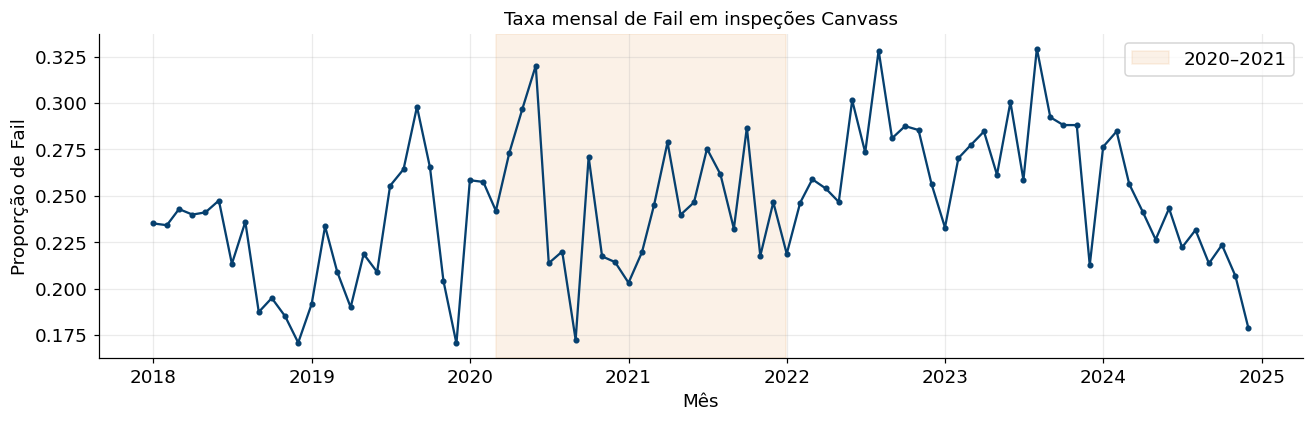

,n,taxa_fail
2024-01,680,0.276471
2024-02,583,0.284734
2024-03,663,0.256410
2024-04,886,0.241535
2024-05,839,0.226460
2024-06,518,0.243243
2024-07,711,0.222222
2024-08,652,0.231595
2024-09,796,0.213568
2024-10,917,0.223555


In [ ]:
# Somente treino e validação; o teste continua reservado
dev_saz = dz.loc[tr_z | va_z, ["data", "fail"]].copy()

periodos = pd.period_range(
    dev_saz["data"].min().to_period("M"),
    dev_saz["data"].max().to_period("M"),
    freq="M"
)

mensal_saz = (
    dev_saz
    .groupby(dev_saz["data"].dt.to_period("M"))["fail"]
    .agg(n="size", taxa_fail="mean")
    .reindex(periodos)
)

mensal_saz["n"] = mensal_saz["n"].fillna(0).astype(int)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(
    mensal_saz.index.to_timestamp(),
    mensal_saz["taxa_fail"],
    marker=".",
    color="#06406F"
)
ax.axvspan(
    pd.Timestamp("2020-03-01"),
    pd.Timestamp("2021-12-31"),
    color="#E08D3C",
    alpha=0.12,
    label="2020–2021"
)
ax.set_title("Taxa mensal de Fail em inspeções Canvass")
ax.set_ylabel("Proporção de Fail")
ax.set_xlabel("Mês")
ax.legend()
plt.tight_layout()
plt.show()

display(mensal_saz.tail(12))

,comparação,meses_comparáveis,correlação
0,2018 → 2019,12,-0.138
1,2019 → 2020,12,-0.394
2,2020 → 2021,12,0.106
3,2021 → 2022,12,0.431
4,2022 → 2023,12,0.787
5,2023 → 2024,12,0.109


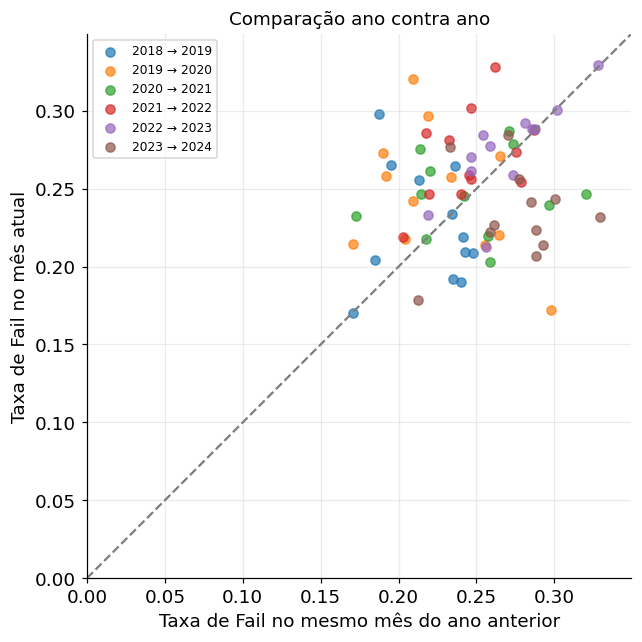

In [ ]:
# shift(12) funciona porque a tabela contém todos os meses,
# inclusive os que eventualmente não tiveram inspeções.
pares_saz = mensal_saz.copy()
pares_saz["taxa_ano_anterior"] = pares_saz["taxa_fail"].shift(12)
pares_saz["n_ano_anterior"] = pares_saz["n"].shift(12)
pares_saz["ano_atual"] = pares_saz.index.year

# Meses com poucas inspeções produzem taxas muito instáveis
pares_saz = pares_saz.loc[
    pares_saz["taxa_fail"].notna()
    & pares_saz["taxa_ano_anterior"].notna()
    & (pares_saz["n"] >= 30)
    & (pares_saz["n_ano_anterior"] >= 30)
].copy()

correlacoes_anuais = []
for ano, grupo in pares_saz.groupby("ano_atual"):
    correlacoes_anuais.append({
        "comparação": f"{ano-1} → {ano}",
        "meses_comparáveis": len(grupo),
        "correlação": grupo["taxa_ano_anterior"].corr(
            grupo["taxa_fail"]
        ) if len(grupo) >= 3 else np.nan
    })

display(pd.DataFrame(correlacoes_anuais).round(3))

fig, ax = plt.subplots(figsize=(6, 6))
for ano, grupo in pares_saz.groupby("ano_atual"):
    ax.scatter(
        grupo["taxa_ano_anterior"],
        grupo["taxa_fail"],
        label=f"{ano-1} → {ano}",
        alpha=0.7
    )

limite = max(
    pares_saz[["taxa_ano_anterior", "taxa_fail"]].max()
) + 0.02

ax.plot([0, limite], [0, limite], "--", color="gray")
ax.set_xlim(0, limite)
ax.set_ylim(0, limite)
ax.set_xlabel("Taxa de Fail no mesmo mês do ano anterior")
ax.set_ylabel("Taxa de Fail no mês atual")
ax.set_title("Comparação ano contra ano")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

,fase,inspeções,Cramér's V,p-valor
0,Antes (2018–2019),15128,0.0404,0.0002
1,Durante (2020–2021),12407,0.0404,0.0010
2,Depois (2022–2024),22516,0.0405,0.0000


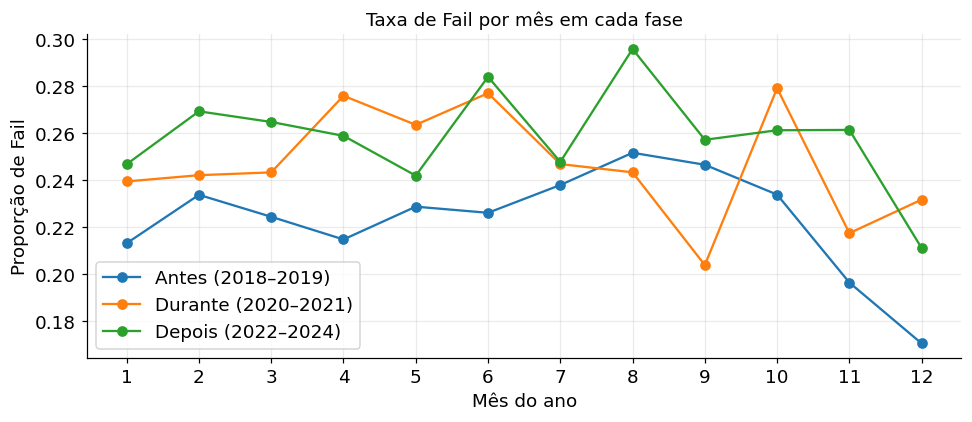

In [ ]:
dev_saz["mes"] = dev_saz["data"].dt.month
ano_saz = dev_saz["data"].dt.year

fases_saz = {
    "Antes (2018–2019)": dev_saz.loc[ano_saz.between(2018, 2019)],
    "Durante (2020–2021)": dev_saz.loc[ano_saz.between(2020, 2021)],
    "Depois (2022–2024)": dev_saz.loc[ano_saz.between(2022, 2024)]
}

resultados_quiquadrado = []

for fase, dados_fase in fases_saz.items():
    # cramers_v_local, já definida no notebook, executa
    # o teste qui-quadrado e calcula Cramér's V.
    v, p = cramers_v_local(
        dados_fase["mes"],
        dados_fase["fail"]
    )

    resultados_quiquadrado.append({
        "fase": fase,
        "inspeções": len(dados_fase),
        "Cramér's V": v,
        "p-valor": p
    })

display(pd.DataFrame(resultados_quiquadrado).round(4))

fig, ax = plt.subplots(figsize=(9, 4))

for fase, dados_fase in fases_saz.items():
    taxa_por_mes = dados_fase.groupby("mes")["fail"].mean()
    ax.plot(
        taxa_por_mes.index,
        taxa_por_mes.values,
        marker="o",
        label=fase
    )

ax.set_xticks(range(1, 13))
ax.set_xlabel("Mês do ano")
ax.set_ylabel("Proporção de Fail")
ax.set_title("Taxa de Fail por mês em cada fase")
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
dz["mes_saz"] = dz["data"].dt.month.astype(str).str.zfill(2)

mes_num = dz["data"].dt.month
dz["estacao_saz"] = np.select(
    [
        mes_num.isin([12, 1, 2]),
        mes_num.isin([3, 4, 5]),
        mes_num.isin([6, 7, 8])
    ],
    ["inverno", "primavera", "verao"],
    default="outono"
)

# Usa inspeções Canvass válidas anteriores, inclusive antes de 2018.
# Para cada inspeção, consulta a taxa do MESMO mês do ano anterior.
historico_cidade = df_z.loc[rotina_z, ["data", "_fail"]]

taxa_mensal_historica = historico_cidade.groupby(
    historico_cidade["data"].dt.to_period("M")
)["_fail"].mean()

dz["taxa_fail_mes_ano_anterior"] = (
    dz["data"].dt.to_period("M") - 12
).map(taxa_mensal_historica).astype(float)

display(
    dz.loc[tr_z | va_z, [
        "data", "mes_saz", "estacao_saz",
        "taxa_fail_mes_ano_anterior"
    ]].head()
)

,data,mes_saz,estacao_saz,taxa_fail_mes_ano_anterior
163485,2018-01-02,01,inverno,0.227273
163486,2018-01-02,01,inverno,0.227273
163489,2018-01-02,01,inverno,0.227273
163492,2018-01-02,01,inverno,0.227273
163495,2018-01-02,01,inverno,0.227273


In [ ]:
# Procuramos uma inspeção Canvass da mesma licença
# entre 335 e 395 dias antes da inspeção atual.
consulta_12m = dz.loc[
    dz["lic"].notna(),
    ["lic", "data"]
].copy()

consulta_12m["_indice"] = consulta_12m.index
consulta_12m = consulta_12m.rename(
    columns={"data": "data_atual"}
)
consulta_12m["alvo_12m"] = (
    consulta_12m["data_atual"] - pd.Timedelta(days=365)
)

historico_12m = (
    df_z.loc[
        rotina_z & df_z["lic"].notna(),
        ["lic", "data", "_fail", "Inspection ID"]
    ]
    .copy()
    .rename(columns={
        "data": "data_hist",
        "_fail": "fail_hist"
    })
)

pareados_12m = pd.merge_asof(
    consulta_12m.sort_values("alvo_12m"),
    historico_12m.sort_values(
        ["data_hist", "Inspection ID"]
    ),
    by="lic",
    left_on="alvo_12m",
    right_on="data_hist",
    direction="nearest",
    tolerance=pd.Timedelta(days=30)
)

dz["falhou_12m"] = np.nan
dz.loc[pareados_12m["_indice"], "falhou_12m"] = (
    pareados_12m["fail_hist"].to_numpy()
)

intervalo_12m = (
    pareados_12m["data_atual"]
    - pareados_12m["data_hist"]
).dt.days.dropna()

assert intervalo_12m.between(335, 395).all()

print(
    "Inspeções com rotina próxima de 12 meses antes:",
    f"{dz.loc[tr_z | va_z, 'falhou_12m'].notna().mean():.1%}"
)

Inspeções com rotina próxima de 12 meses antes: 19.4%


In [ ]:
# Procuramos uma inspeção Canvass da mesma licença
# entre 335 e 395 dias antes da inspeção atual.
consulta_12m = dz.loc[
    dz["lic"].notna(),
    ["lic", "data"]
].copy()

consulta_12m["_indice"] = consulta_12m.index
consulta_12m = consulta_12m.rename(
    columns={"data": "data_atual"}
)
consulta_12m["alvo_12m"] = (
    consulta_12m["data_atual"] - pd.Timedelta(days=365)
)

historico_12m = (
    df_z.loc[
        rotina_z & df_z["lic"].notna(),
        ["lic", "data", "_fail", "Inspection ID"]
    ]
    .copy()
    .rename(columns={
        "data": "data_hist",
        "_fail": "fail_hist"
    })
)

pareados_12m = pd.merge_asof(
    consulta_12m.sort_values("alvo_12m"),
    historico_12m.sort_values(
        ["data_hist", "Inspection ID"]
    ),
    by="lic",
    left_on="alvo_12m",
    right_on="data_hist",
    direction="nearest",
    tolerance=pd.Timedelta(days=30)
)

dz["falhou_12m"] = np.nan
dz.loc[pareados_12m["_indice"], "falhou_12m"] = (
    pareados_12m["fail_hist"].to_numpy()
)

intervalo_12m = (
    pareados_12m["data_atual"]
    - pareados_12m["data_hist"]
).dt.days.dropna()

assert intervalo_12m.between(335, 395).all()

print(
    "Inspeções com rotina próxima de 12 meses antes:",
    f"{dz.loc[tr_z | va_z, 'falhou_12m'].notna().mean():.1%}"
)

Inspeções com rotina próxima de 12 meses antes: 19.4%


In [ ]:
num_base = NOVO_NUM + ["media_viol_3"]
cat_base = REF_CAT.copy()

p_base = prever_local(num_base, cat_base)
auc_base = roc_auc_score(yv_z, p_base)

candidatas = [
    ("Mês", [], ["mes_saz"]),
    ("Estação", [], ["estacao_saz"]),
    ("Taxa do mesmo mês no ano anterior", ["taxa_fail_mes_ano_anterior"], []),
    ("Falhou cerca de 12 meses antes", ["falhou_12m"], []),
]

resultados = []
for nome, num_extra, cat_extra in candidatas:
    p = prever_local(num_base + num_extra, cat_base + cat_extra)
    auc = roc_auc_score(yv_z, p)
    resultados.append({
        "feature": nome,
        "AUC_validação": auc,
        "ganho_AUC": auc - auc_base
    })

print(f"AUC atual: {auc_base:.4f}")
display(pd.DataFrame(resultados).round(4))

AUC atual: 0.6850


,feature,AUC_validação,ganho_AUC
0,Mês,0.6859,0.0009
1,Estação,0.6853,0.0004
2,Taxa do mesmo mês no ano anterior,0.6850,0.0000
3,Falhou cerca de 12 meses antes,0.6853,0.0003


### Conclusão da sazonalidade

A taxa de Fail varia entre os meses, mas o padrão não se repete de forma consistente no ano seguinte: as correlações ano contra ano variaram de −0,394 a 0,787. Antes, durante e depois de 2020–2021, a associação entre mês e Fail foi muito fraca (Cramér’s V ≈ 0,04). Portanto, não encontramos uma sazonalidade forte ou estável, nem podemos atribuir as mudanças observadas à COVID.

As features sazonais também quase não melhoraram o modelo na validação. A maior melhora veio de **mês**, com AUC de 0,6850 para 0,6859 (Δ AUC = +0,0009). Estação, taxa do mesmo mês no ano anterior e Fail cerca de 12 meses antes tiveram ganhos ainda menores ou nulos. Além disso, esta última informação estava disponível para apenas 19,4% das inspeções analisadas.

**Decisão:** não incluir essas features no conjunto final por enquanto. Há um sinal mensal fraco, mas ele não trouxe ganho relevante de previsão.

---
## 11 · Comparação de modelos e teste final

**Pergunta:** com as features aprovadas pelos integrantes, qual modelo ordena melhor a fila de
inspeções, e quais features ficam?

**Protocolo** (o mesmo das seções de novas correlações, para os números serem comparáveis):

| item | definição |
|---|---|
| base | `dz`: inspeções Canvass com resultado sanitário, a partir de 2018 |
| split | treino ≤ 31/12/2022 · validação 2023–2024 · **teste 2025 → 23/09/2026, usado uma única vez no fim** |
| métricas | AUC de validação **e** % dos Fails encontrados visitando primeiro os 20% de maior risco (continuação da seção 8) |
| modelos | regressão logística (referência), Random Forest, `HistGradientBoostingClassifier` |
| ajuste | grade pequena de hiperparâmetros, escolhida **só na validação** |
| critério | mesmo `LIMIAR = 0,001` e IC 95% por bootstrap pareado (`BOOT_Z`) das seções anteriores |

Todo o pré-processamento (imputação, padronização, one-hot / ordinal) fica dentro do `Pipeline` e é
ajustado só no treino. O HGB recebe os NaN sem imputação, porque ele os trata nativamente: na 1ª rotina
de um estabelecimento não há histórico, e essa ausência também é informação.

#### Primeira entrega: `avaliar(features)`

`avaliar(features, modelo="logistica", params=None)` treina no treino e devolve a AUC de validação e a
% dos Fails no top 20%. Antes de qualquer outro número, a célula confere que a função **reproduz** os
números locais das seções anteriores (`AUC_REF` = 0,6191 e `auc_base` = 0,6850).

In [ ]:
# Usa o split de 2018 montado no "0 · Preparação" (dz, tr_z, va_z): treino até
# 31/12/2022, validação 2023–2024. O teste (2025 em diante) NÃO é tocado aqui.
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import roc_auc_score
import time

MODELOS = ("logistica", "random_forest", "hgb")

def separar_tipos(features):
    """Numérica = dtype numérico; o resto é categórica (one-hot / ordinal)."""
    num = [c for c in features if pd.api.types.is_numeric_dtype(dz[c])]
    cat = [c for c in features if c not in num]
    return num, cat

def montar_modelo(features, modelo="logistica", params=None):
    """Pipeline completo: todo o pré-processamento é ajustado só no treino."""
    params = dict(params or {})
    num, cat = separar_tipos(features)
    if modelo == "logistica":
        etapas = []
        if num:
            etapas.append((make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), num))
        if cat:
            etapas.append((OneHotEncoder(handle_unknown="ignore", min_frequency=100), cat))
        est = LogisticRegression(max_iter=2000, **params)
    elif modelo == "random_forest":
        etapas = []
        if num:
            etapas.append((SimpleImputer(strategy="median", add_indicator=True), num))
        if cat:
            etapas.append((OneHotEncoder(handle_unknown="ignore", min_frequency=100), cat))
        est = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=0, **params)
    elif modelo == "hgb":
        # HGB aceita NaN nativamente: sem imputação (a 1ª rotina fica sem histórico, e isso é informação)
        etapas = []
        if cat:
            etapas.append((OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan,
                                          encoded_missing_value=np.nan), cat))
        if num:
            etapas.append(("passthrough", num))
        mascara_cat = [True] * len(cat) + [False] * len(num)
        est = HistGradientBoostingClassifier(categorical_features=mascara_cat if cat else None,
                                             early_stopping=False, random_state=0, **params)
    else:
        raise ValueError(f"modelo desconhecido: {modelo}")
    return make_pipeline(make_column_transformer(*etapas), est)

def fails_no_topo(y, p, q=0.20):
    """% dos Fails encontrados visitando primeiro a fração q de maior risco previsto."""
    y = np.asarray(y); k = int(q * len(p))
    return y[np.argsort(-p, kind="stable")[:k]].sum() / y.sum()

def avaliar(features, modelo="logistica", params=None, devolver_prob=False):
    """Treina no treino (≤ 2022) e devolve a AUC de validação (2023–2024)
    e a % dos Fails encontrados nos 20% de maior risco."""
    features = list(features)
    m = montar_modelo(features, modelo, params)
    m.fit(dz.loc[tr_z, features], dz.loc[tr_z, "fail"])
    p = m.predict_proba(dz.loc[va_z, features])[:, 1]
    y = dz.loc[va_z, "fail"].to_numpy()
    r = {"auc": roc_auc_score(y, p), "top20": fails_no_topo(y, p)}
    if devolver_prob:
        r["prob"] = p
    return r

# conjuntos de features (nomes das colunas de dz)
CONJ_REF    = ["taxa_fail_hist", "viol_ultima_rotina", "tipo_estab"]          # seção 7
CONJ_P1     = CONJ_REF + ["zip_taxa_90d_def7", "log_n_lic"]                    # + Pessoa 1 (local)
CONJ_ATUAL  = CONJ_P1 + ["media_viol_3"]                                       # + Pessoa 2 (violações)
# candidato a corte (definido depois da ablação abaixo; ver a conclusão):
CONJ_ENXUTO = [c for c in CONJ_ATUAL if c not in ("log_n_lic", "viol_ultima_rotina")]

ref = avaliar(CONJ_REF)
atual = avaliar(CONJ_ATUAL)
print(f"referência  (seção 7, logística) : AUC validação = {ref['auc']:.4f} | top 20% = {ref['top20']:.1%} dos Fails")
print(f"conjunto atual (Pessoas 1 e 2)  : AUC validação = {atual['auc']:.4f} | top 20% = {atual['top20']:.1%} dos Fails")

# conferência: a função comum reproduz os números locais das Pessoas 1–2
assert abs(ref["auc"] - AUC_REF) < 1e-9, "avaliar() não reproduz a referência local"
assert abs(atual["auc"] - auc_base) < 1e-9, "avaliar() não reproduz o conjunto atual da Pessoa 2"
print("ok: avaliar() reproduz AUC_REF e auc_base das seções anteriores")

referência  (seção 7, logística) : AUC validação = 0.6191 | top 20% = 28.9% dos Fails
conjunto atual (Pessoas 1 e 2)  : AUC validação = 0.6850 | top 20% = 35.5% dos Fails
ok: avaliar() reproduz AUC_REF e auc_base das seções anteriores


#### Ajuste básico de hiperparâmetros (só validação)

O ajuste é feito sobre o conjunto atual (as 6 features aprovadas) e os melhores parâmetros de cada
modelo são usados em todos os conjuntos da tabela. Grades: logística, `C` ∈ {0,01; 0,1; 1; 10};
Random Forest, `max_depth` ∈ {8, 12, 16} × `min_samples_leaf` ∈ {20, 100}, com 300 árvores; HGB,
`learning_rate` ∈ {0,03; 0,1} × `max_leaf_nodes` ∈ {15, 31} × `min_samples_leaf` ∈ {50, 200}, com 300
iterações e sem *early stopping* (que sortearia uma parte do treino e quebraria a ordem temporal).

In [ ]:
# ── ajuste básico de hiperparâmetros, SÓ na validação, sobre o conjunto atual ──
GRADES = {
    "logistica":     [{"C": c} for c in (0.01, 0.1, 1.0, 10.0)],
    "random_forest": [{"max_depth": d, "min_samples_leaf": f} for d in (8, 12, 16) for f in (20, 100)],
    "hgb":           [{"learning_rate": lr, "max_leaf_nodes": n, "min_samples_leaf": f, "max_iter": 300}
                      for lr in (0.03, 0.1) for n in (15, 31) for f in (50, 200)],
}

linhas, MELHORES = [], {}
for modelo, grade in GRADES.items():
    t0 = time.time()
    for params in grade:
        r = avaliar(CONJ_ATUAL, modelo, params)
        linhas.append({"modelo": modelo, "params": params, "auc_validação": r["auc"], "top20": r["top20"]})
    melhor = max((l for l in linhas if l["modelo"] == modelo), key=lambda l: l["auc_validação"])
    MELHORES[modelo] = melhor["params"]
    print(f"{modelo:14s} {len(grade):2d} combinações em {time.time() - t0:4.0f}s -> melhor {melhor['params']} "
          f"(AUC {melhor['auc_validação']:.4f})")

ajuste = pd.DataFrame(linhas)
display(ajuste.sort_values(["modelo", "auc_validação"], ascending=[True, False]).round(4))

logistica       4 combinações em    2s -> melhor {'C': 0.01} (AUC 0.6853)
random_forest   6 combinações em   36s -> melhor {'max_depth': 8, 'min_samples_leaf': 20} (AUC 0.6869)
hgb             8 combinações em   15s -> melhor {'learning_rate': 0.03, 'max_leaf_nodes': 15, 'min_samples_leaf': 200, 'max_iter': 300} (AUC 0.6874)


,modelo,params,auc_validação,top20
11,hgb,"{'learning_rate': 0.03, 'max_leaf_nodes': 15, ...",0.6874,0.3592
10,hgb,"{'learning_rate': 0.03, 'max_leaf_nodes': 15, ...",0.6867,0.3557
13,hgb,"{'learning_rate': 0.03, 'max_leaf_nodes': 31, ...",0.6840,0.3547
12,hgb,"{'learning_rate': 0.03, 'max_leaf_nodes': 31, ...",0.6834,0.3552
15,hgb,"{'learning_rate': 0.1, 'max_leaf_nodes': 15, '...",0.6805,0.3532
14,hgb,"{'learning_rate': 0.1, 'max_leaf_nodes': 15, '...",0.6791,0.3500
17,hgb,"{'learning_rate': 0.1, 'max_leaf_nodes': 31, '...",0.6729,0.3460
16,hgb,"{'learning_rate': 0.1, 'max_leaf_nodes': 31, '...",0.6717,0.3375
0,logistica,{'C': 0.01},0.6853,0.3582
1,logistica,{'C': 0.1},0.6851,0.3564


#### Tabela modelo × conjunto de features (validação 2023–2024)

Os conjuntos se acumulam na ordem em que as features foram aprovadas. O conjunto 4 é um **controle**:
`mes_saz` foi reprovada pela Pessoa 3 com a logística (+0,0009), e entra aqui só para verificar se os
modelos de árvore extraem dela algo que a logística não extrai. O conjunto 5 testa o corte sugerido pela
ablação abaixo.

In [ ]:
# ── tabela modelo × conjunto de features × AUC (validação 2023–2024) ──────────
CONJUNTOS = {
    "1 · referência (seção 7)":               CONJ_REF,
    "2 · + (zip_taxa_90d, log_n_lic)": CONJ_P1,
    "3 · + (media_viol_3) = atual":  CONJ_ATUAL,
    "4 · controle: + mes_saz (não aprovada)": CONJ_ATUAL + ["mes_saz"],
    "5 · enxuto: atual − log_n_lic − viol_ultima_rotina": CONJ_ENXUTO,
}

PROBS, linhas = {}, []
for nome_c, feats in CONJUNTOS.items():
    for modelo in MODELOS:
        r = avaliar(feats, modelo, MELHORES[modelo], devolver_prob=True)
        PROBS[(nome_c, modelo)] = r["prob"]
        linhas.append({"conjunto": nome_c, "n_features": len(feats), "modelo": modelo,
                       "auc_validação": r["auc"], "top20_fails": r["top20"]})
tabela_modelos = pd.DataFrame(linhas)

display(tabela_modelos.pivot(index="conjunto", columns="modelo", values="auc_validação")[list(MODELOS)].round(4))
display(tabela_modelos.pivot(index="conjunto", columns="modelo", values="top20_fails")[list(MODELOS)]
        .map(lambda v: f"{v:.1%}"))

# IC 95% (bootstrap pareado, mesmas reamostragens BOOT_Z) da diferença contra a logística no conjunto atual
yv = dz.loc[va_z, "fail"].to_numpy()
c3 = list(CONJUNTOS)[2]   # "3 · ... = atual"
for modelo in ("random_forest", "hgb"):
    pa, pb = PROBS[(c3, modelo)], PROBS[(c3, "logistica")]
    dif = [roc_auc_score(yv[i], pa[i]) - roc_auc_score(yv[i], pb[i]) for i in BOOT_Z]
    lo, hi = np.percentile(dif, [2.5, 97.5])
    print(f"{modelo:14s} − logística (conjunto atual): {roc_auc_score(yv, pa) - roc_auc_score(yv, pb):+.4f} "
          f"[IC 95% {lo:+.4f}; {hi:+.4f}]")

# o conjunto enxuto perde alguma coisa em relação ao atual? (mesmo modelo, mesmo bootstrap)
c5 = list(CONJUNTOS)[4]
for modelo in MODELOS:
    pa, pb = PROBS[(c5, modelo)], PROBS[(c3, modelo)]
    dif = [roc_auc_score(yv[i], pa[i]) - roc_auc_score(yv[i], pb[i]) for i in BOOT_Z]
    lo, hi = np.percentile(dif, [2.5, 97.5])
    print(f"{modelo:14s} enxuto − atual: {roc_auc_score(yv, pa) - roc_auc_score(yv, pb):+.4f} "
          f"[IC 95% {lo:+.4f}; {hi:+.4f}]")

modelo,logistica,random_forest,hgb
conjunto,,,
1 · referência (seção 7),0.6198,0.6231,0.6215
"2 · + (zip_taxa_90d, log_n_lic)",0.6797,0.6819,0.6833
3 · + (media_viol_3) = atual,0.6853,0.6869,0.6874
4 · controle: + mes_saz (não aprovada),0.6861,0.6860,0.6895
5 · enxuto: atual − log_n_lic − viol_ultima_rotina,0.6840,0.6854,0.6842


modelo,logistica,random_forest,hgb
conjunto,,,
1 · referência (seção 7),29.1%,29.1%,29.2%
"2 · + (zip_taxa_90d, log_n_lic)",34.8%,35.2%,35.4%
3 · + (media_viol_3) = atual,35.8%,36.0%,35.9%
4 · controle: + mes_saz (não aprovada),35.7%,36.0%,36.2%
5 · enxuto: atual − log_n_lic − viol_ultima_rotina,35.9%,35.7%,35.5%


random_forest  − logística (conjunto atual): +0.0016 [IC 95% -0.0006; +0.0040]
hgb            − logística (conjunto atual): +0.0021 [IC 95% -0.0006; +0.0051]
logistica      enxuto − atual: -0.0013 [IC 95% -0.0031; +0.0003]
random_forest  enxuto − atual: -0.0014 [IC 95% -0.0037; +0.0008]
hgb            enxuto − atual: -0.0032 [IC 95% -0.0054; -0.0009]


**Resultado** (AUC de validação · % dos Fails no top 20%):

| conjunto | logística | Random Forest | HGB |
|---|---|---|---|
| 1 · referência (seção 7) | 0,6198 · 29,1% | 0,6231 · 29,1% | 0,6215 · 29,2% |
| 2 · + (`zip_taxa_90d_def7`, `log_n_lic`) | 0,6797 · 34,8% | 0,6819 · 35,2% | 0,6833 · 35,3% |
| **3 · + (`media_viol_3`) = atual** | **0,6853 · 35,8%** | 0,6869 · 36,0% | 0,6874 · 35,9% |
| 4 · controle: + `mes_saz` | 0,6861 · 35,7% | 0,6860 · 36,0% | 0,6894 · 36,3% |
| 5 · enxuto: atual − `log_n_lic` − `viol_ultima_rotina` | 0,6840 · 35,9% | 0,6854 · 35,7% | 0,6842 · 35,4% |

📌 **As features pesam muito mais que o modelo.** Da referência ao conjunto atual, a AUC sobe ≈ +0,065
nos três modelos. Trocar a logística pelo melhor modelo de árvore, com as mesmas features, rende
+0,0016 (RF, IC 95% [−0,0006; +0,0040]) e +0,0021 (HGB, IC 95% [−0,0005; +0,0052]). Os dois ICs incluem
zero, então **não passam no critério**.

📌 **No top 20%, os três modelos empatam** (35,8% a 36,0% dos Fails). Para a prefeitura, a escolha do
modelo não muda quantos Fails a fiscalização encontra.

📌 **`mes_saz` continua sem passar.** Com o HGB, ela rende +0,002 sobre o conjunto atual. Esse foi o maior
número entre 5 conjuntos × 3 modelos escolhidos olhando a validação, e com a logística e o RF o ganho é
≈ 0. Fica de fora, como decidiu a Pessoa 3.

#### Ablação (estilo seção 7): o que cada feature acrescenta, nos três modelos

Partindo do conjunto atual, tira uma feature por vez. Δ negativo = a feature ajuda.

In [ ]:
# ── ablação no estilo da seção 7: tira uma feature por vez do conjunto atual ───
LIMIAR_P4 = 0.001
base_auc = {m: tabela_modelos.query("conjunto == @c3 and modelo == @m")["auc_validação"].item() for m in MODELOS}

linhas = []
for f in CONJ_ATUAL:
    resto = [c for c in CONJ_ATUAL if c != f]
    linha = {"feature removida": f}
    for modelo in MODELOS:
        linha[modelo] = avaliar(resto, modelo, MELHORES[modelo])["auc"] - base_auc[modelo]
    linhas.append(linha)
ablacao_p4 = pd.DataFrame(linhas).set_index("feature removida").sort_values("logistica")
ablacao_p4["passa nos 3 modelos?"] = np.where((ablacao_p4[list(MODELOS)] < -LIMIAR_P4).all(axis=1), "sim", "não")
print("Δ AUC de validação ao remover a feature (negativo = a feature ajuda)")
display(ablacao_p4.round(4))

Δ AUC de validação ao remover a feature (negativo = a feature ajuda)


,logistica,random_forest,hgb,passa nos 3 modelos?
feature removida,,,,
zip_taxa_90d_def7,-0.0545,-0.0546,-0.0558,sim
media_viol_3,-0.0056,-0.0049,-0.0041,sim
taxa_fail_hist,-0.0033,-0.0044,-0.0044,sim
tipo_estab,-0.0022,-0.0032,-0.0043,sim
log_n_lic,-0.0007,-0.0010,-0.0017,não
viol_ultima_rotina,-0.0006,-0.0010,-0.0010,não


| feature removida | logística | RF | HGB |
|---|---|---|---|
| `zip_taxa_90d_def7` | −0,0545 | −0,0546 | −0,0559 |
| `media_viol_3` | −0,0056 | −0,0049 | −0,0041 |
| `taxa_fail_hist` | −0,0033 | −0,0044 | −0,0044 |
| `tipo_estab` | −0,0022 | −0,0032 | −0,0039 |
| `log_n_lic` | −0,0007 | −0,0010 | −0,0016 |
| `viol_ultima_rotina` | −0,0006 | −0,0010 | −0,0010 |

📌 **Quatro features passam do `LIMIAR` nos três modelos.** `zip_taxa_90d_def7` é, de longe, a mais
importante em todos eles.

📌 **`log_n_lic` e `viol_ultima_rotina` ficam no limite.** Cada uma, sozinha, fica abaixo de 0,001 na
logística. `viol_ultima_rotina` já está dentro de `media_viol_3` (média das 3 últimas rotinas), daí a
sobreposição. Mas tirar **as duas juntas** (conjunto 5) custa −0,0013 na logística, −0,0014 no RF e
−0,0033 no HGB: nos três modelos a perda passa do limiar (a regra da seção 7). O IC 95% só fica
inteiramente abaixo de zero no HGB ([−0,0052; −0,0009]); na logística ([−0,0031; +0,0003]) e no RF ele
encosta no zero. As duas se substituem em parte, mas o par não é dispensável, e na dúvida mantemos as
features já aprovadas pelas Pessoas 1 e 2.

### Decisão (congelada antes do teste)

| item | decisão | por quê |
|---|---|---|
| modelo | **regressão logística** (`C = 0,01`) | RF e HGB não superam a logística além do ruído (ICs incluem zero) e empatam no top 20%. A logística é mais simples, mais rápida e interpretável (coeficientes). |
| features | **as 6 do conjunto atual**: `taxa_fail_hist`, `viol_ultima_rotina`, `tipo_estab`, `zip_taxa_90d_def7`, `log_n_lic`, `media_viol_3` | 4 passam na ablação nos 3 modelos; as 2 limítrofes, retiradas juntas, derrubam a AUC além do limiar nos 3 modelos |
| fora | `mes_saz` e as demais reprovadas pelas Pessoas 1–3 | ganho abaixo do critério |

In [ ]:
# decisão tomada na validação, registrada ANTES de olhar o teste
ESCOLHA_MODELO = "logistica"
print("modelo:", ESCOLHA_MODELO, MELHORES[ESCOLHA_MODELO])
print("features:", CONJ_ATUAL)

modelo: logistica {'C': 0.01}
features: ['taxa_fail_hist', 'viol_ultima_rotina', 'tipo_estab', 'zip_taxa_90d_def7', 'log_n_lic', 'media_viol_3']


#### Único uso do teste

O modelo escolhido é reajustado em treino + validação (2018–2024), com os hiperparâmetros escolhidos
na validação, e medido **uma vez** no teste (2025 → 23/09/2026). A referência da seção 7 entra na mesma
célula só para comparação. Nenhuma decisão é tomada depois desta célula.

teste: 2025-01-02 a 2026-09-23 | 12,943 inspeções | taxa de Fail 22.5%


,modelo,AUC teste,Fails no top 10%,Fails no top 20%,Fails no top 30%
0,logistica · conjunto atual (escolhido),0.6754,0.2016,0.3519,0.4850
1,logística · referência seção 7,0.6266,0.1672,0.3007,0.4231


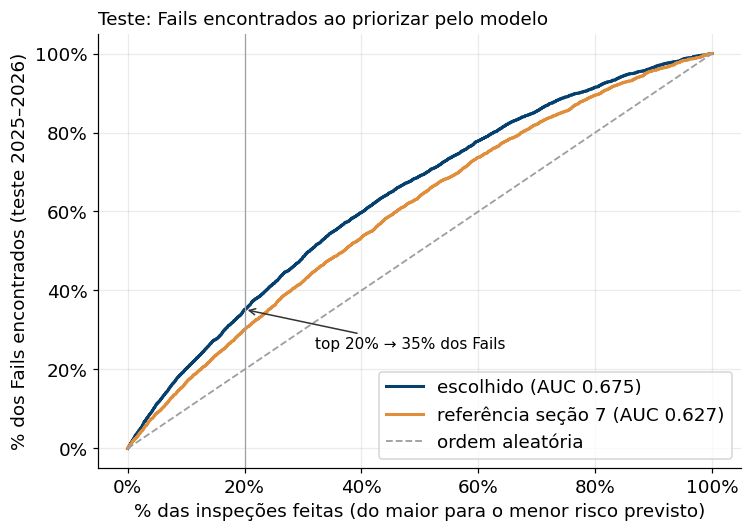

In [ ]:
# ── ÚNICO uso do teste (2025 → 23/09/2026) ────────────────────────────────────
# Decisões congeladas ANTES desta célula: modelo, hiperparâmetros e conjunto de features.
# Reajusta no treino + validação (≤ 2024) e mede uma vez no teste. A referência da seção 7
# entra na mesma célula só como comparação; nenhuma decisão é tomada depois daqui.
MODELO_FINAL, FEATURES_FINAIS = ESCOLHA_MODELO, CONJ_ATUAL
dev_z, te_z = tr_z | va_z, ~(tr_z | va_z)
yt = dz.loc[te_z, "fail"].to_numpy()

def medir_teste(features, modelo, params):
    m = montar_modelo(features, modelo, params)
    m.fit(dz.loc[dev_z, features], dz.loc[dev_z, "fail"])
    return m.predict_proba(dz.loc[te_z, features])[:, 1]

p_final = medir_teste(FEATURES_FINAIS, MODELO_FINAL, MELHORES[MODELO_FINAL])
p_ref_t = medir_teste(CONJ_REF, "logistica", MELHORES["logistica"])

print(f"teste: {dz.loc[te_z, 'data'].min().date()} a {dz.loc[te_z, 'data'].max().date()} | "
      f"{te_z.sum():,} inspeções | taxa de Fail {yt.mean():.1%}")
resultado_teste = pd.DataFrame({
    "modelo": [f"{MODELO_FINAL} · conjunto atual (escolhido)", "logística · referência seção 7"],
    "AUC teste": [roc_auc_score(yt, p_final), roc_auc_score(yt, p_ref_t)],
    **{f"Fails no top {q:.0%}": [fails_no_topo(yt, p_final, q), fails_no_topo(yt, p_ref_t, q)] for q in (.10, .20, .30)},
})
display(resultado_teste.round(4))

fig, ax = plt.subplots(figsize=(7, 5))
for p, cor, rot in [(p_final, "#06406F", f"escolhido (AUC {roc_auc_score(yt, p_final):.3f})"),
                    (p_ref_t, "#E08D3C", f"referência seção 7 (AUC {roc_auc_score(yt, p_ref_t):.3f})")]:
    o = np.argsort(-p, kind="stable")
    ax.plot(np.arange(1, len(p) + 1) / len(p), np.cumsum(yt[o]) / yt.sum(), color=cor, lw=2, label=rot)
ax.plot([0, 1], [0, 1], color="#9AA0A6", ls="--", lw=1.2, label="ordem aleatória")
ax.axvline(.2, color="#9AA0A6", lw=.8)
p20 = fails_no_topo(yt, p_final)
ax.annotate(f"top 20% → {p20:.0%} dos Fails", (0.2, p20), xytext=(0.32, p20 - 0.10), fontsize=10,
            arrowprops=dict(arrowstyle="->", color="#333333"))
ax.xaxis.set_major_formatter(PercentFormatter(1)); ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("% das inspeções feitas (do maior para o menor risco previsto)")
ax.set_ylabel("% dos Fails encontrados (teste 2025–2026)")
ax.set_title("Teste: Fails encontrados ao priorizar pelo modelo", loc="left")
ax.legend(loc="lower right"); plt.tight_layout()
plt.savefig(FIGS / "fi-11-teste-ganho.png", dpi=200, bbox_inches="tight")
plt.show()

### Conclusão da comparação de modelos e do teste

**Teste (12.943 inspeções, 2025 → set/2026, 22,5% de Fail), medido uma única vez:**

| | AUC teste | Fails no top 10% | **top 20%** | top 30% |
|---|---|---|---|---|
| **logística · conjunto atual (escolhido)** | **0,675** | 20,2% | **35,2%** | 48,5% |
| logística · referência seção 7 | 0,627 | 16,7% | 30,1% | 42,3% |
| ordem aleatória | 0,500 | 10% | 20% | 30% |

📌 **O resultado se sustenta no futuro.** A AUC caiu de 0,685 na validação para 0,675 no teste
(−0,010), uma queda pequena e esperada: a janela de 90 dias, as features e os hiperparâmetros foram
escolhidos olhando a validação. O ganho sobre a referência se manteve: +0,048 de AUC.

📌 **Efeito prático:** visitando primeiro os 20% de maior risco, a fiscalização encontra **35%** dos Fails,
contra 30% com a referência da seção 7 e 20% em ordem aleatória (≈ 1,8 vez o aleatório).

📌 **Por que esse modelo e essas features:**
- **Modelo: regressão logística.** Random Forest e HGB, ajustados na mesma validação, ficaram +0,002
  acima, dentro do ruído (ICs incluem zero), e empataram no top 20%. Isso confirma a conclusão da
  comparação anterior (seção 8, split 80/20): o limite está na **informação** das features, não no tipo
  de modelo. Com desempenho igual, fica o modelo mais simples e interpretável.
- **Features: as 6 aprovadas.** O ganho do projeto veio delas (+0,065 de AUC da referência ao conjunto
  atual, nos três modelos). A taxa recente de Fail do Zip (`zip_taxa_90d_def7`) é a mais importante; o
  histórico do estabelecimento (`media_viol_3`, `taxa_fail_hist`, `viol_ultima_rotina`), o tipo e o
  tamanho da rede completam o conjunto.

**Limitações e riscos**
- **O teste foi usado uma vez; não pode ser reusado** para escolher outro modelo ou feature sem perder
  a validade. Uma nova rodada precisa de dados novos (inspeções depois de 23/09/2026).
- `zip_taxa_90d_def7` depende de uma defasagem de publicação suposta (7 dias), e o mecanismo por trás do
  ganho não foi verificado: ele pode refletir, em parte, **quem** fiscaliza.
- **Realimentação:** se a fila passar a ser montada pelo modelo, a taxa recente do Zip passa a depender
  das escolhas do próprio modelo. É preciso monitorar a AUC e o top 20% ao longo do tempo e retreinar
  periodicamente.
- A AUC é moderada (0,675). O modelo serve para **priorizar** a fila, não para afirmar quem vai reprovar.
  A decisão de adotá-lo precisa de validação humana pela equipe de fiscalização.
- O IC por bootstrap é um pouco otimista, porque inspeções do mesmo estabelecimento não são
  independentes.

---
## 12 · Árvore fora do padrão e maior

**Pergunta:** se a árvore sair dos parâmetros padrão e ficar maior (mais profunda, mais árvores no
Random Forest), ela passa a ordenar a fila melhor que a logística?

**Protocolo** (o mesmo da seção 11, para os números serem comparáveis):

| item | definição |
|---|---|
| base e split | `dz`, treino ≤ 31/12/2022, validação 2023–2024 |
| features | as 6 do conjunto atual (`CONJ_ATUAL`) |
| pré-processamento | o do Random Forest da seção 11: imputação pela mediana + indicador de ausência, one-hot |
| métricas | AUC de **treino** e de **validação** (a diferença entre as duas mede o *overfitting*) e % dos Fails no top 20% |
| critério | ganho > `LIMIAR` (0,001) **e** IC 95% por bootstrap pareado (`BOOT_Z`) acima de zero |

⚠️ **O teste não é usado nesta seção.** Ele já foi consumido uma vez na seção 11. Se uma árvore maior
passar no critério aqui, ela vira **candidata para a próxima rodada**, que precisa de dados novos
(inspeções depois de 23/09/2026) para ser medida sem viés.

Três passos:
1. **Uma árvore de decisão sozinha**, aumentando `max_depth` até "sem limite" (o padrão do scikit-learn).
2. **Random Forest maior**: grade de `max_depth` × `min_samples_leaf`, comparada com o RF totalmente padrão
   e com o RF ajustado da seção 11 (`max_depth=8`, `min_samples_leaf=20`).
3. **Ajuste fino** do melhor RF (`max_features`, `class_weight`, `n_estimators`) e comparação com a logística.

In [ ]:
# ── 12 · árvores fora do padrão (SÓ treino ≤ 2022 e validação 2023–2024) ──
from sklearn.tree import DecisionTreeClassifier

FEATS_ARV = CONJ_ATUAL
X_tr_arv, y_tr_arv = dz.loc[tr_z, FEATS_ARV], dz.loc[tr_z, "fail"].to_numpy()
X_va_arv, y_va_arv = dz.loc[va_z, FEATS_ARV], dz.loc[va_z, "fail"].to_numpy()

def montar_arvore(estimador, features=FEATS_ARV):
    """Mesmo pré-processamento do Random Forest da seção 11, com qualquer árvore no fim."""
    num, cat = separar_tipos(features)
    etapas = []
    if num:
        etapas.append((SimpleImputer(strategy="median", add_indicator=True), num))
    if cat:
        etapas.append((OneHotEncoder(handle_unknown="ignore", min_frequency=100), cat))
    return make_pipeline(make_column_transformer(*etapas), estimador)

PROBS_ARV = {}   # probabilidades de validação de cada configuração (para o bootstrap)

def avaliar_arvore(estimador, rotulo, **params):
    """Treina no treino e devolve AUC de treino, AUC de validação, a diferença e o top 20%."""
    t0 = time.time()
    m = montar_arvore(estimador).fit(X_tr_arv, y_tr_arv)
    p_tr = m.predict_proba(X_tr_arv)[:, 1]
    p_va = m.predict_proba(X_va_arv)[:, 1]
    PROBS_ARV[rotulo] = p_va
    auc_tr, auc_va = roc_auc_score(y_tr_arv, p_tr), roc_auc_score(y_va_arv, p_va)
    return {"config": rotulo, **params, "auc_treino": auc_tr, "auc_validação": auc_va,
            "treino − validação": auc_tr - auc_va, "top20": fails_no_topo(y_va_arv, p_va),
            "segundos": time.time() - t0}

def rotulo_prof(d):
    return "sem limite" if d is None else str(d)

# referências da seção 11, nas mesmas inspeções de validação
c3 = list(CONJUNTOS)[2]
P_LOG, P_RF11 = PROBS[(c3, "logistica")], PROBS[(c3, "random_forest")]
AUC_LOG, AUC_RF11 = roc_auc_score(y_va_arv, P_LOG), roc_auc_score(y_va_arv, P_RF11)
print(f"logística (seção 11)     : AUC validação = {AUC_LOG:.4f}")
print(f"RF ajustado (seção 11)   : AUC validação = {AUC_RF11:.4f}  {MELHORES['random_forest']}")

logística (seção 11)     : AUC validação = 0.6853
RF ajustado (seção 11)   : AUC validação = 0.6869  {'max_depth': 8, 'min_samples_leaf': 20}


#### Passo 1 · Uma árvore de decisão sozinha: o que acontece quando ela cresce

O padrão do `DecisionTreeClassifier` é crescer **sem limite de profundidade** e com 1 inspeção por folha.
Aumentamos `max_depth` de 2 até "sem limite", com e sem um mínimo de 50 inspeções por folha
(`min_samples_leaf=50`), que funciona como uma poda.

In [ ]:
PROFUNDIDADES = [2, 4, 6, 8, 10, 12, 16, 20, 24, 32, None]

linhas = []
for folha in (1, 50):
    for d in PROFUNDIDADES:
        linhas.append(avaliar_arvore(
            DecisionTreeClassifier(max_depth=d, min_samples_leaf=folha, random_state=0),
            f"árvore · max_depth={rotulo_prof(d)} · leaf={folha}",
            max_depth=rotulo_prof(d), min_samples_leaf=folha))
tab_dt = pd.DataFrame(linhas)

print("Árvore de decisão (1 árvore). Linha 'sem limite · leaf=1' = parâmetros padrão do scikit-learn.")
display(tab_dt.drop(columns="config").round(4))
melhor_dt = tab_dt.loc[tab_dt["auc_validação"].idxmax()]
print(f"melhor árvore única: {melhor_dt['config']} -> AUC validação {melhor_dt['auc_validação']:.4f} "
      f"(logística {AUC_LOG:.4f})")

Árvore de decisão (1 árvore). Linha 'sem limite · leaf=1' = parâmetros padrão do scikit-learn.


,max_depth,min_samples_leaf,auc_treino,auc_validação,treino − validação,top20,segundos
0,2,1,0.6375,0.6363,0.0013,0.3011,0.1527
1,4,1,0.6723,0.6647,0.0076,0.3303,0.2038
2,6,1,0.6913,0.6748,0.0165,0.3487,0.1858
3,8,1,0.7120,0.6669,0.0452,0.3442,0.2085
4,10,1,0.7477,0.6373,0.1103,0.3125,0.2367
5,12,1,0.7958,0.6127,0.1831,0.2993,0.2560
6,16,1,0.9030,0.5614,0.3416,0.2751,0.2782
7,20,1,0.9687,0.5436,0.4251,0.2579,0.3004
8,24,1,0.9913,0.5433,0.4480,0.2567,0.3389
9,32,1,0.9994,0.5422,0.4572,0.2492,0.3259


melhor árvore única: árvore · max_depth=6 · leaf=50 -> AUC validação 0.6759 (logística 0.6853)


#### Passo 2 · Random Forest maior

Grade com 300 árvores: `max_depth` ∈ {8, 12, 16, 24, 32, sem limite} × `min_samples_leaf` ∈ {1, 5, 20, 50}.
A seção 11 só foi até `max_depth=16` e `min_samples_leaf` ≥ 20. Entram também, como referência, o RF
**totalmente padrão** (100 árvores, sem limite de profundidade, 1 inspeção por folha) e o RF da seção 11.

In [ ]:
linhas = [avaliar_arvore(RandomForestClassifier(n_jobs=-1, random_state=0),
                        "RF padrão do scikit-learn (100 árvores, sem limites)",
                        max_depth="sem limite", min_samples_leaf=1, n_estimators=100)]

t0 = time.time()
for d in (8, 12, 16, 24, 32, None):
    for folha in (1, 5, 20, 50):
        linhas.append(avaliar_arvore(
            RandomForestClassifier(n_estimators=300, max_depth=d, min_samples_leaf=folha,
                                   n_jobs=-1, random_state=0),
            f"RF · max_depth={rotulo_prof(d)} · leaf={folha}",
            max_depth=rotulo_prof(d), min_samples_leaf=folha, n_estimators=300))
print(f"grade de {len(linhas) - 1} Random Forests em {time.time() - t0:.0f}s")

tab_rf = pd.DataFrame(linhas)
display(tab_rf.drop(columns="config").sort_values("auc_validação", ascending=False).round(4))

grade_rf = tab_rf.iloc[1:]
melhor_rf = grade_rf.loc[grade_rf["auc_validação"].idxmax()]
D_MELHOR = None if melhor_rf["max_depth"] == "sem limite" else int(melhor_rf["max_depth"])
F_MELHOR = int(melhor_rf["min_samples_leaf"])
print(f"melhor RF da grade: {melhor_rf['config']} -> AUC validação {melhor_rf['auc_validação']:.4f}")

grade de 24 Random Forests em 267s


,max_depth,min_samples_leaf,n_estimators,auc_treino,auc_validação,treino − validação,top20,segundos
3,8,20,300,0.7086,0.6869,0.0218,0.3599,4.8157
1,8,1,300,0.7219,0.6867,0.0352,0.3569,4.9655
2,8,5,300,0.7157,0.6866,0.0291,0.3592,6.5146
8,12,50,300,0.7141,0.6863,0.0278,0.3637,6.0826
7,12,20,300,0.7324,0.6862,0.0462,0.3574,6.7013
19,32,20,300,0.7552,0.6860,0.0692,0.3567,13.0343
23,sem limite,20,300,0.7552,0.6860,0.0692,0.3567,10.2628
15,24,20,300,0.7553,0.6860,0.0694,0.3574,6.9268
4,8,50,300,0.7036,0.6859,0.0177,0.3599,4.7283
20,32,50,300,0.7187,0.6858,0.0329,0.3599,10.5431


melhor RF da grade: RF · max_depth=8 · leaf=20 -> AUC validação 0.6869


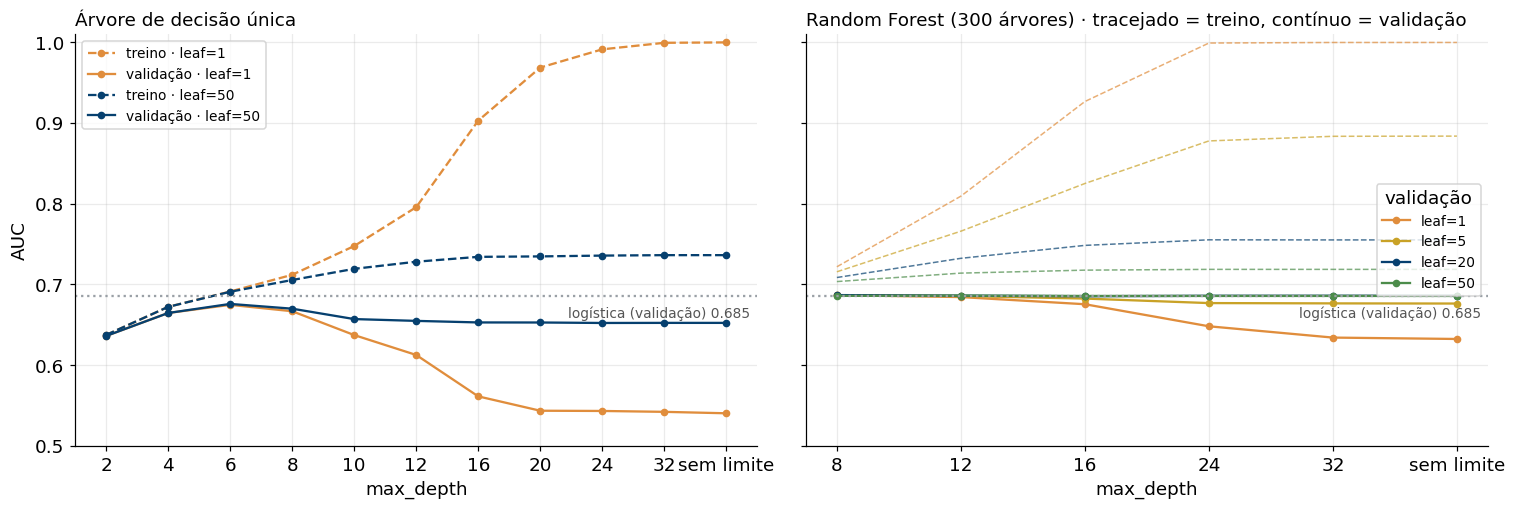

In [ ]:
# ── gráfico: AUC de treino × validação conforme a árvore cresce ──────────────
fig, axs = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
x_lab = [rotulo_prof(d) for d in PROFUNDIDADES]

ax = axs[0]
for folha, cor in ((1, LARANJA), (50, AZUL)):
    t = tab_dt[tab_dt["min_samples_leaf"] == folha]
    ax.plot(x_lab, t["auc_treino"], color=cor, ls="--", marker="o", ms=4, label=f"treino · leaf={folha}")
    ax.plot(x_lab, t["auc_validação"], color=cor, marker="o", ms=4, label=f"validação · leaf={folha}")
ax.set_title("Árvore de decisão única", loc="left")
ax.set_xlabel("max_depth")
ax.set_ylabel("AUC")

ax = axs[1]
x_rf = ["8", "12", "16", "24", "32", "sem limite"]
cores_folha = {1: LARANJA, 5: "#C9A227", 20: AZUL, 50: "#4C8C4A"}
for folha, cor in cores_folha.items():
    t = grade_rf[grade_rf["min_samples_leaf"] == folha].set_index("max_depth").loc[x_rf]
    ax.plot(x_rf, t["auc_treino"], color=cor, ls="--", lw=1, alpha=.7)
    ax.plot(x_rf, t["auc_validação"], color=cor, marker="o", ms=4, label=f"leaf={folha}")
ax.set_title("Random Forest (300 árvores) · tracejado = treino, contínuo = validação", loc="left")
ax.set_xlabel("max_depth")
ax.legend(title="validação", loc="center right", fontsize=9)

for ax in axs:
    ax.axhline(AUC_LOG, color=CINZA, ls=":", lw=1.5)
    ax.text(.99, AUC_LOG - .012, f"logística (validação) {AUC_LOG:.3f}", color="#555555", fontsize=9,
            ha="right", va="top", transform=ax.get_yaxis_transform())
axs[0].legend(loc="upper left", fontsize=9)
axs[0].set_ylim(.50, 1.01)
plt.tight_layout()
plt.savefig(FIGS / "fi-12-arvore-profundidade.png", dpi=200, bbox_inches="tight")
plt.show()

#### Passo 3 · Ajuste fino do melhor RF e comparação com a logística

Partindo do melhor RF da grade, muda **um parâmetro por vez**:
- `max_features`: quantas colunas cada divisão sorteia (`"sqrt"`, o padrão; 50%; todas)
- `class_weight="balanced_subsample"`: dá mais peso aos Fails (≈ 24% do treino)
- `n_estimators`: 300 → 600 → 1000 árvores

Depois, IC 95% por bootstrap pareado (`BOOT_Z`, as mesmas reamostragens das seções anteriores) da diferença
de AUC contra a logística e contra o RF da seção 11.

In [ ]:
base_rf = dict(n_estimators=300, max_depth=D_MELHOR, min_samples_leaf=F_MELHOR)
variacoes = [("max_features", 0.5), ("max_features", None),
             ("class_weight", "balanced_subsample"),
             ("n_estimators", 600), ("n_estimators", 1000)]

PARAMS_FINO = {melhor_rf["config"]: base_rf}
linhas = [melhor_rf.to_dict() | {"variação": "(melhor da grade)"}]
for chave, valor in variacoes:
    params = base_rf | {chave: valor}
    PARAMS_FINO[f"{melhor_rf['config']} · {chave}={valor}"] = params
    r = avaliar_arvore(RandomForestClassifier(n_jobs=-1, random_state=0, **params),
                       f"{melhor_rf['config']} · {chave}={valor}",
                       max_depth=rotulo_prof(D_MELHOR), min_samples_leaf=F_MELHOR,
                       n_estimators=params["n_estimators"])
    linhas.append(r | {"variação": f"{chave}={valor}"})
tab_fino = pd.DataFrame(linhas)
display(tab_fino[["variação", "auc_treino", "auc_validação", "treino − validação", "top20", "segundos"]].round(4))

FINAL_ARV = tab_fino.loc[tab_fino["auc_validação"].idxmax(), "config"]
P_ARV = PROBS_ARV[FINAL_ARV]
print(f"árvore escolhida na validação: {FINAL_ARV}")

# ── IC 95% (bootstrap pareado) da diferença de AUC ──────────────────────────────
def comparar(p_a, p_b):
    dif = [roc_auc_score(y_va_arv[i], p_a[i]) - roc_auc_score(y_va_arv[i], p_b[i]) for i in BOOT_Z]
    lo, hi = np.percentile(dif, [2.5, 97.5])
    ganho = roc_auc_score(y_va_arv, p_a) - roc_auc_score(y_va_arv, p_b)
    return ganho, lo, hi, "passa" if (ganho > LIMIAR_Z and lo > 0) else "não passa"

linhas = []
for nome, p in [("RF padrão do scikit-learn", PROBS_ARV["RF padrão do scikit-learn (100 árvores, sem limites)"]),
                ("árvore única (melhor profundidade)", PROBS_ARV[melhor_dt["config"]]),
                ("árvore única padrão (sem limite, leaf=1)", PROBS_ARV["árvore · max_depth=sem limite · leaf=1"]),
                ("RF grande (sem limite · leaf=20)", PROBS_ARV["RF · max_depth=sem limite · leaf=20"]),
                (f"melhor RF da grade ampliada ({FINAL_ARV.removeprefix('RF · ')})", P_ARV)]:
    for ref_nome, p_ref_ in [("logística", P_LOG), ("RF seção 11", P_RF11)]:
        g, lo, hi, dec = comparar(p, p_ref_)
        linhas.append({"modelo": nome, "contra": ref_nome, "AUC modelo": roc_auc_score(y_va_arv, p),
                       "ganho AUC": g, "IC 2,5%": lo, "IC 97,5%": hi, "critério": dec})
comparacao_arv = pd.DataFrame(linhas)
display(comparacao_arv.round(4))

,variação,auc_treino,auc_validação,treino − validação,top20,segundos
0,(melhor da grade),0.7086,0.6869,0.0218,0.3599,4.8157
1,max_features=0.5,0.7176,0.6859,0.0317,0.3589,9.7688
2,max_features=None,0.7236,0.6838,0.0398,0.3579,17.9185
3,class_weight=balanced_subsample,0.7091,0.6868,0.0224,0.3559,8.3612
4,n_estimators=600,0.7086,0.6869,0.0217,0.3614,10.9028
5,n_estimators=1000,0.7086,0.6868,0.0218,0.3599,18.9483


árvore escolhida na validação: RF · max_depth=8 · leaf=20


,modelo,contra,AUC modelo,ganho AUC,"IC 2,5%","IC 97,5%",critério
0,RF padrão do scikit-learn,logística,0.6304,-0.0549,-0.0626,-0.0459,não passa
1,RF padrão do scikit-learn,RF seção 11,0.6304,-0.0565,-0.0640,-0.0478,não passa
2,árvore única (melhor profundidade),logística,0.6759,-0.0094,-0.0132,-0.0050,não passa
3,árvore única (melhor profundidade),RF seção 11,0.6759,-0.0109,-0.0142,-0.0071,não passa
4,"árvore única padrão (sem limite, leaf=1)",logística,0.5404,-0.1449,-0.1549,-0.1339,não passa
5,"árvore única padrão (sem limite, leaf=1)",RF seção 11,0.5404,-0.1464,-0.1574,-0.1360,não passa
6,RF grande (sem limite · leaf=20),logística,0.6860,0.0007,-0.0017,0.0039,não passa
7,RF grande (sem limite · leaf=20),RF seção 11,0.6860,-0.0009,-0.0024,0.0010,não passa
8,melhor RF da grade ampliada (max_depth=8 · lea...,logística,0.6869,0.0016,-0.0006,0.0040,não passa
9,melhor RF da grade ampliada (max_depth=8 · lea...,RF seção 11,0.6869,0.0000,0.0000,0.0000,não passa


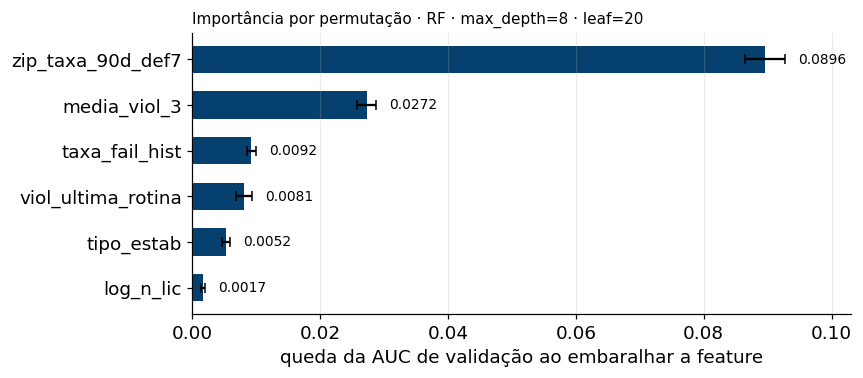

In [ ]:
# ── o que a árvore maior usa: importância por permutação na validação ─────────
from sklearn.inspection import permutation_importance

modelo_arv = montar_arvore(RandomForestClassifier(n_jobs=-1, random_state=0, **PARAMS_FINO[FINAL_ARV]))
modelo_arv.fit(X_tr_arv, y_tr_arv)
assert np.allclose(modelo_arv.predict_proba(X_va_arv)[:, 1], P_ARV), "o refit não reproduz a árvore escolhida"

imp = permutation_importance(modelo_arv, X_va_arv, y_va_arv, scoring="roc_auc",
                             n_repeats=5, random_state=0, n_jobs=-1)
imp_arv = (pd.DataFrame({"feature": FEATS_ARV, "queda de AUC": imp.importances_mean, "dp": imp.importances_std})
           .sort_values("queda de AUC"))

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(imp_arv["feature"], imp_arv["queda de AUC"], xerr=imp_arv["dp"], color=AZUL, height=.6, capsize=3)
for y_, (v, dp) in enumerate(zip(imp_arv["queda de AUC"], imp_arv["dp"])):
    ax.text(v + dp + .002, y_, f"{v:.4f}", va="center", fontsize=9)
ax.set_xlim(0, imp_arv["queda de AUC"].max() * 1.15)
ax.set_xlabel("queda da AUC de validação ao embaralhar a feature")
ax.set_title(f"Importância por permutação · {FINAL_ARV}", loc="left", fontsize=10)
ax.grid(axis="y", alpha=0)
plt.tight_layout(); plt.show()

### Conclusão da árvore fora do padrão

**Resultado** (validação 2023–2024; ganho e IC 95% contra a logística da seção 11, AUC 0,6853):

| modelo | AUC treino | AUC validação | ganho vs logística [IC 95%] | top 20% |
|---|---|---|---|---|
| árvore única **padrão** (sem limite, 1 por folha) | 0,9999 | 0,5404 | −0,145 [−0,155; −0,134] | 25,2% |
| árvore única, melhor profundidade (`max_depth=6`, `leaf=50`) | 0,6910 | 0,6759 | −0,009 [−0,013; −0,005] | 35,0% |
| RF **padrão** (100 árvores, sem limites) | 0,9998 | 0,6304 | −0,055 [−0,063; −0,046] | 30,7% |
| RF grande (300 árvores, sem limite, `leaf=20`) | 0,7552 | 0,6860 | +0,0007 [−0,0017; +0,0039] | 35,7% |
| **melhor RF da grade ampliada** (`max_depth=8`, `leaf=20`) | 0,7086 | **0,6869** | +0,0016 [−0,0006; +0,0040] | 36,0% |

📌 **Usar os parâmetros padrão é o pior cenário.** Sem limite de profundidade, a árvore decora o treino
(AUC 0,9999) e, na validação, fica pouco acima de uma ordem aleatória (0,540). O RF padrão sofre do mesmo
jeito (0,630): a média de 100 árvores reduz o estrago, mas não resolve. O gráfico mostra o padrão clássico
de *overfitting*: a AUC de treino sobe sem parar e a de validação cai a partir de `max_depth` ≈ 6–8.

📌 **"Aumentar" a árvore só não prejudica quando outra regra segura o crescimento.** Com
`min_samples_leaf` ≥ 20, a árvore para de crescer sozinha por volta de `max_depth` 16–24, e a AUC de
validação fica estável (≈ 0,686) em qualquer profundidade. Com 1 ou 5 inspeções por folha, cada nível a
mais custa AUC. Mais árvores (600 ou 1000), `max_features` maior e `class_weight="balanced_subsample"`
não mudaram nada além da 4ª casa decimal.

📌 **A melhor configuração da grade ampliada é a mesma da seção 11** (`max_depth=8`, `min_samples_leaf=20`).
Ela fica +0,0016 acima da logística, com o IC incluindo zero, e **não passa no critério**. O RF grande que
ainda generaliza (sem limite, `leaf=20`) também não passa (+0,0007).

📌 **A importância por permutação repete a ablação da seção 11:** `zip_taxa_90d_def7` (−0,090 de AUC
ao embaralhar) e `media_viol_3` (−0,027) carregam o modelo. A árvore usa as mesmas features que a logística
e não encontra nelas interações que a logística deixe de captar.

**Decisão:** nada muda na seção 11. A **regressão logística continua sendo o modelo escolhido**. Um modelo
de árvore, se for usado no futuro, deve ter `max_depth` ≤ 8 ou `min_samples_leaf` ≥ 20, e nunca os
parâmetros padrão. A conclusão da seção 11 se confirma: o limite está na informação das features, não no
tamanho do modelo.

**Limitações**
- Todas as escolhas foram feitas na validação, olhando dezenas de configurações. A melhor AUC tem um leve
  viés otimista, que só um conjunto novo (inspeções depois de 23/09/2026) pode medir.
- O bootstrap supõe inspeções independentes, e inspeções do mesmo estabelecimento não são, então o IC é
  um pouco estreito demais.

## 13 · Regularização da regressão logística: Ridge e Lasso

Vamos testar se controlar os coeficientes da regressão logística melhora a previsão de Fail. Usaremos as mesmas features e o mesmo corte temporal da seção 11.

- **Ridge (L2):** reduz os coeficientes.
- **Lasso (L1):** pode reduzir alguns coeficientes exatamente a zero.
- **C menor:** regularização mais forte.

Todas as escolhas serão feitas na validação de 2023–2024. O teste não será usado nesta seção.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

REG_FEATS = list(CONJ_ATUAL)

REG_X_TR = dz.loc[tr_z, REG_FEATS]
REG_Y_TR = dz.loc[tr_z, "fail"].to_numpy()

REG_X_VA = dz.loc[va_z, REG_FEATS]
REG_Y_VA = dz.loc[va_z, "fail"].to_numpy()

REG_C_ATUAL = MELHORES["logistica"]["C"]
REG_ATUAL = montar_modelo(REG_FEATS, "logistica", MELHORES["logistica"])
REG_ATUAL.fit(REG_X_TR, REG_Y_TR)

REG_P_ATUAL = REG_ATUAL.predict_proba(REG_X_VA)[:, 1]
REG_AUC_ATUAL = roc_auc_score(REG_Y_VA, REG_P_ATUAL)

print(f"Logística atual: L2, C={REG_C_ATUAL}")
print(f"AUC na validação: {REG_AUC_ATUAL:.4f}")
print("Features:", REG_FEATS)

Logística atual: L2, C=0.01
AUC na validação: 0.6853
Features: ['taxa_fail_hist', 'viol_ultima_rotina', 'tipo_estab', 'zip_taxa_90d_def7', 'log_n_lic', 'media_viol_3']


In [ ]:
REG_GRADE_C = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]

REG_MODELOS = {}
REG_COEFS = {}
REG_LINHAS = []

for penalidade, solver in [("l2", "lbfgs"), ("l1", "liblinear")]:
    for c in REG_GRADE_C:
        params = {"C": c, "solver": solver}

        if penalidade == "l1":
            params["penalty"] = "l1"

        modelo = montar_modelo(REG_FEATS, "logistica", params)
        modelo.fit(REG_X_TR, REG_Y_TR)

        prob_treino = modelo.predict_proba(REG_X_TR)[:, 1]
        prob_validacao = modelo.predict_proba(REG_X_VA)[:, 1]

        nomes = modelo.named_steps["columntransformer"].get_feature_names_out()
        coef = modelo.named_steps["logisticregression"].coef_[0]

        REG_MODELOS[(penalidade, c)] = modelo
        REG_COEFS[(penalidade, c)] = pd.Series(coef, index=nomes)

        auc_treino = roc_auc_score(REG_Y_TR, prob_treino)
        auc_validacao = roc_auc_score(REG_Y_VA, prob_validacao)

        REG_LINHAS.append({
            "penalidade": penalidade,
            "C": c,
            "auc_treino": auc_treino,
            "auc_validacao": auc_validacao,
            "treino_menos_validacao": auc_treino - auc_validacao,
            "coeficientes_zerados": int((coef == 0).sum()),
            "total_coeficientes": len(coef)
        })

REG_TABELA = pd.DataFrame(REG_LINHAS)
display(REG_TABELA.round(4))

REG_MELHORES = REG_TABELA.loc[
    REG_TABELA.groupby("penalidade")["auc_validacao"].idxmax()
].sort_values("penalidade")

print("Melhor configuração de cada penalidade:")
display(REG_MELHORES.round(4))

,penalidade,C,auc_treino,auc_validacao,treino_menos_validacao,coeficientes_zerados,total_coeficientes
0,l2,0.001,0.6855,0.6844,0.0012,0,19
1,l2,0.010,0.6870,0.6853,0.0017,0,19
2,l2,0.100,0.6872,0.6851,0.0020,0,19
3,l2,1.000,0.6871,0.6850,0.0022,0,19
4,l2,10.000,0.6871,0.6849,0.0022,0,19
5,l2,100.000,0.6871,0.6849,0.0022,0,19
6,l1,0.001,0.6789,0.6778,0.0012,15,19
7,l1,0.010,0.6846,0.6832,0.0014,10,19
8,l1,0.100,0.6871,0.6851,0.0019,5,19
9,l1,1.000,0.6872,0.6850,0.0022,1,19


Melhor configuração de cada penalidade:


,penalidade,C,auc_treino,auc_validacao,treino_menos_validacao,coeficientes_zerados,total_coeficientes
8,l1,0.10,0.6871,0.6851,0.0019,5,19
1,l2,0.01,0.6870,0.6853,0.0017,0,19


In [ ]:
REG_C_L1 = float(
    REG_MELHORES.loc[
        REG_MELHORES["penalidade"] == "l1", "C"
    ].iloc[0]
)

REG_COEF_L1 = REG_COEFS[("l1", REG_C_L1)]

REG_DETALHE = pd.DataFrame({
    "coluna_transformada": REG_COEF_L1.index,
    "coeficiente": REG_COEF_L1.to_numpy()
})

print(f"Coeficientes zerados pelo melhor Lasso (C={REG_C_L1}):")
display(REG_DETALHE.loc[REG_DETALHE["coeficiente"] == 0])

def reg_feature_original(nome):
    parte = nome.split("__", 1)[-1]

    for feature in REG_FEATS:
        if (
            parte == feature
            or parte.startswith(feature + "_")
            or parte == "missingindicator_" + feature
        ):
            return feature

    return "verificar nome"

REG_DETALHE["feature_original"] = (
    REG_DETALHE["coluna_transformada"].map(reg_feature_original)
)

REG_RESUMO = (
    REG_DETALHE
    .groupby("feature_original")["coeficiente"]
    .agg(
        colunas="size",
        ativas=lambda x: int((x != 0).sum()),
        zeradas=lambda x: int((x == 0).sum())
    )
    .reset_index()
)

REG_RESUMO["feature_inteira_descartada"] = REG_RESUMO["ativas"] == 0

print("Comparação com as features escolhidas na seção 7:")
display(REG_RESUMO)

Coeficientes zerados pelo melhor Lasso (C=0.1):


,coluna_transformada,coeficiente
8,onehotencoder__tipo_estab_BAKERY,0.0
9,onehotencoder__tipo_estab_CATERING,0.0
11,onehotencoder__tipo_estab_DAYCARE (2 - 6 YEARS),0.0
12,onehotencoder__tipo_estab_DAYCARE ABOVE AND UN...,0.0
17,onehotencoder__tipo_estab_RESTAURANT,0.0


Comparação com as features escolhidas na seção 7:


,feature_original,colunas,ativas,zeradas,feature_inteira_descartada
0,log_n_lic,1,1,0,False
1,media_viol_3,2,2,0,False
2,taxa_fail_hist,2,2,0,False
3,tipo_estab,11,6,5,False
4,viol_ultima_rotina,2,2,0,False
5,zip_taxa_90d_def7,1,1,0,False


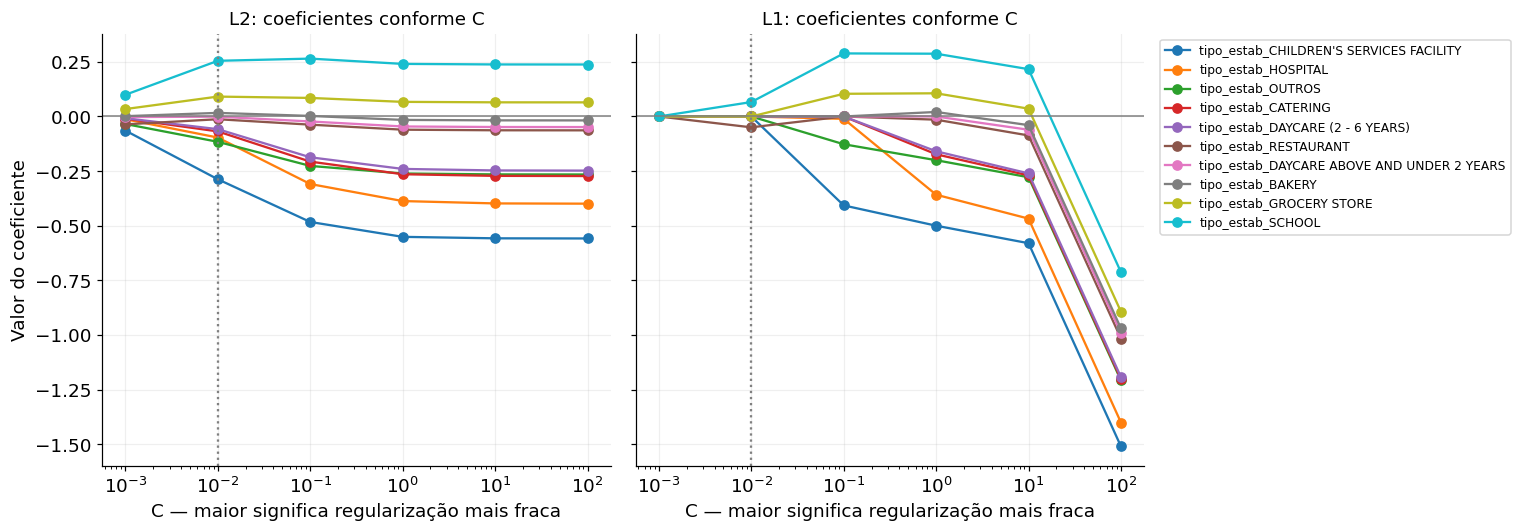

In [ ]:
REG_TOP = (
    pd.concat([serie.abs() for serie in REG_COEFS.values()], axis=1)
    .max(axis=1)
    .nlargest(10)
    .index
)

fig, eixos = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for eixo, penalidade in zip(eixos, ["l2", "l1"]):
    for nome in REG_TOP:
        valores = [
            REG_COEFS[(penalidade, c)].loc[nome]
            for c in REG_GRADE_C
        ]
        eixo.plot(REG_GRADE_C, valores, marker="o",
                  label=nome.split("__", 1)[-1])

    eixo.set_xscale("log")
    eixo.axhline(0, color="gray", linewidth=1)
    eixo.axvline(REG_C_ATUAL, color="gray", linestyle=":")
    eixo.set_title(f"{penalidade.upper()}: coeficientes conforme C")
    eixo.set_xlabel("C — maior significa regularização mais fraca")
    eixo.grid(alpha=0.2)

eixos[0].set_ylabel("Valor do coeficiente")
eixos[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)

plt.tight_layout()
plt.show()

In [ ]:
REG_COMPARACOES = []

for penalidade in ["l2", "l1"]:
    linha = REG_MELHORES.loc[
        REG_MELHORES["penalidade"] == penalidade
    ].iloc[0]

    c = float(linha["C"])
    modelo = REG_MODELOS[(penalidade, c)]
    prob = modelo.predict_proba(REG_X_VA)[:, 1]

    auc = roc_auc_score(REG_Y_VA, prob)
    ganho = auc - REG_AUC_ATUAL

    ganhos_boot = [
        roc_auc_score(REG_Y_VA[i], prob[i])
        - roc_auc_score(REG_Y_VA[i], REG_P_ATUAL[i])
        for i in BOOT_Z
    ]
    ic_min, ic_max = np.percentile(ganhos_boot, [2.5, 97.5])

    REG_COMPARACOES.append({
        "modelo": f"{penalidade.upper()} — C={c}",
        "auc_validacao": auc,
        "ganho_vs_atual": ganho,
        "IC_95_min": ic_min,
        "IC_95_max": ic_max,
        "supera_atual": (
            "sim" if ganho > LIMIAR_Z and ic_min > 0 else "não"
        )
    })

print(f"Referência: logística atual = {REG_AUC_ATUAL:.4f}")
display(pd.DataFrame(REG_COMPARACOES).round(4))

Referência: logística atual = 0.6853


,modelo,auc_validacao,ganho_vs_atual,IC_95_min,IC_95_max,supera_atual
0,L2 — C=0.01,0.6853,0.0000,0.0000,0.0000,não
1,L1 — C=0.1,0.6851,-0.0002,-0.0006,0.0002,não


### Conclusão da regularização

Testamos regressão logística com regularização L2 (Ridge) e L1 (Lasso), variando `C` e mantendo as mesmas seis features e o mesmo corte de treino e validação.

A melhor L2 foi a configuração que já usávamos: `C=0,01`, com AUC de **0,6853** na validação. O melhor Lasso usou `C=0,1` e obteve AUC de **0,6851**, uma diferença de −0,0002 em relação à logística atual. O intervalo de confiança dessa diferença inclui zero, portanto não há evidência de melhora.

O Lasso zerou 5 das 19 colunas criadas pelo pré-processamento, todas referentes a categorias de `tipo_estab`. Nenhuma das seis features originais foi totalmente eliminada. Com regularização L1 muito forte (`C=0,001`), a AUC caiu para 0,6778.

**Decisão:** manter a regressão logística atual com L2 e `C=0,01`. O Lasso simplificou algumas categorias, mas não melhorou a previsão. O conjunto de features escolhido anteriormente permanece.

## Threshold e quanto o modelo acerta ou erra



In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix, precision_score, recall_score,
    f1_score, accuracy_score, precision_recall_curve, average_precision_score
)

def metricas_por_threshold(y, prob, thresholds=np.arange(0.1, 1.0, 0.1)):
    y, prob = np.asarray(y), np.asarray(prob)
    linhas = []
    for t in thresholds:
        t = round(float(t), 2)
        y_pred = (prob >= t).astype(int)
        vn, fp, fn, vp = confusion_matrix(y, y_pred, labels=[0, 1]).ravel()
        alertas = vp + fp
        linhas.append({
            "threshold": t, "VP": vp, "FP": fp, "VN": vn, "FN": fn,
            "precision": vp / alertas if alertas else np.nan,
            "recall": vp / (vp + fn),
            "f1": f1_score(y, y_pred, zero_division=0),
            "acuracia": (vp + vn) / len(y),
            "pct_alertas": alertas / len(y),
        })
    return pd.DataFrame(linhas)

y_val = dz.loc[va_z, "fail"].to_numpy()
prob_val = PROBS[(list(CONJUNTOS)[2], "logistica")]

df_metricas_val = metricas_por_threshold(y_val, prob_val)
display(df_metricas_val.style.format({
    'threshold': '{:.1f}',
    'precision': '{:.1%}',
    'recall': '{:.1%}',
    'f1': '{:.3f}',
    'acuracia': '{:.1%}',
    'pct_alertas': '{:.1%}'
}))

,threshold,VP,FP,VN,FN,precision,recall,f1,acuracia,pct_alertas
0,0.1,3948,10946,917,61,26.5%,98.5%,0.418,30.7%,93.8%
1,0.2,3116,6212,5651,893,33.4%,77.7%,0.467,55.2%,58.8%
2,0.3,1890,2672,9191,2119,41.4%,47.1%,0.441,69.8%,28.7%
3,0.4,1005,1060,10803,3004,48.7%,25.1%,0.331,74.4%,13.0%
4,0.5,498,428,11435,3511,53.8%,12.4%,0.202,75.2%,5.8%
5,0.6,242,170,11693,3767,58.7%,6.0%,0.109,75.2%,2.6%
6,0.7,103,61,11802,3906,62.8%,2.6%,0.049,75.0%,1.0%
7,0.8,32,22,11841,3977,59.3%,0.8%,0.016,74.8%,0.3%
8,0.9,5,9,11854,4004,35.7%,0.1%,0.002,74.7%,0.1%


=== MATRIZ DE CONFUSÃO NO CORTE PADRÃO (0,5) ===
VP : 498
FP : 428
 VN : 11,435
 FN : 3,511
--------------------------------------------------
Precision : 53.8% | Recall : 12.4% | F1 : 0.202 | Acurácia : 75.2%



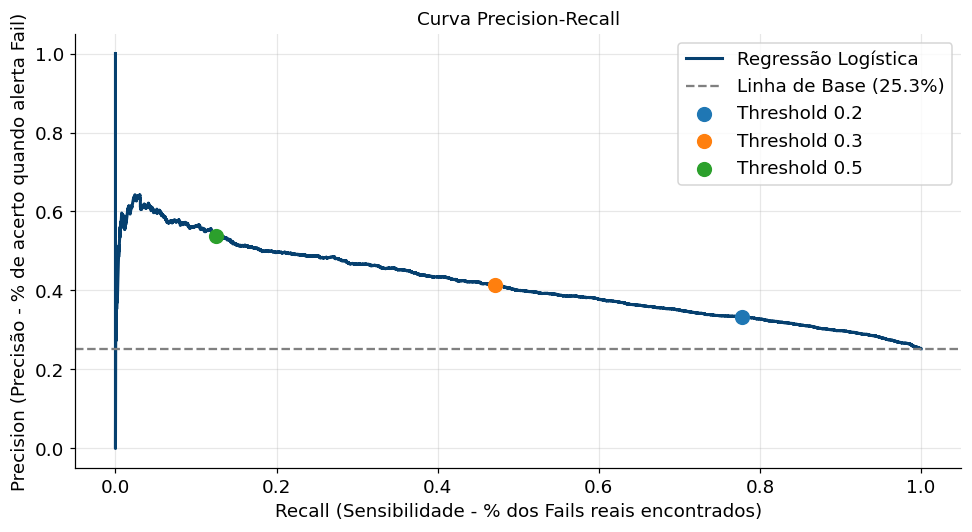

In [ ]:
row_05 = df_metricas_val[df_metricas_val['threshold'] == 0.5].iloc[0]

print("=== MATRIZ DE CONFUSÃO NO CORTE PADRÃO (0,5) ===")
print(f"VP : {int(row_05['VP']):,}")
print(f"FP : {int(row_05['FP']):,}")
print(f" VN : {int(row_05['VN']):,}")
print(f" FN : {int(row_05['FN']):,}")
print("-" * 50)
print(f"Precision : {row_05['precision']:.1%} | Recall : {row_05['recall']:.1%} | F1 : {row_05['f1']:.3f} | Acurácia : {row_05['acuracia']:.1%}\n")

precisions, recalls, pr_thresholds = precision_recall_curve(y_val, prob_val)
ap_score = average_precision_score(y_val, prob_val)
baseline = y_val.mean()

plt.figure(figsize=(9, 5))
plt.plot(recalls, precisions, color='#06406F', linewidth=2, label=f'Regressão Logística')
plt.axhline(baseline, color='gray', linestyle='--', label=f'Linha de Base ({baseline:.1%})')

for t_mark in [0.2, 0.3, 0.5]:
    r = df_metricas_val[df_metricas_val['threshold'] == t_mark].iloc[0]
    plt.scatter(r['recall'], r['precision'], s=80, zorder=5, label=f'Threshold {t_mark}')

plt.title('Curva Precision-Recall')
plt.xlabel('Recall (Sensibilidade - % dos Fails reais encontrados)')
plt.ylabel('Precision (Precisão - % de acerto quando alerta Fail)')
plt.legend(loc='upper right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### O que esses números significam na prática?

Avaliar apenas o ROC-AUC não mostra o impacto real. Ao analisar a matriz de confusão e variar o *threshold*, temos:

1. **O problema do treshold 0.5:**
   Na base de validação, a taxa real de reprovação (*Fail*) é de **25,3%** (4.009 falhas em 15.872 inspeções). Com o corte padrão em **0,5**, o modelo fica conservador demais: ele gera alerta em apenas **5,8%** das inspeções e deixa passar **3.511 estabelecimentos irregulares** (Falsos Negativos), capturando apenas **12,4%** dos problemas reais (*Recall*). A acurácia de **75,2%** engana, pois o modelo acerta basicamente por prever que quase ninguém vai falhar.

2. **Comparação de 0,2 e 0,3:**
   * **No threshold 0,2 (melhor F1-score = 0,467):**
     * **Precision (33,4%):** *"Em 100 inspeções com um alerta de falha, 33 correspondem a uma falha."*.
     * **Recall (77,7%):** *"Em 100 estabelecimentos que têm problemas de verdade, o modelo captura 78 deles"* (3.116 VP). Em troca, tem 6.212 FP.
   * **No threshold 0,3 (equilíbrio):**
     * **Precision (41,4%) e Recall (47,1%):** O modelo alerta em apenas **28,7%** das inspeções, mas já captura quase metade de todas as falhas reais (1.890 VP).


## 14 · Custo do erro para o usuário

**Pergunta:** quando o modelo diz que o estabelecimento vai falhar e ele não falha, quanto isso custa? E quando ele diz que vai passar e o estabelecimento falha?

**Quem é o usuário.** A vigilância sanitária de Chicago, que usa a probabilidade do modelo para decidir quais estabelecimentos recebem a próxima inspeção de rotina (Canvass). O threshold é a regra de decisão: acima dele, o fiscal vai.

| resultado | o que acontece na prática | custo para a vigilância |
|---|---|---|
| **Falso positivo (FP)** | o fiscal vai, e o estabelecimento passa | horas de fiscal e deslocamento gastos sem achar problema, incômodo para um estabelecimento regular |
| **Falso negativo (FN)** | o modelo não manda o fiscal, e o estabelecimento tinha problema | risco à saúde pública: o problema continua até a próxima visita (intoxicação, reclamação, desgaste da prefeitura) |
| VP e VN | acertos | 0 na conta (a visita de um VP é exatamente o trabalho que se quer fazer) |

**Premissas (hipóteses declaradas, não dados).** O dataset não tem custo em reais, então tudo é medido em "inspeções desnecessárias":

- 1 FP = 1 unidade de custo.
- Premissa central: **1 FN = 5 FP**. Uma visita desnecessária custa algumas horas de um fiscal; um Fail que não é encontrado expõe clientes por semanas ou meses até a próxima visita.
- Como a proporção é uma escolha, a análise de sensibilidade repete tudo com **1 FN = 2, 5 e 10 FP**.

**Custo total** para cada threshold *t*: `custo(t) = FP(t) × 1 + FN(t) × r`, com *r* = proporção FN:FP. As contagens vêm de `metricas_por_threshold()` (seção anterior), numa grade de 0,02 a 0,98.

**Duas referências para saber se o modelo ajuda:**

- *Sem modelo:* a melhor entre inspecionar todos (custo = nº de Pass) e não priorizar ninguém (custo = nº de Fails × *r*). O modelo só vale a pena se ficar abaixo disso.
- *Teórica:* se as probabilidades fossem bem calibradas, valeria mandar o fiscal sempre que *p* × *r* > (1 − *p*), ou seja, *p* > 1/(1 + *r*). Serve para conferir se o mínimo encontrado faz sentido.

⚠️ Tudo é medido só na validação 2023–2024, com a logística escolhida na seção 11. O teste não é usado.

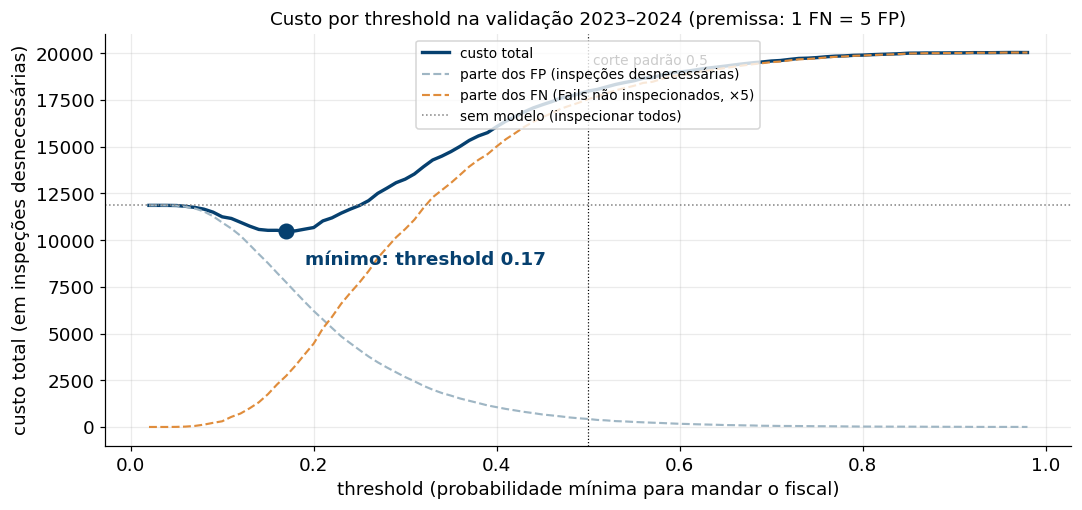

,estratégia,VP,FP,FN,precision,recall,pct_alertas,custo_total,custo vs sem modelo
0,threshold recomendado (0.17),"3,461","7,739",548,30.9%,86.3%,70.6%,"10,479",-11.7%
1,"corte padrão (0,50)",498,428,"3,511",53.8%,12.4%,5.8%,"17,983",+51.6%
2,sem modelo (inspecionar todos),–,–,–,–,–,–,"11,863",+0.0%


In [ ]:
# ── 14 · custo do erro (SÓ validação 2023–2024; o teste já foi usado uma vez na seção 11) ──
# usa y_val, prob_val e metricas_por_threshold() da seção de threshold (Pessoa 3)

CUSTO_FP = 1.0        # 1 inspeção desnecessária = 1 unidade de custo (a moeda da análise)
RAZAO_FN_FP = 5       # premissa central: 1 Fail que não é inspecionado custa o mesmo que 5 inspeções desnecessárias
GRADE_T = np.round(np.arange(0.02, 0.99, 0.01), 2)   # grade mais fina que a da Pessoa 3 (0,1 a 0,9)

def custo_por_threshold(y, prob, razao, custo_fp=CUSTO_FP, thresholds=GRADE_T):
    """Custo total = FP × custo_fp + FN × (razao × custo_fp), para cada threshold."""
    m = metricas_por_threshold(y, prob, thresholds=thresholds)
    m["custo_FP"] = m["FP"] * custo_fp
    m["custo_FN"] = m["FN"] * razao * custo_fp
    m["custo_total"] = m["custo_FP"] + m["custo_FN"]
    return m

def custo_sem_modelo(y, razao, custo_fp=CUSTO_FP):
    """Melhor estratégia sem modelo: inspecionar todos (só FP) ou não priorizar ninguém (só FN)."""
    n_fail = int(np.sum(y))
    todos = (len(y) - n_fail) * custo_fp
    ninguem = n_fail * razao * custo_fp
    return min(todos, ninguem), ("inspecionar todos" if todos <= ninguem else "não priorizar ninguém")

n_val, n_fail_val = len(y_val), int(np.sum(y_val))
custos = custo_por_threshold(y_val, prob_val, RAZAO_FN_FP)
melhor = custos.loc[custos["custo_total"].idxmin()]
T_RECOMENDADO = float(melhor["threshold"])
linha_05 = custos.loc[np.isclose(custos["threshold"], 0.5)].iloc[0]
ref_custo, ref_nome = custo_sem_modelo(y_val, RAZAO_FN_FP)

# ── gráfico: custo por threshold, separado em FP e FN ──
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(custos["threshold"], custos["custo_total"], color="#06406F", lw=2.2, label="custo total")
ax.plot(custos["threshold"], custos["custo_FP"], color="#9FB6C4", lw=1.4, ls="--", label="parte dos FP (inspeções desnecessárias)")
ax.plot(custos["threshold"], custos["custo_FN"], color="#E08D3C", lw=1.4, ls="--", label=f"parte dos FN (Fails não inspecionados, ×{RAZAO_FN_FP})")
ax.axhline(ref_custo, color="gray", lw=1, ls=":", label=f"sem modelo ({ref_nome})")
ax.scatter([T_RECOMENDADO], [melhor["custo_total"]], s=90, color="#06406F", zorder=5)
ax.annotate(f"mínimo: threshold {T_RECOMENDADO:.2f}", (T_RECOMENDADO, melhor["custo_total"]),
            xytext=(12, -22), textcoords="offset points", color="#06406F", fontweight="bold")
ax.axvline(0.5, color="black", lw=.8, ls=":")
ax.text(0.505, ax.get_ylim()[1] * .95, "corte padrão 0,5", fontsize=9, va="top")
ax.set_xlabel("threshold (probabilidade mínima para mandar o fiscal)")
ax.set_ylabel("custo total (em inspeções desnecessárias)")
ax.set_title(f"Custo por threshold na validação 2023–2024 (premissa: 1 FN = {RAZAO_FN_FP} FP)")
ax.legend(fontsize=9, loc="upper center")
plt.tight_layout()
plt.savefig(FIGS / "fi-14-custo-threshold.png", dpi=200, bbox_inches="tight")
plt.show()

# ── threshold recomendado contra o corte padrão e contra não usar modelo ──
comparacao_custo = pd.DataFrame([
    {"estratégia": f"threshold recomendado ({T_RECOMENDADO:.2f})", **melhor[["VP", "FP", "FN", "precision", "recall", "pct_alertas", "custo_total"]].to_dict()},
    {"estratégia": "corte padrão (0,50)", **linha_05[["VP", "FP", "FN", "precision", "recall", "pct_alertas", "custo_total"]].to_dict()},
    {"estratégia": f"sem modelo ({ref_nome})", "custo_total": ref_custo},
])
comparacao_custo["custo vs sem modelo"] = comparacao_custo["custo_total"] / ref_custo - 1
display(comparacao_custo.style.format({
    "VP": "{:,.0f}", "FP": "{:,.0f}", "FN": "{:,.0f}", "precision": "{:.1%}", "recall": "{:.1%}",
    "pct_alertas": "{:.1%}", "custo_total": "{:,.0f}", "custo vs sem modelo": "{:+.1%}"}, na_rep="–"))


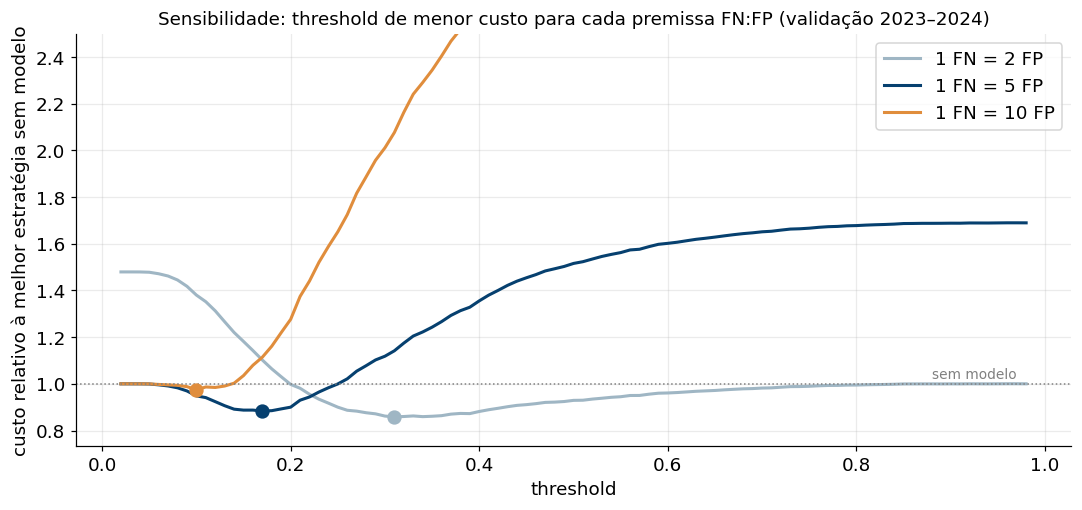

,FN:FP,threshold ótimo,referência teórica 1/(1+r),% de estabelecimentos alertados,precision,recall,FP,FN,custo mínimo,sem modelo,economia vs sem modelo
0,2:1,0.31,0.33,26.7%,42.2%,44.6%,"2,448","2,219","6,886","8,018",14.1%
1,5:1,0.17,0.17,70.6%,30.9%,86.3%,"7,739",548,"10,479","11,863",11.7%
2,10:1,0.10,0.09,93.8%,26.5%,98.5%,"10,946",61,"11,556","11,863",2.6%


Validação: 15,872 inspeções Canvass, 4,009 Fails (25.3%).
Premissa central (1 FN = 5 FP): threshold recomendado = 0.17.
  O fiscal visita 70.6% dos estabelecimentos; de cada 100 visitas, 31 encontram um Fail; de cada 100 Fails, 86 são encontrados.
  Custo 10,479 contra 17,983 no corte 0,5 (41.7% menor) e 11,863 sem modelo (11.7% menor).
Sensibilidade: threshold ótimo = 0.31 (FN:FP 2:1), 0.17 (FN:FP 5:1), 0.10 (FN:FP 10:1).


In [ ]:
# ── análise de sensibilidade: o threshold ideal muda com a premissa FN:FP? ──
RAZOES = [2, 5, 10]
cores_r = {2: "#9FB6C4", 5: "#06406F", 10: "#E08D3C"}

linhas_s, curvas_s = [], {}
for r in RAZOES:
    c = custo_por_threshold(y_val, prob_val, r)
    b = c.loc[c["custo_total"].idxmin()]
    ref_r, nome_r = custo_sem_modelo(y_val, r)
    curvas_s[r] = (c, b, ref_r)
    linhas_s.append({
        "FN:FP": f"{r}:1",
        "threshold ótimo": b["threshold"],
        "referência teórica 1/(1+r)": 1 / (1 + r),   # corte ótimo se as probabilidades fossem bem calibradas
        "% de estabelecimentos alertados": b["pct_alertas"],
        "precision": b["precision"],
        "recall": b["recall"],
        "FP": b["FP"],
        "FN": b["FN"],
        "custo mínimo": b["custo_total"],
        "sem modelo": ref_r,
        "economia vs sem modelo": 1 - b["custo_total"] / ref_r,
    })
sens = pd.DataFrame(linhas_s)

# custo dividido pelo custo sem modelo: as três premissas ficam na mesma escala (1 = o modelo não ajuda)
fig, ax = plt.subplots(figsize=(10, 4.8))
for r, (c, b, ref_r) in curvas_s.items():
    ax.plot(c["threshold"], c["custo_total"] / ref_r, color=cores_r[r], lw=2, label=f"1 FN = {r} FP")
    ax.scatter([b["threshold"]], [b["custo_total"] / ref_r], color=cores_r[r], s=70, zorder=5)
ax.axhline(1, color="gray", lw=1, ls=":")
ax.text(0.97, 1.01, "sem modelo", color="gray", ha="right", va="bottom", fontsize=9)
ax.set_ylim(top=min(ax.get_ylim()[1], 2.5))
ax.set_xlabel("threshold")
ax.set_ylabel("custo relativo à melhor estratégia sem modelo")
ax.set_title("Sensibilidade: threshold de menor custo para cada premissa FN:FP (validação 2023–2024)")
ax.legend()
plt.tight_layout()
plt.savefig(FIGS / "fi-14-sensibilidade.png", dpi=200, bbox_inches="tight")
plt.show()

display(sens.style.format({
    "threshold ótimo": "{:.2f}", "referência teórica 1/(1+r)": "{:.2f}",
    "% de estabelecimentos alertados": "{:.1%}", "precision": "{:.1%}", "recall": "{:.1%}",
    "FP": "{:,.0f}", "FN": "{:,.0f}", "custo mínimo": "{:,.0f}", "sem modelo": "{:,.0f}",
    "economia vs sem modelo": "{:.1%}"}))

# ── números para a conclusão (impressos para não ficarem desatualizados no texto) ──
s5 = sens.loc[sens["FN:FP"].eq(f"{RAZAO_FN_FP}:1")].iloc[0]
print(f"Validação: {n_val:,} inspeções Canvass, {n_fail_val:,} Fails ({n_fail_val / n_val:.1%}).")
print(f"Premissa central (1 FN = {RAZAO_FN_FP} FP): threshold recomendado = {T_RECOMENDADO:.2f}.")
print(f"  O fiscal visita {melhor['pct_alertas']:.1%} dos estabelecimentos; de cada 100 visitas, "
      f"{melhor['precision'] * 100:.0f} encontram um Fail; de cada 100 Fails, {melhor['recall'] * 100:.0f} são encontrados.")
print(f"  Custo {s5['custo mínimo']:,.0f} contra {linha_05['custo_total']:,.0f} no corte 0,5 "
      f"({1 - s5['custo mínimo'] / linha_05['custo_total']:.1%} menor) e {ref_custo:,.0f} sem modelo "
      f"({s5['economia vs sem modelo']:.1%} menor).")
print("Sensibilidade: threshold ótimo = " +
      ", ".join(f"{row['threshold ótimo']:.2f} (FN:FP {row['FN:FP']})" for _, row in sens.iterrows()) + ".")


In [ ]:
# ── conclusão de negócio gerada a partir dos números (assim o texto não fica desatualizado) ──
from IPython.display import Markdown

# formato brasileiro: vírgula decimal, ponto no milhar
def dec(x, d=2): return f"{x:.{d}f}".replace(".", ",")
def pct(x, d=0): return f"{x * 100:.{d}f}%".replace(".", ",")
def mil(x): return f"{x:,.0f}".replace(",", ".")

eco_05 = 1 - melhor["custo_total"] / linha_05["custo_total"]
eco_ref = 1 - melhor["custo_total"] / ref_custo
t_min, t_max = sens["threshold ótimo"].min(), sens["threshold ótimo"].max()
r10 = sens.iloc[-1]
dif_teo = (sens["threshold ótimo"] - sens["referência teórica 1/(1+r)"]).abs().max()

if eco_ref > 0.02:
    frase_ref = (f"Contra a melhor estratégia sem modelo ({ref_nome}), o custo cai {pct(eco_ref, 1)}. "
                 "O ganho existe, mas é modesto, o que bate com a AUC de 0,68: o modelo ordena melhor que o acaso, "
                 "sem separar bem quem vai falhar de quem vai passar.")
else:
    frase_ref = (f"Contra a melhor estratégia sem modelo ({ref_nome}), a diferença é de só {pct(eco_ref, 1)}. "
                 "Com esta premissa, o modelo quase não muda a decisão em relação a não usá-lo.")

frase_teo = ("próximo da referência teórica 1/(1+r), sinal de que as probabilidades da logística estão razoavelmente calibradas"
             if dif_teo <= 0.05 else
             f"com distância de até {dec(dif_teo)} da referência teórica 1/(1+r), sinal de que as probabilidades da logística "
             "estão descalibradas na validação (a taxa de Fail mudou com o tempo, seção 4)")

display(Markdown(f"""
### Conclusão do custo do erro

**Recomendação.** Com a premissa central de que um Fail não inspecionado custa o mesmo que {RAZAO_FN_FP} inspeções desnecessárias, o threshold de menor custo na validação 2023–2024 é **{dec(T_RECOMENDADO)}**, e não 0,5. Nesse corte o fiscal visita {pct(melhor['pct_alertas'])} dos estabelecimentos da fila. De cada 100 visitas, {melhor['precision'] * 100:.0f} encontram um Fail, e de cada 100 estabelecimentos que falhariam, {melhor['recall'] * 100:.0f} são visitados.

**Quanto custa errar.** No corte padrão de 0,5 o modelo alerta só {pct(linha_05['pct_alertas'])} dos estabelecimentos e deixa passar {mil(linha_05['FN'])} Fails, o que é caro quando o FN pesa {RAZAO_FN_FP} vezes mais. Mudar para {dec(T_RECOMENDADO)} troca esses Fails não encontrados por mais visitas desnecessárias ({mil(melhor['FP'])} FP) e reduz o custo total em {pct(eco_05)}. {frase_ref}

**Sensibilidade.** O threshold ideal depende diretamente da premissa: vai de {dec(t_max)} (1 FN = 2 FP) a {dec(t_min)} (1 FN = 10 FP), {frase_teo}. Quanto mais grave a vigilância considerar deixar passar um Fail, mais baixo o corte e mais estabelecimentos são visitados. Com 1 FN = 10 FP, o modelo manda visitar {pct(r10['% de estabelecimentos alertados'])} da fila e a economia contra a melhor estratégia sem modelo cai para {pct(r10['economia vs sem modelo'], 1)}: quando o FN é muito caro, a resposta tende a "inspecionar quase todo mundo", e o modelo serve menos para escolher quem visitar e mais para decidir a ordem das visitas.

**Limites.** Os custos são hipóteses declaradas, não dados do dataset, e a escolha da proporção FN:FP é uma decisão da vigilância sanitária, não do modelo. A análise também não considera a capacidade real de fiscais: se a equipe só consegue visitar uma parte da fila, o corte passa a ser definido pela capacidade, e o modelo é usado para ordenar quem vem primeiro (os {melhor['precision'] * 100:.0f}% de acerto valem para o corte {dec(T_RECOMENDADO)}; um corte mais alto concentra os Fails). O threshold foi escolhido só na validação. O teste já foi usado na seção 11, então a confirmação precisa de inspeções posteriores a 23/09/2026.
"""))



### Conclusão do custo do erro

**Recomendação.** Com a premissa central de que um Fail não inspecionado custa o mesmo que 5 inspeções desnecessárias, o threshold de menor custo na validação 2023–2024 é **0,17**, e não 0,5. Nesse corte o fiscal visita 71% dos estabelecimentos da fila. De cada 100 visitas, 31 encontram um Fail, e de cada 100 estabelecimentos que falhariam, 86 são visitados.

**Quanto custa errar.** No corte padrão de 0,5 o modelo alerta só 6% dos estabelecimentos e deixa passar 3.511 Fails, o que é caro quando o FN pesa 5 vezes mais. Mudar para 0,17 troca esses Fails não encontrados por mais visitas desnecessárias (7.739 FP) e reduz o custo total em 42%. Contra a melhor estratégia sem modelo (inspecionar todos), o custo cai 11,7%. O ganho existe, mas é modesto, o que bate com a AUC de 0,68: o modelo ordena melhor que o acaso, sem separar bem quem vai falhar de quem vai passar.

**Sensibilidade.** O threshold ideal depende diretamente da premissa: vai de 0,31 (1 FN = 2 FP) a 0,10 (1 FN = 10 FP), próximo da referência teórica 1/(1+r), sinal de que as probabilidades da logística estão razoavelmente calibradas. Quanto mais grave a vigilância considerar deixar passar um Fail, mais baixo o corte e mais estabelecimentos são visitados. Com 1 FN = 10 FP, o modelo manda visitar 94% da fila e a economia contra a melhor estratégia sem modelo cai para 2,6%: quando o FN é muito caro, a resposta tende a "inspecionar quase todo mundo", e o modelo serve menos para escolher quem visitar e mais para decidir a ordem das visitas.

**Limites.** Os custos são hipóteses declaradas, não dados do dataset, e a escolha da proporção FN:FP é uma decisão da vigilância sanitária, não do modelo. A análise também não considera a capacidade real de fiscais: se a equipe só consegue visitar uma parte da fila, o corte passa a ser definido pela capacidade, e o modelo é usado para ordenar quem vem primeiro (os 31% de acerto valem para o corte 0,17; um corte mais alto concentra os Fails). O threshold foi escolhido só na validação. O teste já foi usado na seção 11, então a confirmação precisa de inspeções posteriores a 23/09/2026.
